# Zadanie 2: Predikcia koncentrácie CO

Cieľom je odhadnúť hodinovú koncentráciu oxidu uhoľnatého **`co` v mg/m³**. Ide o **regresiu**, preto hodnotím MSE, RMSE a R², nie klasifikačnú presnosť. Postup nadväzuje na úlohu 01: načítanie a EDA → čistenie → rozdelenie a predspracovanie → GridSearchCV → porovnanie a interpretácia → rozširujúce experimenty.

Riešenie obsahuje rozhodovací strom, Random Forest, XGBoost, SVR, ExtraTrees a histogramový gradient boosting, 3D vizualizáciu PCA, tri spôsoby výberu príznakov, zhlukovanie a regresnú neurónovú sieť. V PDF sa miestami uvádza `count`; pre tento dataset tým rozumiem výstup **`co`**.

**Pravidlá experimentu:** finálny test tvorí 20 % dát s pevným seedom 2026. Modely a hyperparametre vyberám podľa krížovej validácie na zvyšných 80 %. Test nepoužívam na ladenie. Transformácie a štatistické odstránenie odľahlých tréningových záznamov sa učia osobitne v každom CV folde. Výstup neškálujem. Náhodné rozdelenie hodnotí interpoláciu v sledovanom období; pri hodinových meraniach môže byť optimistickejšie než predikcia budúceho obdobia.

## Prostredie a reprodukovateľnosť

Notebook používa kernel **Python (ml-course)** rovnako ako úloha 01. Potrebuje numpy, pandas, scipy, scikit-learn, matplotlib, seaborn, xgboost a torch. Vypíšem skutočné verzie, seed a veľkosť prehľadávaných mriežok. Všetky dôležité výsledky a grafy sa ukladajú aj do výstupu notebooku; súhrnné tabuľky a obrázky stromov do `results/`.

In [1]:
import copy
import json
import os
import random
import time
from pathlib import Path
from importlib.metadata import version

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
from joblib import parallel_backend
from threadpoolctl import threadpool_limits
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold, ParameterGrid, train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, silhouette_score
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
import torch
from torch import nn

SEED = 2026
N_JOBS = 2
CV_FOLDS = 3
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
sns.set_theme(style="whitegrid", palette="viridis", context="notebook")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.max_colwidth", 100)
versions = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn", "xgboost", "torch"]}
display(pd.Series(versions, name="Verzia").to_frame())
print(f"Seed: {SEED}; klasická CV: {CV_FOLDS} foldy; najviac {N_JOBS} súbežné úlohy; PyTorch: CPU.")

,Verzia
numpy,2.5.1
pandas,3.0.3
scipy,1.18.0
scikit-learn,1.9.0
matplotlib,3.11.0
seaborn,0.13.2
xgboost,3.4.1
torch,2.14.1


Seed: 2026; klasická CV: 3 foldy; najviac 2 súbežné úlohy; PyTorch: CPU.


# Dáta a prieskumná analýza
## Načítanie a význam stĺpcov

`instant` je identifikátor, `date` označuje deň merania. Päť senzorov poskytuje odozvy bez fyzikálnej jednotky; nejde o priamo zmerané koncentrácie jednotlivých plynov. `co` pochádza z referenčného analyzátora. Teplota je v °C a relatívna vlhkosť v %. Dátum nebudem kódovať stovkami one-hot stĺpcov: časovú informáciu už obsahujú mesiac, hodina, deň v týždni a sezóna.

In [2]:
data = pd.read_csv("air_quality.csv")
SENSORS = ["sensor_co", "sensor_nmhc", "sensor_nox", "sensor_no2", "sensor_o3"]
CONTINUOUS = SENSORS + ["temperature", "humidity"]
TARGET = "co"
assert set(["instant", "date", "month", "hour", "weekday", "season", *CONTINUOUS, TARGET]) == set(data.columns)
display(data.head())
display(data.describe().T.round(3))
display(Markdown(
    f"Načítal som **{len(data):,} riadkov a {data.shape[1]} stĺpcov**. "
    f"Merania pokrývajú obdobie **{data.date.min()} až {data.date.max()}**. "
    "Minimum, maximum a kvartily pomáhajú odlíšiť bežnú variabilitu od možnej chyby; "
    "samotná vysoká koncentrácia CO ešte nie je chybný záznam."
))

,instant,date,month,hour,weekday,season,sensor_co,sensor_nmhc,sensor_nox,sensor_no2,sensor_o3,temperature,humidity,co
0,1,2004-03-10,3,18,3,spring,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,2.6
1,2,2004-03-10,3,19,3,spring,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,2.0
2,3,2004-03-10,3,20,3,spring,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,2.2
3,4,2004-03-10,3,21,3,spring,1376.0,948.0,1092.0,1584.0,1203.0,11.0,60.0,2.2
4,5,2004-03-10,3,22,3,spring,1272.0,836.0,1205.0,1490.0,1110.0,11.2,59.6,1.6


,count,mean,std,min,25%,50%,75%,max
instant,9507.0,4681.998,2700.183,1.0,2345.5,4683.0,7016.5,9357.0
month,9507.0,6.317,3.439,1.0,3.0,6.0,9.0,12.0
hour,9507.0,11.505,6.926,0.0,5.5,12.0,18.0,23.0
weekday,9507.0,3.004,2.003,0.0,1.0,3.0,5.0,6.0
sensor_co,9139.0,1099.538,217.088,647.0,936.0,1063.0,1231.0,2040.0
sensor_nmhc,9139.0,938.890,266.843,383.0,734.0,909.0,1117.0,2214.0
sensor_nox,9139.0,835.881,257.021,322.0,658.0,806.0,969.5,2683.0
sensor_no2,9139.0,1455.835,346.719,551.0,1224.5,1463.0,1674.0,2775.0
sensor_o3,9139.0,1022.488,398.597,221.0,731.0,962.0,1274.0,2523.0
temperature,9139.0,18.325,8.842,-1.9,11.8,17.8,24.4,44.6


Načítal som **9,507 riadkov a 14 stĺpcov**. Merania pokrývajú obdobie **2004-03-10 až 2005-04-04**. Minimum, maximum a kvartily pomáhajú odlíšiť bežnú variabilitu od možnej chyby; samotná vysoká koncentrácia CO ešte nie je chybný záznam.

## Kvalita dát
### Chýbajúce hodnoty, duplicity a platnosť

Chýbajúci cieľ nemožno doplniť bez vymyslenia správnej odpovede. Podľa zadania preto odstraňujem riadky s NA, nie imputáciu. Duplicity skontrolujem ešte pred rozdelením, aby rovnaké meranie neskončilo v tréningu aj teste. Pri dátume overím parsovanie a súlad s mesiacom a dňom v týždni. Uvedené rozsahy senzorov v PDF sú približné, preto ich nepoužívam ako tvrdé limity.

,Typ,NA,Unikátne
instant,int64,0,9357
date,str,0,391
month,int64,0,12
hour,int64,0,24
weekday,int64,0,7
season,str,0,4
sensor_co,float64,368,1041
sensor_nmhc,float64,368,1245
sensor_nox,float64,368,1221
sensor_no2,float64,368,1603


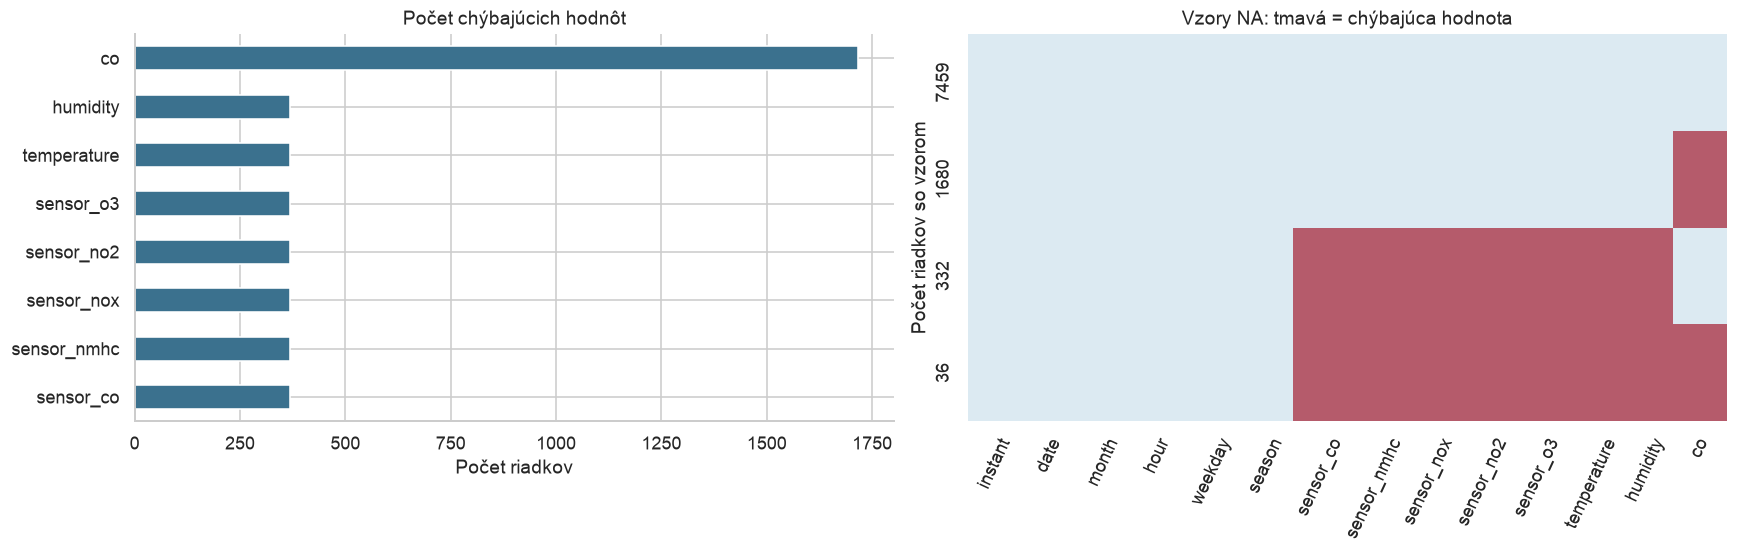

Dataset obsahuje **150 úplných duplicít**; bez identifikátora je ich 150. Cieľ chýba v **1716 riadkoch**. Spoločné vzory chýbania senzorov naznačujú výpadky merania; z dostupných dát nemožno zaručiť, že odstránené riadky sú náhodným výberom. Výsledky preto platia pre úplné merania.

In [3]:
missing = data.isna().sum().sort_values(ascending=False)
quality = pd.DataFrame({"Typ": data.dtypes.astype(str), "NA": data.isna().sum(), "Unikátne": data.nunique()})
display(quality)
patterns = data.isna().value_counts().rename("Počet").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.7), constrained_layout=True)
missing[missing > 0].sort_values().plot.barh(ax=axes[0], color="#3b718e")
axes[0].set(title="Počet chýbajúcich hodnôt", xlabel="Počet riadkov")
sns.heatmap(patterns[data.columns].astype(int), cmap=["#dceaf2", "#b55b6b"], cbar=False,
            yticklabels=patterns["Počet"], ax=axes[1])
axes[1].set(title="Vzory NA: tmavá = chýbajúca hodnota", ylabel="Počet riadkov so vzorom")
axes[1].tick_params(axis="x", rotation=65)
plt.show()
duplicate_count = int(data.duplicated().sum())
without_id_dups = int(data.drop(columns="instant").duplicated().sum())
display(Markdown(
    f"Dataset obsahuje **{duplicate_count} úplných duplicít**; bez identifikátora je ich {without_id_dups}. "
    f"Cieľ chýba v **{data.co.isna().sum()} riadkoch**. "
    "Spoločné vzory chýbania senzorov naznačujú výpadky merania; z dostupných dát nemožno "
    "zaručiť, že odstránené riadky sú náhodným výberom. Výsledky preto platia pre úplné merania."
))

In [4]:
unique_data = data.drop_duplicates().copy()
complete_data = unique_data.dropna().copy()
dates = pd.to_datetime(complete_data.date, errors="coerce")
valid = (
    dates.notna()
    & complete_data.month.between(1, 12)
    & complete_data.hour.between(0, 23)
    & complete_data.weekday.between(0, 6)
    & complete_data.season.isin(["winter", "spring", "summer", "autumn"])
    & complete_data.humidity.between(0, 100)
    & complete_data.temperature.between(-30, 60)
    & complete_data.co.ge(0)
    & complete_data[SENSORS].gt(0).all(axis=1)
    & complete_data[CONTINUOUS + [TARGET]].apply(np.isfinite).all(axis=1)
    & complete_data.month.eq(dates.dt.month)
    & complete_data.weekday.eq((dates.dt.dayofweek + 1) % 7)
)
data_clean = complete_data.loc[valid].copy()
cleaning = pd.DataFrame([
    ["Pôvodné údaje", len(data), 0],
    ["Po odstránení duplicít", len(unique_data), len(data) - len(unique_data)],
    ["Po odstránení NA", len(complete_data), len(unique_data) - len(complete_data)],
    ["Po kontrole platnosti", len(data_clean), int((~valid).sum())],
], columns=["Krok", "Zostáva", "Odstránené v kroku"])
display(cleaning)
assert not data_clean.isna().any().any() and not data_clean.duplicated().any()
display(Markdown(
    f"Po čistení zostalo **{len(data_clean):,} úplných a platných meraní** "
    f"({len(data_clean)/len(data):.1%} pôvodných riadkov). "
    "Teploty nad približných 40 °C automaticky nemažem: stále môžu byť reálnym meraním. "
    "Štatistické outliery odstránim až z tréningových dát pomocou hraníc naučených výhradne na danom tréningu."
))

,Krok,Zostáva,Odstránené v kroku
0,Pôvodné údaje,9507,0
1,Po odstránení duplicít,9357,150
2,Po odstránení NA,7344,2013
3,Po kontrole platnosti,7344,0


Po čistení zostalo **7,344 úplných a platných meraní** (77.2% pôvodných riadkov). Teploty nad približných 40 °C automaticky nemažem: stále môžu byť reálnym meraním. Štatistické outliery odstránim až z tréningových dát pomocou hraníc naučených výhradne na danom tréningu.

## Rozdelenia senzorov a koncentrácie
### Histogramy a boxploty

Histogram ukazuje tvar rozdelenia a boxplot medián, kvartily a odľahlé body. Boxplot používa bežné fúzy 1,5 × IQR len na vizualizáciu; pravidlo pre odstránenie tréningových outlierov bude konzervatívnejšie, 3 × IQR. CO do tohto odstraňovania nezahrniem, aby som hodnotenie nezjednodušil vymazaním vysokých cieľových hodnôt.

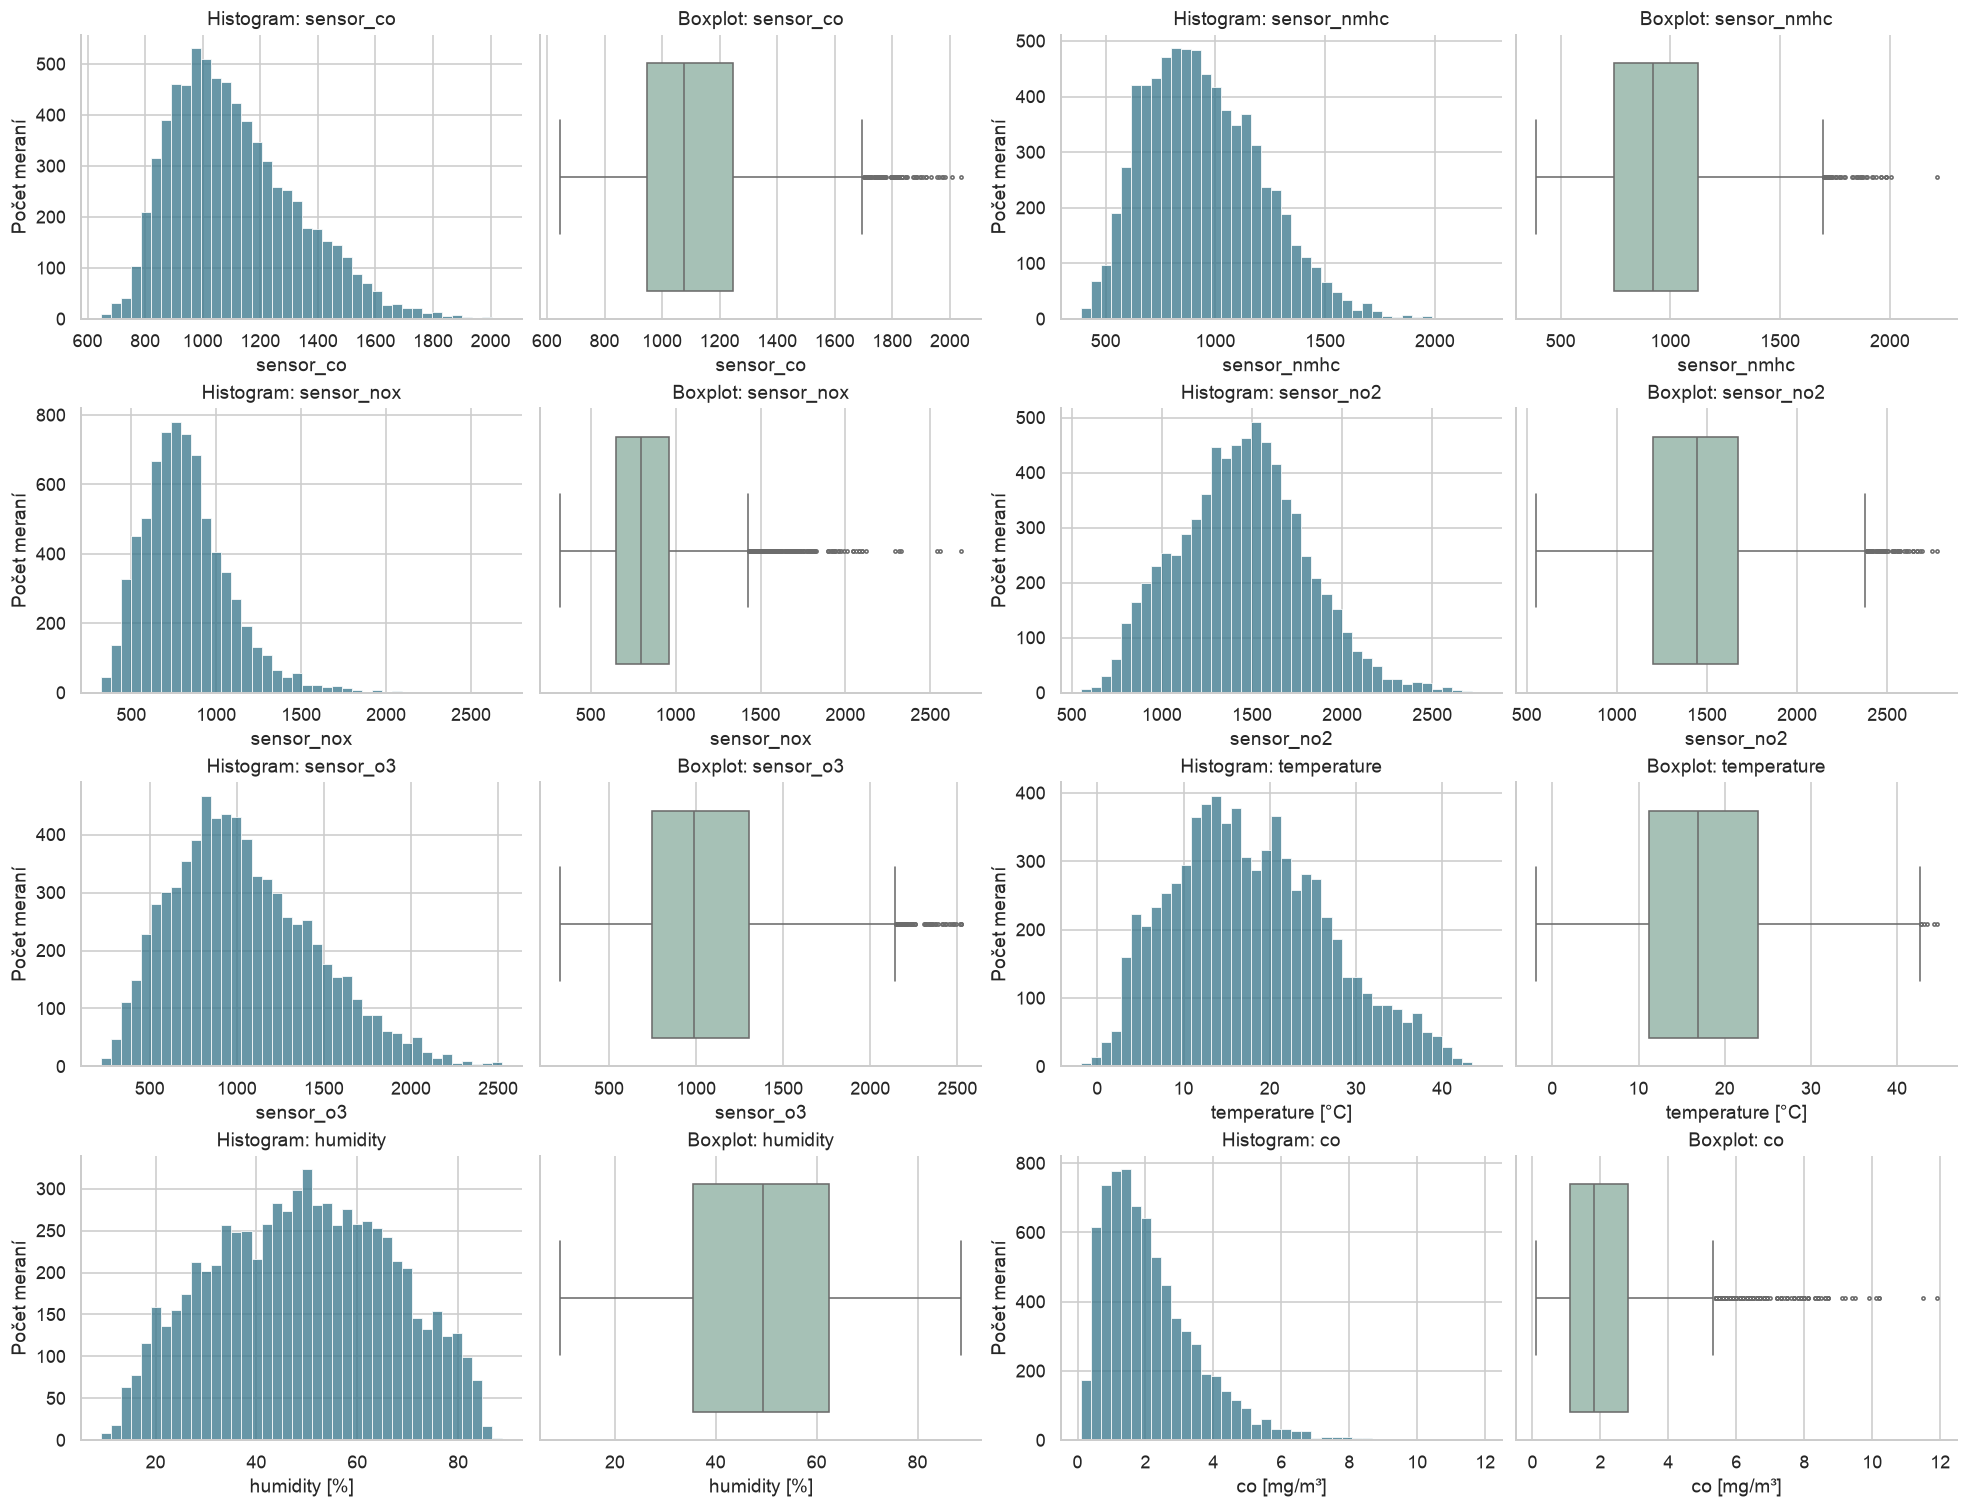

CO má medián **1.80 mg/m³**, priemer 2.13 mg/m³ a výberovú šikmosť **1.36**. Dlhší pravý chvost znamená menej časté vysoké koncentrácie. MSE tieto veľké chyby silno penalizuje. Senzor NOx dosahuje maximum 2683; odľahlosť v grafe sama nepreukazuje poruchu.

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(17, 13), constrained_layout=True)
for row, column in enumerate(CONTINUOUS + [TARGET]):
    ax_hist, ax_box = axes.reshape(8, 2)[row]
    sns.histplot(data_clean[column], bins=40, ax=ax_hist, color="#36758a")
    sns.boxplot(x=data_clean[column], ax=ax_box, color="#a1c6b7", fliersize=2)
    unit = " [mg/m³]" if column == TARGET else " [°C]" if column == "temperature" else " [%]" if column == "humidity" else ""
    ax_hist.set(title=f"Histogram: {column}", xlabel=column + unit, ylabel="Počet meraní")
    ax_box.set(title=f"Boxplot: {column}", xlabel=column + unit)
plt.show()
co_skew = data_clean.co.skew()
display(Markdown(
    f"CO má medián **{data_clean.co.median():.2f} mg/m³**, priemer {data_clean.co.mean():.2f} mg/m³ "
    f"a výberovú šikmosť **{co_skew:.2f}**. "
    "Dlhší pravý chvost znamená menej časté vysoké koncentrácie. MSE tieto veľké chyby silno penalizuje. "
    f"Senzor NOx dosahuje maximum {data_clean.sensor_nox.max():.0f}; odľahlosť v grafe sama nepreukazuje poruchu."
))

## Súvislosti a časový priebeh
### Korelácie a závislosť od hodiny

Pearsonova korelácia zachytáva lineárny vzťah, Spearmanova monotónne usporiadanie. Korelácia neznamená príčinnosť. Pri časových priemeroch ide o opis dostupných úplných meraní, nie o reprezentatívny odhad všetkých hodín v roku. EDA nižšie neslúži na výber modelu či hyperparametrov; výber príznakov neskôr prebieha iba v tréningu.

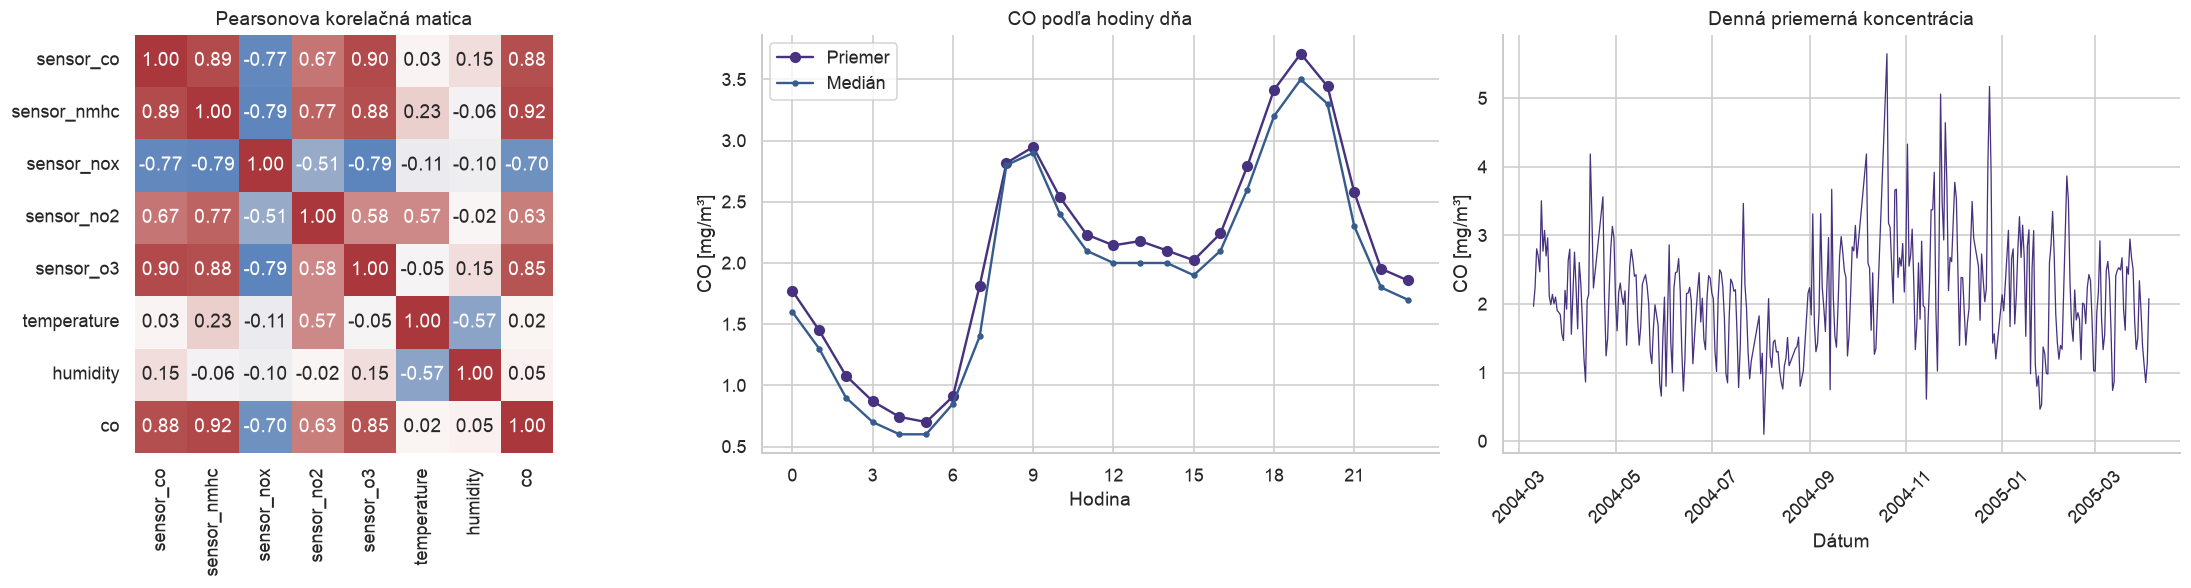

Najsilnejšiu absolútnu Pearsonovu koreláciu s CO má **sensor_nmhc**, r = 0.916; Spearmanovo ρ = 0.927. Najvyšší hodinový priemer je o **19:00** (3.71 mg/m³), najnižší o 5:00 (0.70 mg/m³). Rozdiely sú zlučiteľné s denným cyklom emisií, ale bez údajov o doprave a počasí z grafu nemožno potvrdiť jeho príčinu. Denný priebeh ukazuje aj časovú závislosť, ktorú obyčajné náhodné rozdelenie úplne neodstraňuje.

In [6]:
eda_corr = data_clean[CONTINUOUS + [TARGET]].corr()
hourly = data_clean.groupby("hour").co.agg(["mean", "median", "count"])
daily = data_clean.assign(date=pd.to_datetime(data_clean.date)).groupby("date").co.mean()
fig, axes = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)
sns.heatmap(eda_corr, annot=True, fmt=".2f", center=0, cmap="vlag", square=True, cbar=False, ax=axes[0])
axes[0].set_title("Pearsonova korelačná matica")
axes[1].plot(hourly.index, hourly["mean"], marker="o", label="Priemer")
axes[1].plot(hourly.index, hourly["median"], marker=".", label="Medián")
axes[1].set(title="CO podľa hodiny dňa", xlabel="Hodina", ylabel="CO [mg/m³]", xticks=range(0,24,3))
axes[1].legend()
axes[2].plot(daily.index, daily.values, linewidth=.8)
axes[2].set(title="Denná priemerná koncentrácia", xlabel="Dátum", ylabel="CO [mg/m³]")
axes[2].tick_params(axis="x", rotation=45)
plt.show()
strongest = eda_corr.co.drop(TARGET).abs().idxmax()
spearman = data_clean[CONTINUOUS + [TARGET]].corr(method="spearman").loc[strongest, TARGET]
display(Markdown(
    f"Najsilnejšiu absolútnu Pearsonovu koreláciu s CO má **{strongest}**, "
    f"r = {eda_corr.loc[strongest,TARGET]:.3f}; Spearmanovo ρ = {spearman:.3f}. "
    f"Najvyšší hodinový priemer je o **{hourly['mean'].idxmax()}:00** "
    f"({hourly['mean'].max():.2f} mg/m³), najnižší o {hourly['mean'].idxmin()}:00 "
    f"({hourly['mean'].min():.2f} mg/m³). Rozdiely sú zlučiteľné s denným cyklom emisií, "
    "ale bez údajov o doprave a počasí z grafu nemožno potvrdiť jeho príčinu. Denný priebeh ukazuje "
    "aj časovú závislosť, ktorú obyčajné náhodné rozdelenie úplne neodstraňuje."
))

# Príprava regresného experimentu
## Rozdelenie vstupov a výstupu

Použijem jedno rozdelenie **80 % tréning / 20 % test**. Tréning zahŕňa aj vnútorné CV foldy, preto samostatnú vonkajšiu validačnú množinu nepotrebujem. Seed 2026 je stanovený pred týmto experimentom. `instant` a `date` sa do modelov nedostanú. Rovnaké testovacie riadky zachovám aj pri redukcii príznakov a zhlukovaní.

In [7]:
train_data, test_data = train_test_split(data_clean, test_size=0.20, random_state=SEED)
FEATURES = [c for c in data_clean if c not in ["instant", "date", TARGET]]
X_train = train_data[FEATURES].copy()
X_test = test_data[FEATURES].copy()
y_train = train_data[TARGET].copy()
y_test = test_data[TARGET].copy()
assert set(train_data.instant).isdisjoint(set(test_data.instant))
assert TARGET not in X_train and "instant" not in X_train and "date" not in X_train
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
display(pd.DataFrame({"Počet": [len(y_train),len(y_test)],
                      "Priemer CO": [y_train.mean(),y_test.mean()],
                      "SD CO": [y_train.std(),y_test.std()]}, index=["Tréning", "Test"]).round(4))
display(Markdown(
    f"Tréning obsahuje **{len(X_train)}** a test **{len(X_test)}** meraní. "
    "Rozdelenie je náhodné bez stratifikácie regresného cieľa. Porovnanie priemerov je opisné; "
    "nerozhodujem podľa neho o zmene seedu ani pomeru. Testovacie outliery ponechávam, "
    "aby sa náročné merania nestratili zo záverečného hodnotenia."
))

,Počet,Priemer CO,SD CO
Tréning,5875,2.1212,1.4356
Test,1469,2.1636,1.4398


Tréning obsahuje **5875** a test **1469** meraní. Rozdelenie je náhodné bez stratifikácie regresného cieľa. Porovnanie priemerov je opisné; nerozhodujem podľa neho o zmene seedu ani pomeru. Testovacie outliery ponechávam, aby sa náročné merania nestratili zo záverečného hodnotenia.

## Kódovanie a normalizácia
### Cyklické kalendárne premenné

Mesiac, hodinu a deň v týždni prevediem na sínus a kosínus. Susedné hodnoty 23 a 0 hodín tak zostanú blízko aj v kódovaní. Sezóna má iba štyri kategórie, preto použijem one-hot kódovanie. Dátum nepridáva stovky stĺpcov. Po kódovaní štandardizujem **všetky vstupy**, vrátane one-hot stĺpcov, aby PCA a vzdialenostné modely neovládla pôvodná mierka senzorov. Cieľ `co` nemením.

```text
sin_t = sin(2πt / T),  cos_t = cos(2πt / T)
z = (x − μ_tréning) / σ_tréning
```

### Odstránenie odľahlých tréningových záznamov

Pre sedem spojitých vstupov použijem hranice `[Q₁ − 3 × IQR, Q₃ + 3 × IQR]`, kde `IQR = Q₃ − Q₁`. Záznam odstránim, ak mimo nich leží aspoň jeden vstup. Kvartily sa učia pri každom `fit` iba z príslušného tréningového foldu. CO ani diskrétne časové stĺpce nefiltrované podľa IQR. Pri `predict` sa neodstraňuje žiadny riadok. Toto pravidlo obmedzuje vplyv extrémov, ale nie je dôkazom ich chybnosti.

In [8]:
class CalendarEncoder(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        out = X.copy()
        for column, period in [("month", 12), ("hour", 24), ("weekday", 7)]:
            out[column + "_sin"] = np.sin(2 * np.pi * out[column] / period)
            out[column + "_cos"] = np.cos(2 * np.pi * out[column] / period)
            out = out.drop(columns=column)
        return out

CYCLIC = [f"{c}_{suffix}" for c in ["month", "hour", "weekday"] for suffix in ["sin", "cos"]]
NUMERIC = CONTINUOUS + CYCLIC
preprocessor = ColumnTransformer([
    ("numeric", "passthrough", NUMERIC),
    ("season", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["season"]),
], verbose_feature_names_out=False)

class OutlierFilteredRegressor(RegressorMixin, BaseEstimator):
    """Odstráni iba tréningové outliery; pri predikcii zachová všetky riadky."""
    def __init__(self, estimator, factor=3.0):
        self.estimator = estimator
        self.factor = factor

    def fit(self, X, y):
        q1 = X[CONTINUOUS].quantile(.25)
        q3 = X[CONTINUOUS].quantile(.75)
        iqr = q3 - q1
        self.bounds_ = pd.DataFrame({"Dolná hranica": q1-self.factor*iqr, "Horná hranica": q3+self.factor*iqr})
        keep = X[CONTINUOUS].ge(self.bounds_["Dolná hranica"]).all(axis=1) & X[CONTINUOUS].le(self.bounds_["Horná hranica"]).all(axis=1)
        self.inlier_mask_ = keep.to_numpy()
        self.n_removed_ = int((~keep).sum())
        self.removed_index_ = X.index[~keep]
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.estimator_ = clone(self.estimator)
        self.estimator_.fit(X.loc[keep], np.asarray(y)[self.inlier_mask_])
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

def make_pipeline(model, selector=None):
    return OutlierFilteredRegressor(Pipeline([
        ("calendar", CalendarEncoder()),
        ("preprocessing", clone(preprocessor)),
        ("scale", StandardScaler()),
        ("selection", "passthrough" if selector is None else selector),
        ("model", clone(model)),
    ]))

preparation_demo = make_pipeline(DummyRegressor()).fit(X_train, y_train)
inliers = preparation_demo.inlier_mask_
X_train_in = X_train.iloc[np.flatnonzero(inliers)]
y_train_in = y_train.iloc[np.flatnonzero(inliers)]
display(preparation_demo.bounds_.round(3))
encoded_names = preparation_demo.estimator_.named_steps["preprocessing"].get_feature_names_out()
display(Markdown(
    f"Na celom vonkajšom tréningu pravidlo odstraňuje **{preparation_demo.n_removed_} riadkov**; "
    f"model sa učí na **{inliers.sum()} meraniach**. Test zostáva so všetkými {len(X_test)} riadkami. "
    f"Kódovaním vzniká **{len(encoded_names)} vstupov** namiesto stoviek dátumových kategórií. "
    "Tréningové metriky nižšie počítam na celom pôvodnom tréningu vrátane filtrovaných bodov, "
    "aby výsledok neskrýval chyby na odstránených extrémoch."
))

,Dolná hranica,Horná hranica
sensor_co,43.0,2143.0
sensor_nmhc,-400.0,2267.0
sensor_nox,-288.0,1903.0
sensor_no2,-204.5,3082.0
sensor_o3,-944.0,2983.0
temperature,-26.2,61.3
humidity,-44.3,141.9


Na celom vonkajšom tréningu pravidlo odstraňuje **23 riadkov**; model sa učí na **5852 meraniach**. Test zostáva so všetkými 1469 riadkami. Kódovaním vzniká **17 vstupov** namiesto stoviek dátumových kategórií. Tréningové metriky nižšie počítam na celom pôvodnom tréningu vrátane filtrovaných bodov, aby výsledok neskrýval chyby na odstránených extrémoch.

# Regresné modely a GridSearchCV
## Kritériá hodnotenia a porovnateľnosť

Reziduál definujem ako skutočná mínus predpovedaná koncentrácia. Kladný reziduál znamená podhodnotenie, záporný nadhodnotenie.

```text
eᵢ = yᵢ − ŷᵢ
MSE = (1/n) ∑ᵢ eᵢ²
RMSE = √MSE
R² = 1 − ∑ᵢ eᵢ² / ∑ᵢ (yᵢ − ȳ)²
```

MSE má jednotku `(mg/m³)²`, RMSE a MAE `mg/m³`; R² je bezrozmerné a môže byť záporné. Neuvádzam ho v percentách. Model vyberiem podľa najnižšej priemernej **CV MSE**; R² slúži aj na požadovanú kontrolu zadania. CV smerodajná odchýlka je variabilita medzi foldmi, nie interval spoľahlivosti. Baseline predikuje tréningový priemer.

## Mriežky parametrov
### Stromy, súborové modely a SVR

Pri strome ladím hĺbku a minimálny počet vzoriek v liste. Random Forest priemeruje bootstrapové stromy, ExtraTrees navyše náhodne volí prahy. XGBoost a histogramový boosting pridávajú stromy postupne na opravu predchádzajúcich chýb. Pri SVR volím regresnú verziu SVM s RBF jadrom, penalizáciou C, šírkou jadra gamma a toleranciou epsilon. Uvádzam ladené aj dôležité pevné parametre. Žiadny ďalší model nemusí predchádzajúce prekonať; rozhodnú namerané výsledky.

In [9]:
model_configs = {
    "DecisionTree": (DecisionTreeRegressor(random_state=SEED), {
        "max_depth": [4, 8, 12, None], "min_samples_leaf": [2, 8, 20]}),
    "RandomForest": (RandomForestRegressor(n_estimators=200, n_jobs=1, random_state=SEED), {
        "max_depth": [12, None], "max_features": [.7, 1.0], "min_samples_leaf": [1, 3]}),
    "XGBoost": (XGBRegressor(objective="reg:squarederror", tree_method="hist", n_jobs=1,
                            subsample=.85, colsample_bytree=.9, random_state=SEED), {
        "n_estimators": [200, 400], "max_depth": [3, 5], "learning_rate": [.05, .1], "reg_lambda": [1., 5.]}),
    "SVR": (SVR(kernel="rbf", cache_size=400), {
        "C": [10., 100.], "gamma": ["scale", .01, .1], "epsilon": [.05, .1]}),
    "ExtraTrees": (ExtraTreesRegressor(n_estimators=200, n_jobs=1, random_state=SEED), {
        "max_features": [.7, 1.0], "min_samples_leaf": [1, 3]}),
    "HistGradientBoosting": (HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=SEED), {
        "learning_rate": [.05, .1], "max_leaf_nodes": [15, 31], "l2_regularization": [0., 1.]}),
}
for name, (model, grid) in model_configs.items():
    print(f"{name}: {len(ParameterGrid(grid))} konfigurácií, {CV_FOLDS*len(ParameterGrid(grid))} CV tréningov")
    print("  Mriežka:", grid)
    fixed = {k: model.get_params()[k] for k in ["n_estimators", "kernel", "max_iter", "subsample", "colsample_bytree", "random_state"] if k in model.get_params()}
    print("  Dôležité pevné parametre:", fixed)

SCORING = {"mse": "neg_mean_squared_error", "r2": "r2"}
searches, trained_models, cv_rows = {}, {}, []
for name, (model, grid) in model_configs.items():
    start = time.perf_counter()
    search = GridSearchCV(make_pipeline(model),
        {"estimator__model__"+key: value for key, value in grid.items()},
        scoring=SCORING, refit="mse", cv=cv, n_jobs=N_JOBS,
        return_train_score=True, error_score="raise")
    with parallel_backend("threading"), threadpool_limits(limits=1):
        search.fit(X_train, y_train)
    searches[name] = search
    trained_models[name] = search.best_estimator_
    index = search.best_index_
    cv_rows.append({"Model": name,
                    "CV MSE": -search.best_score_,
                    "CV RMSE": np.sqrt(-search.best_score_),
                    "CV R²": search.cv_results_["mean_test_r2"][index],
                    "CV SD MSE": search.cv_results_["std_test_mse"][index],
                    "Čas [s]": time.perf_counter()-start})
    print(name, "hotovo; CV RMSE =", round(np.sqrt(-search.best_score_),4), flush=True)
cv_results = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV MSE")
BEST_NAME = cv_results.index[0]
best_model = trained_models[BEST_NAME]
best_base_estimator = clone(best_model.estimator_.named_steps["model"])
display(cv_results.round(4))
display(Markdown(
    f"Pred otvorením testovacích výsledkov vyberám **{BEST_NAME}** podľa CV MSE "
    f"{cv_results.loc[BEST_NAME, 'CV MSE']:.4f}. Jeho CV RMSE je "
    f"{cv_results.loc[BEST_NAME, 'CV RMSE']:.4f} mg/m³. "
    "Tento model a jeho hyperparametre ďalej nemením podľa testovacieho poradia."
))

DecisionTree: 12 konfigurácií, 36 CV tréningov
  Mriežka: {'max_depth': [4, 8, 12, None], 'min_samples_leaf': [2, 8, 20]}
  Dôležité pevné parametre: {'random_state': 2026}
RandomForest: 8 konfigurácií, 24 CV tréningov
  Mriežka: {'max_depth': [12, None], 'max_features': [0.7, 1.0], 'min_samples_leaf': [1, 3]}
  Dôležité pevné parametre: {'n_estimators': 200, 'random_state': 2026}
XGBoost: 16 konfigurácií, 48 CV tréningov
  Mriežka: {'n_estimators': [200, 400], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1], 'reg_lambda': [1.0, 5.0]}
  Dôležité pevné parametre: {'n_estimators': None, 'subsample': 0.85, 'colsample_bytree': 0.9, 'random_state': 2026}
SVR: 12 konfigurácií, 36 CV tréningov
  Mriežka: {'C': [10.0, 100.0], 'gamma': ['scale', 0.01, 0.1], 'epsilon': [0.05, 0.1]}
  Dôležité pevné parametre: {'kernel': 'rbf', 'max_iter': -1}
ExtraTrees: 4 konfigurácií, 12 CV tréningov
  Mriežka: {'max_features': [0.7, 1.0], 'min_samples_leaf': [1, 3]}
  Dôležité pevné parametre: {'n_estimator

DecisionTree hotovo; CV RMSE = 0.4843


RandomForest hotovo; CV RMSE = 0.3872


XGBoost hotovo; CV RMSE = 0.3583


SVR hotovo; CV RMSE = 0.3234


ExtraTrees hotovo; CV RMSE = 0.3602


HistGradientBoosting hotovo; CV RMSE = 0.3544


,CV MSE,CV RMSE,CV R²,CV SD MSE,Čas [s]
Model,,,,,
SVR,0.1046,0.3234,0.9492,0.0063,72.5150
HistGradientBoosting,0.1256,0.3544,0.9388,0.0070,16.9809
XGBoost,0.1284,0.3583,0.9376,0.0076,4.4212
ExtraTrees,0.1297,0.3602,0.9370,0.0095,12.4420
RandomForest,0.1499,0.3872,0.9272,0.0088,33.0748
DecisionTree,0.2346,0.4843,0.8860,0.0099,1.1443


Pred otvorením testovacích výsledkov vyberám **SVR** podľa CV MSE 0.1046. Jeho CV RMSE je 0.3234 mg/m³. Tento model a jeho hyperparametre ďalej nemením podľa testovacieho poradia.

## Výsledky najlepších konfigurácií
### Parametre, generalizácia a baseline

Pre každý typ modelu zobrazím najlepšiu aj najhoršiu konfiguráciu podľa CV. Tréningové aj testovacie výsledky patria vždy najlepšej CV konfigurácii daného typu. Vyššie tréningové R² pri zhoršení testovacieho výsledku naznačuje preučenie. Rozdiel medzi tréningom a testom závisí aj od konkrétneho rozdelenia dát.

### DecisionTree

Najlepšie parametre: {'max_depth': 8, 'min_samples_leaf': 8}
Najhoršie CV parametre: {'estimator__model__max_depth': None, 'estimator__model__min_samples_leaf': 2}
Najhoršia CV MSE: 0.292


,params,mean_train_mse,mean_test_mse,std_test_mse,mean_test_r2,rank_test_mse
0,"{'estimator__model__max_depth': 8, 'estimator__model__min_samples_leaf': 8}",0.1310,0.2346,0.0099,0.8860,1
1,"{'estimator__model__max_depth': 8, 'estimator__model__min_samples_leaf': 20}",0.1592,0.2352,0.0133,0.8857,2
2,"{'estimator__model__max_depth': 12, 'estimator__model__min_samples_leaf': 20}",0.1538,0.2353,0.0139,0.8857,3


,MSE,RMSE,MAE,R²
Množina,,,,
Tréning,0.1404,0.3747,0.2509,0.9319
Test,0.2007,0.4480,0.3004,0.9031


**DecisionTree** má tréningové R² **0.9319** a testovacie R² **0.9031**. Testovacia RMSE je **0.4480 mg/m³**, MAE 0.3004 mg/m³. Rozdiel tréningového a testovacieho R² je 0.0288. Rozdiel je menší než pri výrazne preučených súborových modeloch; zostávajúcu chybu treba hodnotiť aj z reziduálov.

...

Najlepšie parametre: {'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_leaf_nodes': 15}
Najhoršie CV parametre: {'estimator__model__l2_regularization': 1.0, 'estimator__model__learning_rate': 0.05, 'estimator__model__max_leaf_nodes': 15}
Najhoršia CV MSE: 0.131


,params,mean_train_mse,mean_test_mse,std_test_mse,mean_test_r2,rank_test_mse
0,"{'estimator__model__l2_regularization': 0.0, 'estimator__model__learning_rate': 0.1, 'estimator_...",0.0402,0.1256,0.0070,0.9388,1
1,"{'estimator__model__l2_regularization': 1.0, 'estimator__model__learning_rate': 0.1, 'estimator_...",0.0411,0.1257,0.0065,0.9388,2
2,"{'estimator__model__l2_regularization': 0.0, 'estimator__model__learning_rate': 0.1, 'estimator_...",0.0167,0.1282,0.0063,0.9377,3


,MSE,RMSE,MAE,R²
Množina,,,,
Tréning,0.0488,0.2208,0.1544,0.9763
Test,0.1210,0.3478,0.2283,0.9416


**HistGradientBoosting** má tréningové R² **0.9763** a testovacie R² **0.9416**. Testovacia RMSE je **0.3478 mg/m³**, MAE 0.2283 mg/m³. Rozdiel tréningového a testovacieho R² je 0.0347. Rozdiel je menší než pri výrazne preučených súborových modeloch; zostávajúcu chybu treba hodnotiť aj z reziduálov.

MSE            RMSE              R²        
Množina                 Test Tréning    Test Tréning    Test Tréning
Model                                                               
Baseline              2.0731  2.0607  1.4398  1.4355 -0.0007 -0.0000
DecisionTree          0.2007  0.1404  0.4480  0.3747  0.9031  0.9319
ExtraTrees            0.1216  0.0000  0.3486  0.0035  0.9413  1.0000
HistGradientBoosting  0.1210  0.0488  0.3478  0.2208  0.9416  0.9763
RandomForest          0.1402  0.0190  0.3744  0.1380  0.9323  0.9908
SVR                   0.0947  0.0350  0.3077  0.1870  0.9543  0.9830
XGBoost               0.1204  0.0429  0.3470  0.2072  0.9419  0.9792

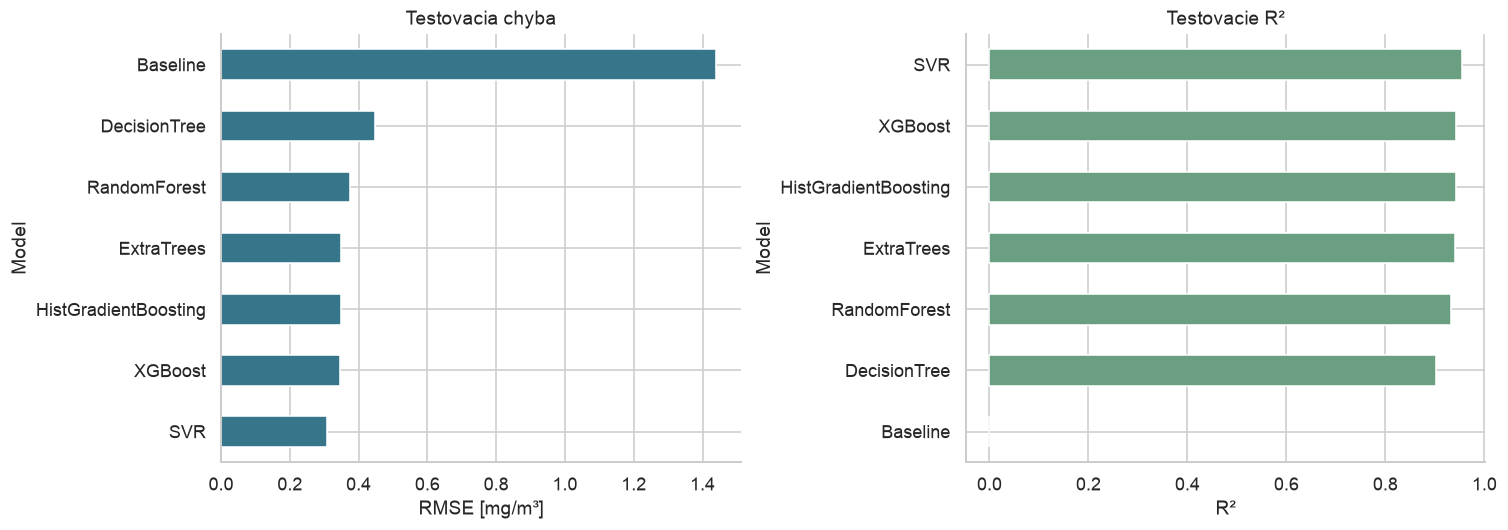

CV víťaz **SVR** dosiahol na teste **R² = 0.9543**, RMSE = **0.3077 mg/m³**. Opisne najnižšiu testovaciu MSE má SVR; týmto údajom výber nemením. Baseline má RMSE 1.4398 mg/m³. Stĺpce ukazujú porovnanie na totožných riadkoch; menšie RMSE a vyššie R² znamenajú lepší výsledok.

In [10]:
def regression_metrics(y, prediction):
    return {"MSE": float(mean_squared_error(y, prediction)),
            "RMSE": float(np.sqrt(mean_squared_error(y, prediction))),
            "MAE": float(mean_absolute_error(y, prediction)),
            "R²": float(r2_score(y, prediction))}

def evaluate_model(name, model):
    return [{"Model": name, "Množina": label, **regression_metrics(y, model.predict(X))}
            for label, X, y in [("Tréning", X_train, y_train), ("Test", X_test, y_test)]]

metric_rows = []
for name, search in searches.items():
    display(Markdown(f"### {name}"))
    params = {k.replace("estimator__model__", ""): v for k,v in search.best_params_.items()}
    print("Najlepšie parametre:", params)
    details = pd.DataFrame(search.cv_results_)
    worst_i = details.mean_test_mse.idxmin()
    print("Najhoršie CV parametre:", details.loc[worst_i,"params"])
    print("Najhoršia CV MSE:", round(-details.loc[worst_i,"mean_test_mse"],4))
    table = details[["params", "mean_train_mse", "mean_test_mse", "std_test_mse", "mean_test_r2", "rank_test_mse"]].copy()
    table["mean_train_mse"] *= -1
    table["mean_test_mse"] *= -1
    display(table.sort_values("rank_test_mse").head(3).reset_index(drop=True).round(4))
    model = trained_models[name]
    rows = evaluate_model(name, model)
    metric_rows.extend(rows)
    display(pd.DataFrame(rows).drop(columns="Model").set_index("Množina").round(4))
    train_m, test_m = rows
    display(Markdown(
        f"**{name}** má tréningové R² **{train_m['R²']:.4f}** a testovacie R² **{test_m['R²']:.4f}**. "
        f"Testovacia RMSE je **{test_m['RMSE']:.4f} mg/m³**, MAE {test_m['MAE']:.4f} mg/m³. "
        f"Rozdiel tréningového a testovacieho R² je {train_m['R²']-test_m['R²']:.4f}. "
        + ("Takmer nulová tréningová chyba pri nenulovej testovacej ukazuje silné zapamätanie tréningových meraní." if train_m['MSE'] < .01*test_m['MSE'] else "Rozdiel upozorňuje na preučenie oproti prispôsobeniu tréningu." if train_m['R²']-test_m['R²'] > .04 else "Rozdiel je menší než pri výrazne preučených súborových modeloch; zostávajúcu chybu treba hodnotiť aj z reziduálov.")
    ))
    details.to_csv(RESULTS / f"grid_{name}.csv", index=False)

baseline = make_pipeline(DummyRegressor(strategy="mean")).fit(X_train, y_train)
metric_rows.extend(evaluate_model("Baseline", baseline))
metrics = pd.DataFrame(metric_rows)
metric_table = metrics.pivot(index="Model", columns="Množina", values=["MSE", "RMSE", "R²"])
display(metric_table.round(4))
test_metrics = metrics[metrics.Množina.eq("Test")].set_index("Model")
metrics.to_csv(RESULTS / "model_metrics.csv", index=False)
cv_results.to_csv(RESULTS / "cv_summary.csv")
fig, axes = plt.subplots(1, 2, figsize=(13,4.5), constrained_layout=True)
test_metrics.RMSE.sort_values().plot.barh(ax=axes[0], color="#36758a")
axes[0].set(title="Testovacia chyba", xlabel="RMSE [mg/m³]")
test_metrics["R²"].sort_values().plot.barh(ax=axes[1], color="#6a9f81")
axes[1].set(title="Testovacie R²", xlabel="R²")
plt.show()
display(Markdown(
    f"CV víťaz **{BEST_NAME}** dosiahol na teste **R² = {test_metrics.loc[BEST_NAME,'R²']:.4f}**, "
    f"RMSE = **{test_metrics.loc[BEST_NAME,'RMSE']:.4f} mg/m³**. "
    f"Opisne najnižšiu testovaciu MSE má {test_metrics.MSE.idxmin()}; týmto údajom výber nemením. "
    f"Baseline má RMSE {test_metrics.loc['Baseline','RMSE']:.4f} mg/m³. "
    "Stĺpce ukazujú porovnanie na totožných riadkoch; menšie RMSE a vyššie R² znamenajú lepší výsledok."
))

## Diagnostika reziduálov
### Reziduál oproti predikcii a rozdelenie chýb

Na zvislej osi bodových grafov je **reziduál**, nie očakávaná koncentrácia. Ideálne body tvoria pás okolo nuly bez krivky či lievika. Histogram porovnáva chyby v tréningu a teste. Všetky modely kreslím s rovnakou mierkou reziduálov, aby porovnanie neskreslili osi.

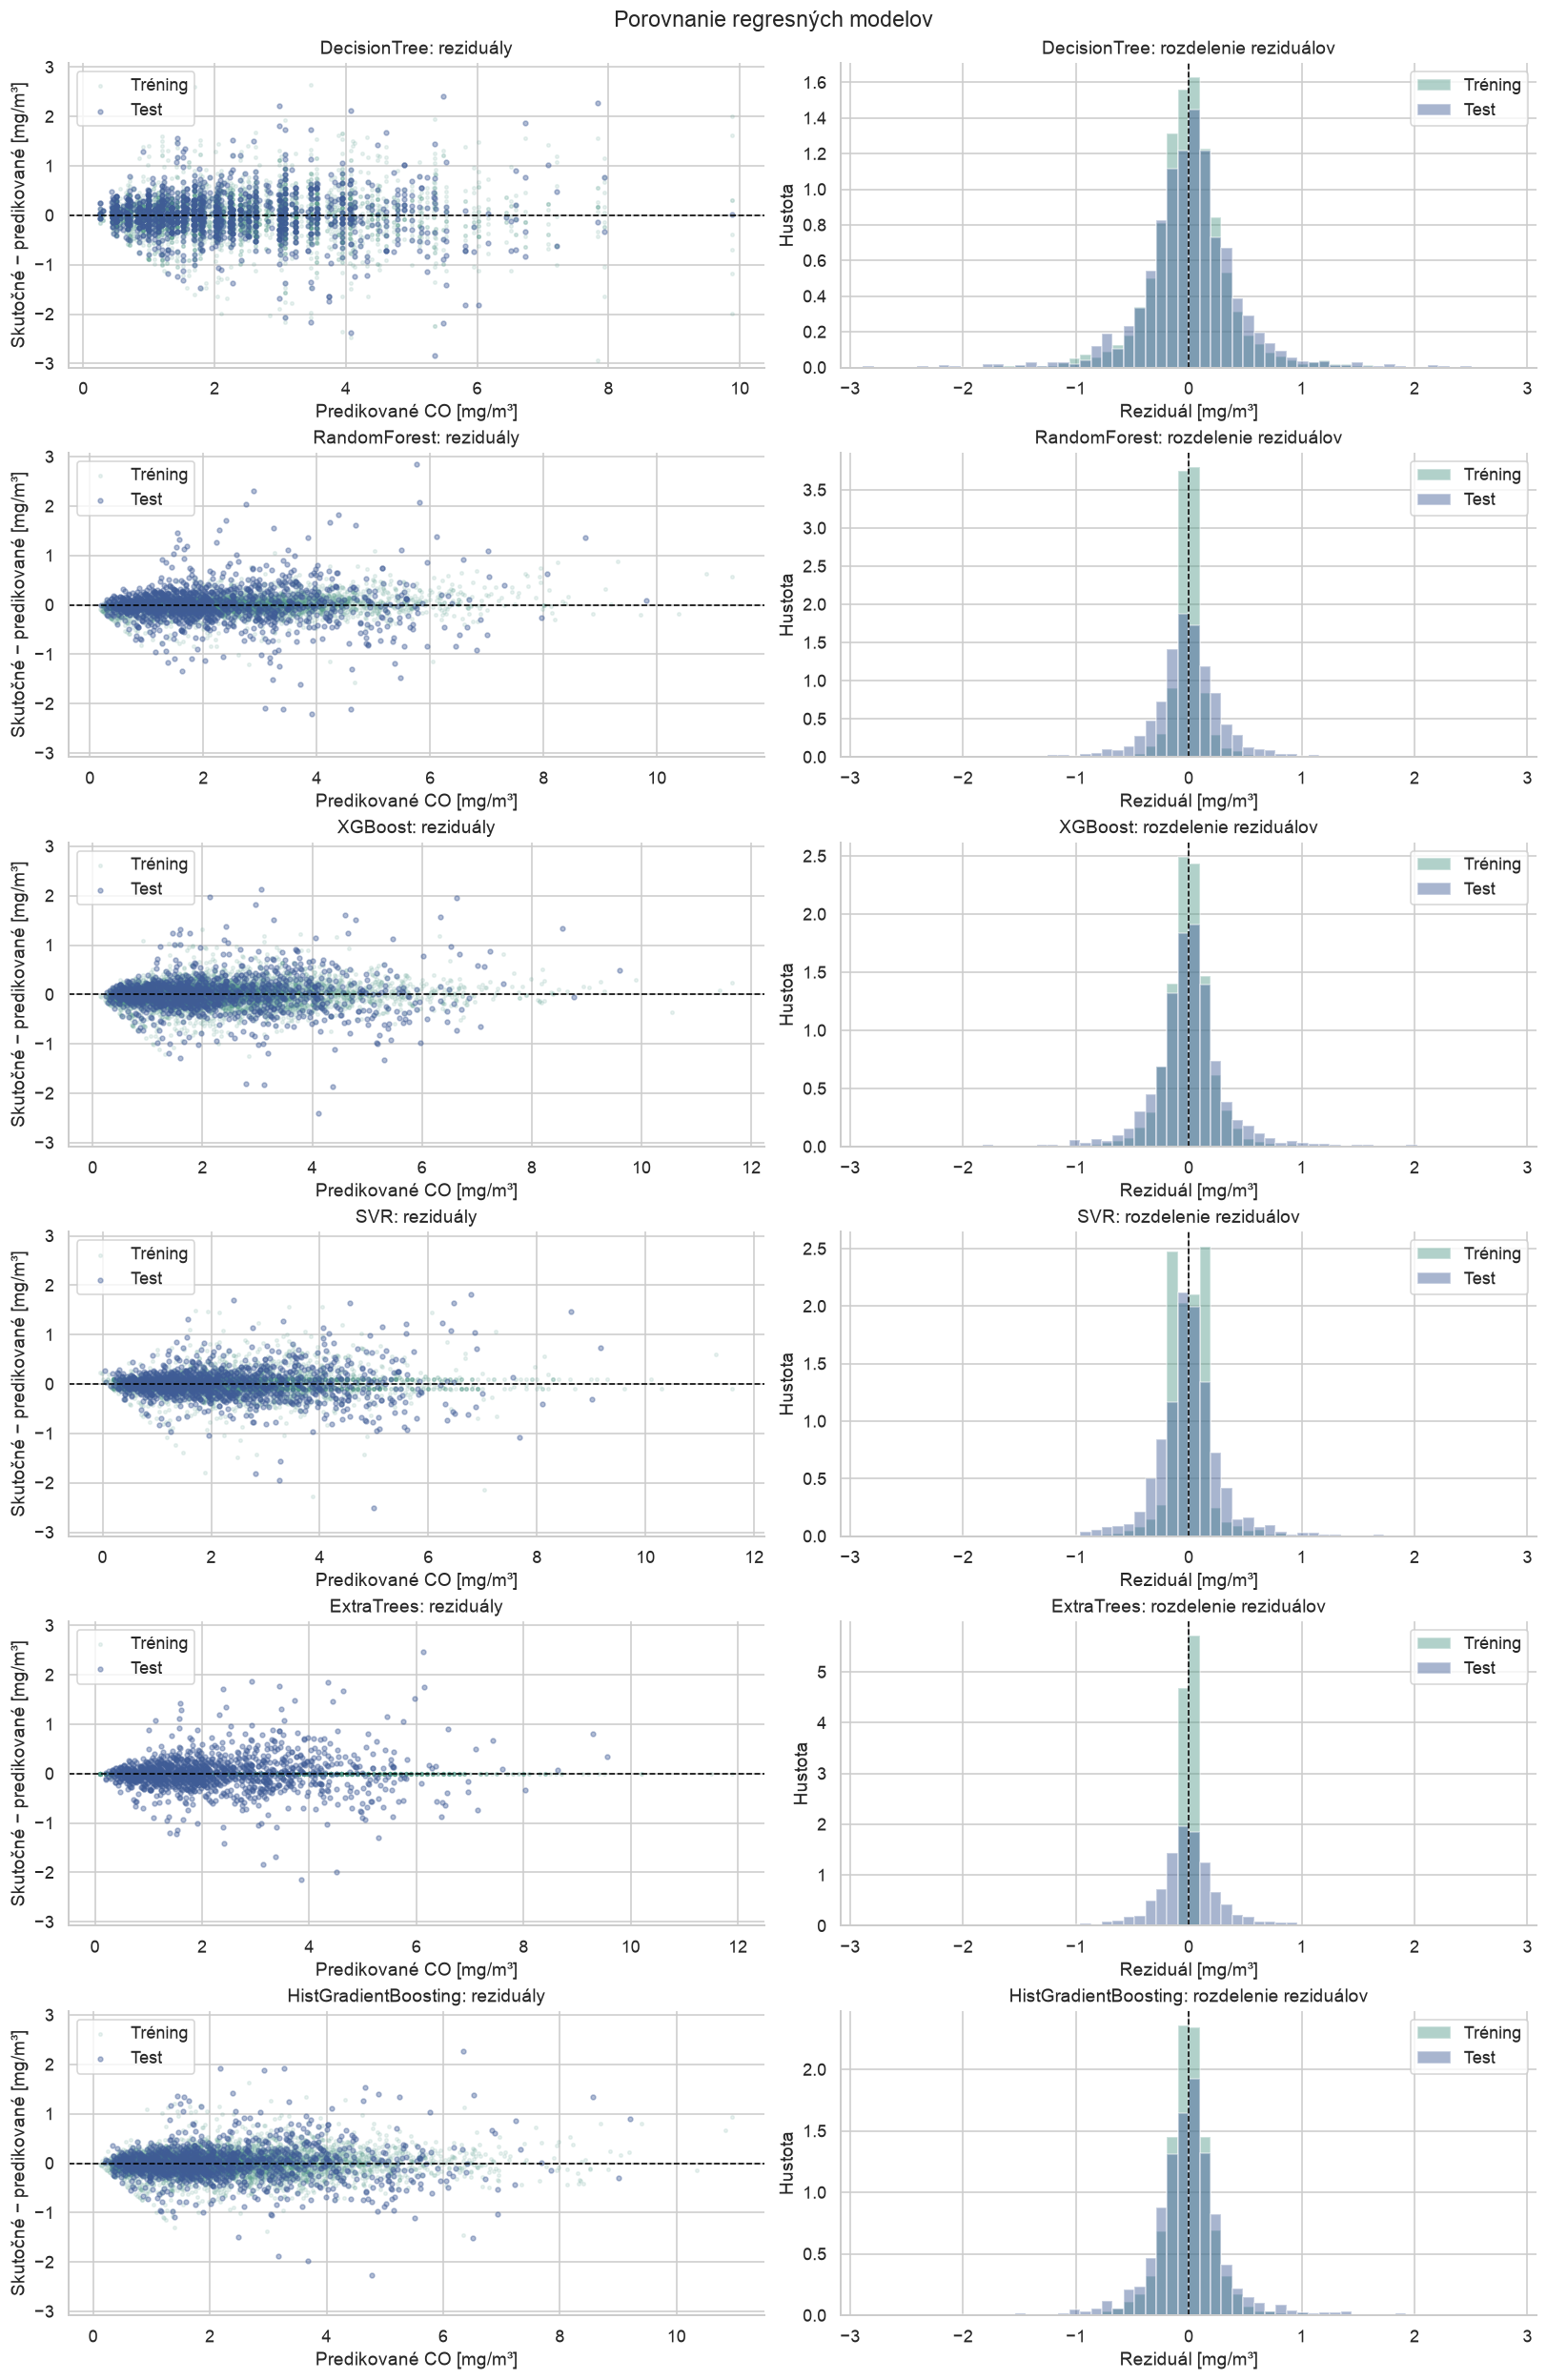

,Priemer reziduála,Medián reziduála,95. percentil |e|,Korelácia |e| a predikcie
Model,,,,
DecisionTree,0.0116,0.0125,0.8701,0.3486
RandomForest,0.0048,-0.0060,0.7453,0.3463
XGBoost,0.0059,0.0022,0.7190,0.3496
SVR,0.0019,-0.0040,0.6502,0.4270
ExtraTrees,0.0026,-0.0115,0.7079,0.3557
HistGradientBoosting,0.0033,0.0028,0.7279,0.3460


**DecisionTree:** priemerný testovací reziduál 0.0116 mg/m³ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.870 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.349; chyby majú tendenciu rásť s predikovanou koncentráciou.

**RandomForest:** priemerný testovací reziduál 0.0048 mg/m³ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.745 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.346; chyby majú tendenciu rásť s predikovanou koncentráciou.

**XGBoost:** priemerný testovací reziduál 0.0059 mg/m³ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.719 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.350; chyby majú tendenciu rásť s predikovanou koncentráciou.

**SVR:** priemerný testovací reziduál 0.0019 mg/m³ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.650 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.427; chyby majú tendenciu rásť s predikovanou koncentráciou.

**ExtraTrees:** priemerný testovací reziduál 0.0026 mg/m³ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.708 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.356; chyby majú tendenciu rásť s predikovanou koncentráciou.

**HistGradientBoosting:** priemerný testovací reziduál 0.0033 mg/m³ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.728 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.346; chyby majú tendenciu rásť s predikovanou koncentráciou.

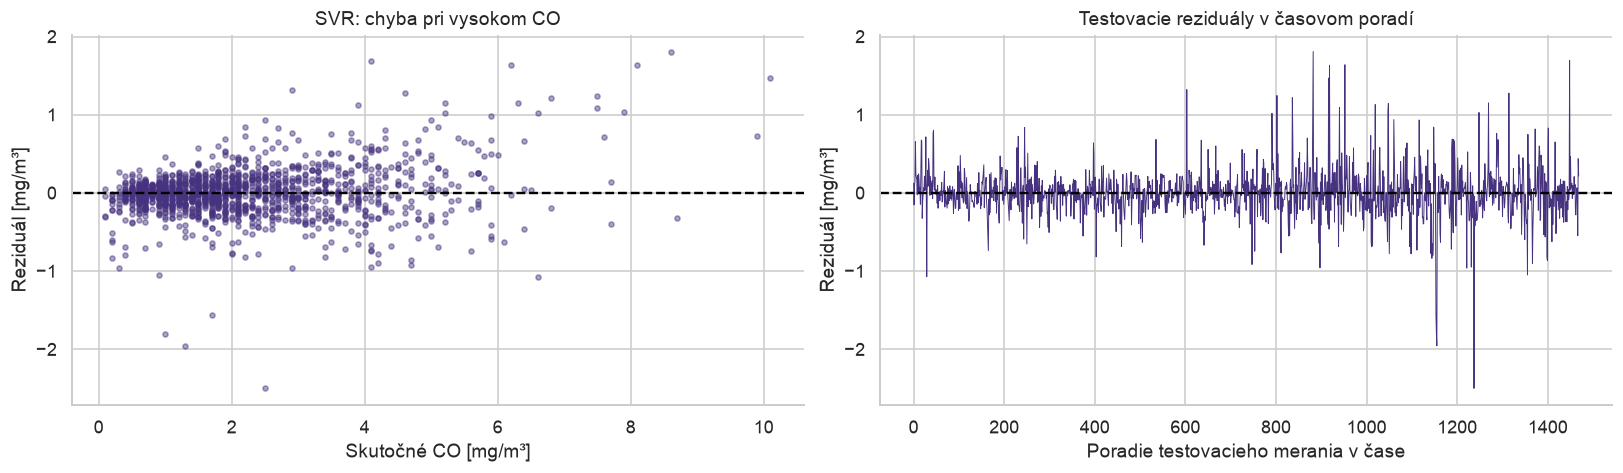

Pri skutočnom CO aspoň **4.00 mg/m³** (hranica z tréningu) je priemerný reziduál 0.137 mg/m³ na 182 testovacích bodoch. Tým priamo kontrolujem podhodnocovanie vysokých koncentrácií. Časový graf ukazuje poradie vybraných testovacích hodín; vzdialenosť bodov na osi nie je rovnaký časový odstup. Nulový priemer reziduálov sám nezaručuje, že sú chyby nezávislé alebo normálne rozdelené.

In [11]:
def residual_summary(name, y, prediction):
    e = np.asarray(y) - np.asarray(prediction)
    return {"Model": name, "Priemer reziduála": float(e.mean()),
            "Medián reziduála": float(np.median(e)), "95. percentil |e|": float(np.quantile(np.abs(e), .95)),
            "Korelácia |e| a predikcie": float(np.corrcoef(np.abs(e), prediction)[0,1])}

def plot_residuals(models, title, filename=None):
    fig, axes = plt.subplots(len(models), 2, figsize=(14,3.6*len(models)), squeeze=False, constrained_layout=True)
    limit = max(np.max(np.abs(np.asarray(y)-model.predict(X))) for model in models.values() for X,y in [(X_train,y_train),(X_test,y_test)])*1.05
    summaries=[]
    for row,(name,model) in enumerate(models.items()):
        train_pred, test_pred = model.predict(X_train), model.predict(X_test)
        train_e, test_e = np.asarray(y_train)-train_pred, np.asarray(y_test)-test_pred
        axes[row,0].scatter(train_pred,train_e,s=5,alpha=.12,label="Tréning",color="#539b8a")
        axes[row,0].scatter(test_pred,test_e,s=9,alpha=.4,label="Test",color="#3f5c96")
        axes[row,0].axhline(0,color="black",linestyle="--",linewidth=1)
        axes[row,0].set(title=name+": reziduály",xlabel="Predikované CO [mg/m³]",ylabel="Skutočné − predikované [mg/m³]",ylim=(-limit,limit))
        axes[row,0].legend(loc="upper left")
        for e,label,color in [(train_e,"Tréning","#539b8a"),(test_e,"Test","#3f5c96")]:
            axes[row,1].hist(e,bins=np.linspace(-limit,limit,65),density=True,alpha=.45,label=label,color=color)
        axes[row,1].axvline(0,color="black",linestyle="--",linewidth=1)
        axes[row,1].set(title=name+": rozdelenie reziduálov",xlabel="Reziduál [mg/m³]",ylabel="Hustota",xlim=(-limit,limit))
        axes[row,1].legend()
        summaries.append(residual_summary(name,y_test,test_pred))
    fig.suptitle(title)
    if filename:fig.savefig(RESULTS/filename,dpi=150,bbox_inches="tight")
    plt.show()
    table=pd.DataFrame(summaries).set_index("Model")
    display(table.round(4))
    for name,row in table.iterrows():
        display(Markdown(
            f"**{name}:** priemerný testovací reziduál {row['Priemer reziduála']:.4f} mg/m³ "
            f"znamená {'podhodnotenie' if row['Priemer reziduála']>0 else 'nadhodnotenie'} v priemere. "
            f"95 % absolútnych chýb neprekračuje **{row['95. percentil |e|']:.3f} mg/m³**. "
            f"Korelácia veľkosti chyby s predikciou je {row['Korelácia |e| a predikcie']:.3f}; "
            + ("chyby majú tendenciu rásť s predikovanou koncentráciou." if row['Korelácia |e| a predikcie']>.2 else "silný rast chyby s predikovanou koncentráciou táto súhrnná hodnota nepotvrdzuje.")
        ))
    return table

residual_table = plot_residuals(trained_models,"Porovnanie regresných modelov")
# Dodatočne kontrolujem skreslenie pri vysokom skutočnom CO a časové usporiadanie testu.
best_test_pred = best_model.predict(X_test)
best_test_residual = np.asarray(y_test)-best_test_pred
high_threshold = float(y_train.quantile(.90))
high = y_test.to_numpy() >= high_threshold
order = np.argsort(pd.to_datetime(test_data.date).to_numpy()+pd.to_timedelta(test_data.hour,unit="h").to_numpy())
fig,axes=plt.subplots(1,2,figsize=(14,4),constrained_layout=True)
axes[0].scatter(y_test,best_test_residual,s=10,alpha=.45)
axes[0].axhline(0,color="black",linestyle="--")
axes[0].set(title=f"{BEST_NAME}: chyba pri vysokom CO",xlabel="Skutočné CO [mg/m³]",ylabel="Reziduál [mg/m³]")
axes[1].plot(np.arange(len(order)),best_test_residual[order],linewidth=.6)
axes[1].axhline(0,color="black",linestyle="--")
axes[1].set(title="Testovacie reziduály v časovom poradí",xlabel="Poradie testovacieho merania v čase",ylabel="Reziduál [mg/m³]")
plt.show()
display(Markdown(
    f"Pri skutočnom CO aspoň **{high_threshold:.2f} mg/m³** (hranica z tréningu) je "
    f"priemerný reziduál {best_test_residual[high].mean():.3f} mg/m³ na {high.sum()} testovacích bodoch. "
    "Tým priamo kontrolujem podhodnocovanie vysokých koncentrácií. Časový graf ukazuje poradie "
    "vybraných testovacích hodín; vzdialenosť bodov na osi nie je rovnaký časový odstup. "
    "Nulový priemer reziduálov sám nezaručuje, že sú chyby nezávislé alebo normálne rozdelené."
))

## Vizualizácia stromov
### Malý rozhodovací strom v pôvodných jednotkách

Pre čitateľnosť natrénujem samostatný ilustračný strom s hĺbkou 3 a minimálne 30 meraniami v liste. Použijem sedem pôvodných spojitých vstupov bez škálovania, aby prahy mali zrozumiteľné jednotky. Jeho parametre a výsledok sú odlíšené od ladeného stromu. V liste `value` znamená priemerné CO a `squared_error` priemernú štvorcovú odchýlku cieľa v danom uzle.

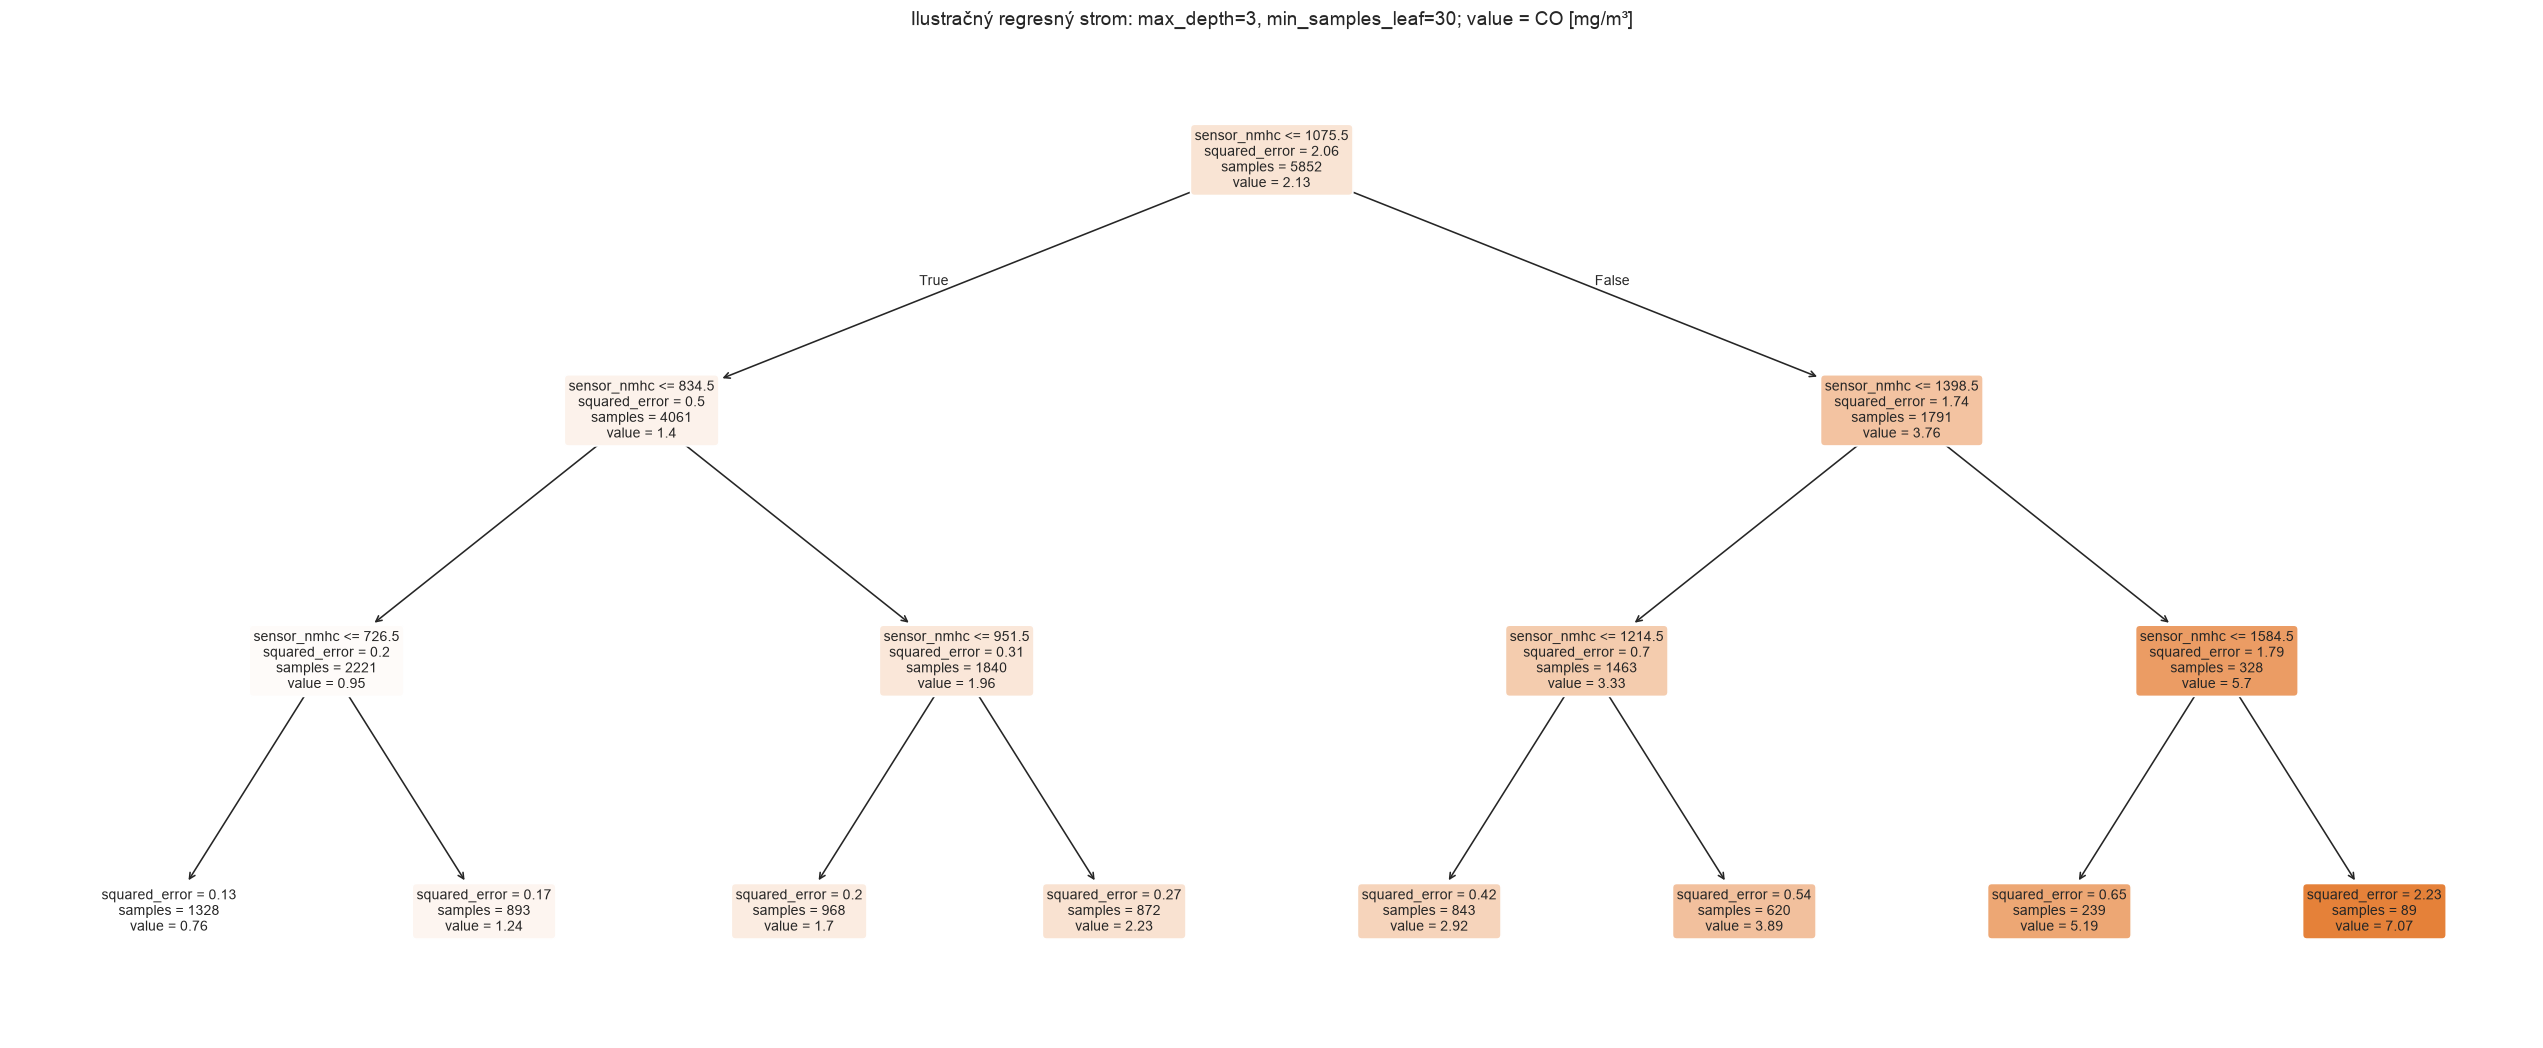

Koreň delí podľa **sensor_nmhc ≤ 1075.50**. Ľavá vetva zodpovedá splneniu podmienky, pravá jej nesplneniu. Ilustračný strom dosahuje testovacie R² **0.8394** a RMSE 0.5769 mg/m³. Je plytký, preto ukazuje hlavné pravidlá, ale nezachytáva všetky jemné interakcie.

In [12]:
small_tree = DecisionTreeRegressor(max_depth=3,min_samples_leaf=30,random_state=SEED)
small_tree.fit(X_train_in[CONTINUOUS],y_train_in)
fig,ax=plt.subplots(figsize=(22,9),constrained_layout=True)
plot_tree(small_tree,feature_names=CONTINUOUS,filled=True,rounded=True,precision=2,fontsize=9,ax=ax)
ax.set_title("Ilustračný regresný strom: max_depth=3, min_samples_leaf=30; value = CO [mg/m³]")
fig.savefig(RESULTS/"decision_tree.png",dpi=160,bbox_inches="tight")
plt.show()
small_tree_metrics=regression_metrics(y_test,small_tree.predict(X_test[CONTINUOUS]))
root_feature=CONTINUOUS[small_tree.tree_.feature[0]]
root_threshold=small_tree.tree_.threshold[0]
display(Markdown(
    f"Koreň delí podľa **{root_feature} ≤ {root_threshold:.2f}**. "
    "Ľavá vetva zodpovedá splneniu podmienky, pravá jej nesplneniu. "
    f"Ilustračný strom dosahuje testovacie R² **{small_tree_metrics['R²']:.4f}** "
    f"a RMSE {small_tree_metrics['RMSE']:.4f} mg/m³. "
    "Je plytký, preto ukazuje hlavné pravidlá, ale nezachytáva všetky jemné interakcie."
))

### Ukážka stromu z Random Forestu

Zobrazím prvé tri úrovne prvého stromu skutočne ladeného Random Forestu. Znak `(...)` označuje nezobrazené pokračovanie, nie koniec stromu. Prahy sú tu v štandardizovaných jednotkách `z`. Jednotlivý strom tvorí len jednu časť predikcie lesa; výsledná koncentrácia je priemer predikcií všetkých stromov.

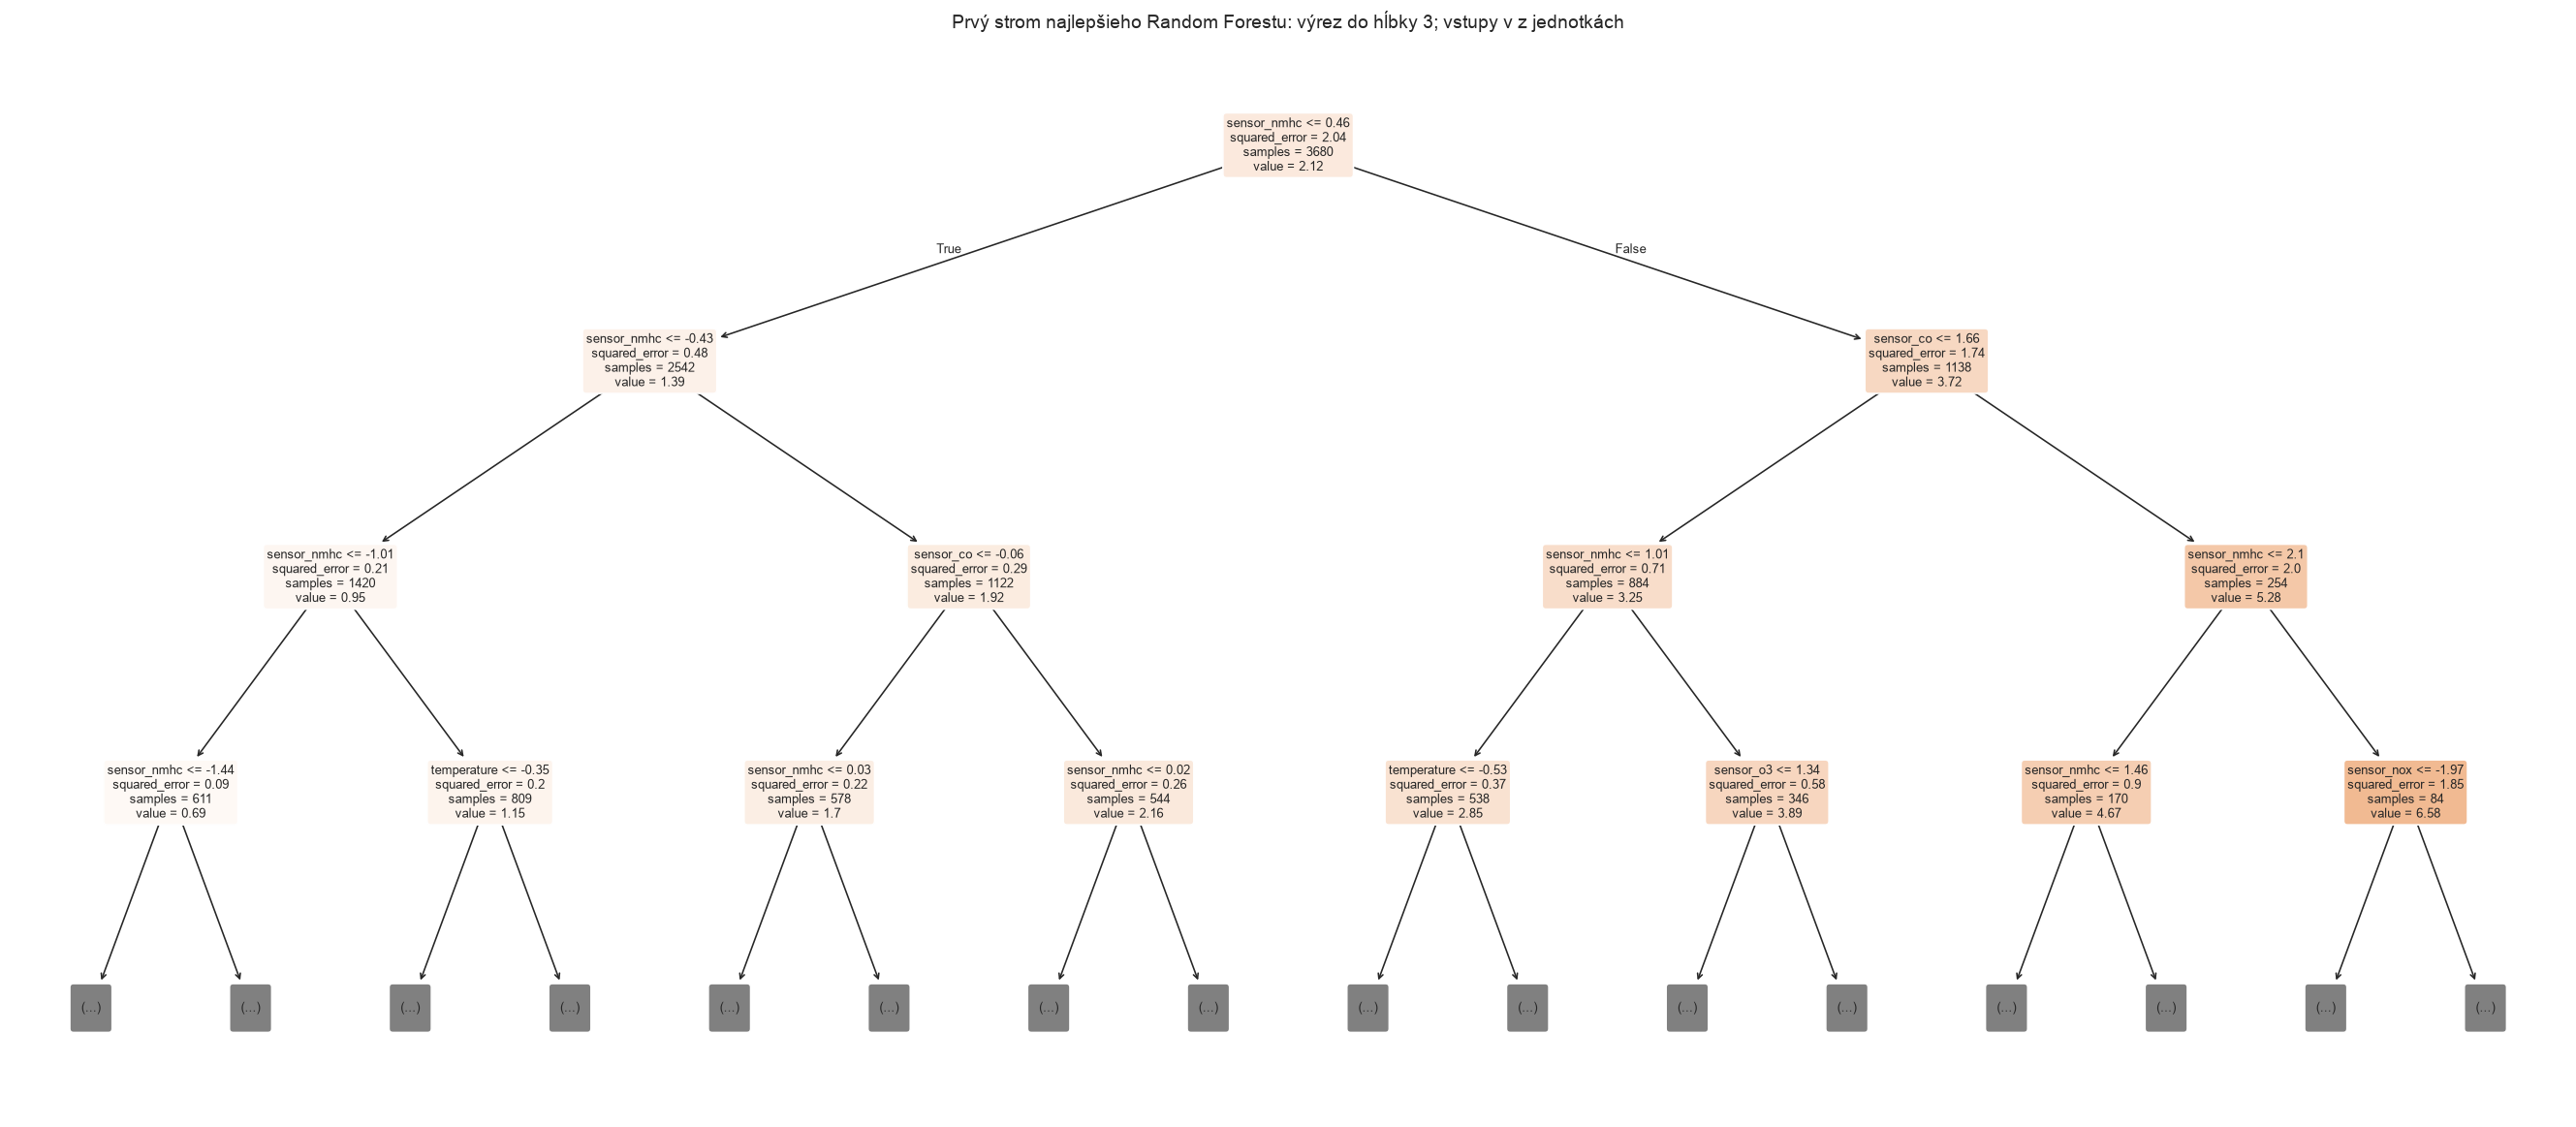

Random Forest obsahuje **200 stromov**. Zobrazený strom má skutočnú hĺbku 26 a 2760 listov. Rôzne bootstrapové vzorky a podmnožiny príznakov vytvárajú odlišné pravidlá; ich spriemerovanie obmedzuje variabilitu jedného hlbokého stromu.

In [13]:
rf_pipeline = trained_models["RandomForest"].estimator_
rf_model = rf_pipeline.named_steps["model"]
feature_names = rf_pipeline.named_steps["preprocessing"].get_feature_names_out()
fig,ax=plt.subplots(figsize=(23,10),constrained_layout=True)
plot_tree(rf_model.estimators_[0],max_depth=3,feature_names=feature_names,
          filled=True,rounded=True,precision=2,fontsize=8,ax=ax)
ax.set_title("Prvý strom najlepšieho Random Forestu: výrez do hĺbky 3; vstupy v z jednotkách")
fig.savefig(RESULTS/"random_forest_tree.png",dpi=160,bbox_inches="tight")
plt.show()
display(Markdown(
    f"Random Forest obsahuje **{rf_model.n_estimators} stromov**. "
    f"Zobrazený strom má skutočnú hĺbku {rf_model.estimators_[0].get_depth()} "
    f"a {rf_model.estimators_[0].get_n_leaves()} listov. "
    "Rôzne bootstrapové vzorky a podmnožiny príznakov vytvárajú odlišné pravidlá; "
    "ich spriemerovanie obmedzuje variabilitu jedného hlbokého stromu."
))

## Dôležitosť vstupných parametrov
### Čo znamená feature importance pri regresii CO

Dôležitosť opisuje, **ako konkrétny natrénovaný model využíva vstup**. Nejde o nemennú vlastnosť senzora: poradie závisí aj od ostatných vstupov, tréningovej vzorky a parametrov modelu. Vysoká hodnota sama nehovorí, či väčší vstup zvýši alebo zníži predikciu, ani nedokazuje príčinný vplyv na CO. Výklad nadväzuje na [mlcourse.ai: Feature importance](https://mlcourse.ai/book/topic05/topic5_part3_feature_importance.html), ale kritérium prispôsobujem **regresii**, nie klasifikácii.

### Dôležitosť podľa poklesu nečistoty: MDI

Regresný strom v každom uzle predikuje priemer tréningových koncentrácií v danom uzle. Jeho nečistota `I(t)` je priemerná štvorcová odchýlka koncentrácií od tohto priemeru. Dobré rozdelenie vytvorí skupiny s homogénnejšími hodnotami CO a zníži váženú chybu. Namiesto Giniho indexu alebo entropie preto používam `squared_error`. Príspevok delenia je:

```text
Δ(t) = (w_t / w_koreň) × [I(t) − (w_L / w_t) × I(L) − (w_R / w_t) × I(R)]
```

`L` a `R` sú deti uzla; `w` vyjadruje váhu tréningových vzoriek. V bootstrapovom strome sa opakované výbery rovnakého merania počítajú opakovane. Násobenie podielom `w_t / w_koreň` dáva väčšiu váhu zlepšeniu, ktoré sa týka väčšieho počtu meraní. Blízkosť ku koreňu je preto len intuitívna pomôcka, nie samotný výpočet dôležitosti.

**Ilustračný príklad:** koreň má 100 vzoriek a MSE 4; ľavé dieťa 60 vzoriek a MSE 1, pravé 40 vzoriek a MSE 2. Zlepšenie je:

```text
Δ(koreň) = 4 − 0,6 × 1 − 0,4 × 2 = 2,6
```

Strom spočíta príspevky všetkých delení podľa rovnakého príznaku a normalizuje ich tak, aby súčet dôležitostí bol 1. Random Forest následne spriemeruje normalizované dôležitosti stromov. Hodnota napríklad `0,616` znamená približne 61,6 % relatívneho kreditovaného zlepšenia delení, **nie** 61,6 % vysvetleného rozptylu CO ani úspešnosti modelu. Podrobný výpočet nižšie overím priamo z uzlov skutočného lesa, nielen z atribútu `feature_importances_`. [Príklad a obmedzenia MDI v scikit-learn](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html).

### Permutačná dôležitosť: čo sa stane po premiešaní vstupu

Pri permutácii model **znovu netrénujem**. Najskôr zmeriam jeho skóre, potom premiešam jeden pôvodný stĺpec medzi riadkami a skóre zmeriam znova. Informáciu v ostatných stĺpcoch ponechám. Opakujem päťkrát a uvediem priemer aj smerodajnú odchýlku:

```text
PI(j) = priemer_opakovaní [R²_pôvodné − R²_po_premiešaní_j]
```

Veľký pokles znamená, že sa model na daný vstup spolieha. Hodnota blízko nuly znamená malý dodatočný prínos v tomto modeli; malá záporná hodnota môže vzniknúť náhodou či pri rušivom vstupe. PI nie je normalizovaná na súčet 1. Pri R² môže byť väčšia než 1, pretože skóre po premiešaní môže byť záporné. Chybové úsečky zachytávajú iba variabilitu piatich permutácií, nie neistotu zo zmeny tréningového datasetu. [Definícia a interpretácia permutačnej dôležitosti](https://scikit-learn.org/stable/modules/permutation_importance.html).

V našom grafe ide o **tréningovú diagnostiku**. OOB ani nezávislé validačné skóre tu nepočítam; vysoký výsledok môže čiastočne súvisieť s prispôsobením tréningu. Pri overovaní generalizácie by bola vhodná permutácia na dátach mimo učenia. Tieto hodnoty nepoužívam na testový výber príznakov: ten neskôr prebieha vo vnútri CV.

### Prečo sa môžu oba rebríčky líšiť

MDI môže uprednostniť príznaky s mnohými možnými prahmi. Korelované senzory si zase môžu význam rozdeliť a jeden senzor môže nahrádzať druhý. Samostatná permutácia navyše môže vytvoriť nereálne kombinácie senzorov. Nízka samostatná dôležitosť preto neznamená, že meranie nenesie žiadnu informáciu. [Príklad s korelovanými vstupmi](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html).

Ľavý graf pracuje so 17 kódovanými vstupmi. Pravý premiešava pôvodné stĺpce: pri `month` sa spoločne zmenia sínus aj kosínus, pri `season` všetky príslušné one-hot hodnoty. Nižšie preto MDI aj zoskupím na pôvodné stĺpce. Oba stĺpce tabuľky majú odlišnú mierku a nemožno ich odčítať ako rovnaké veličiny.

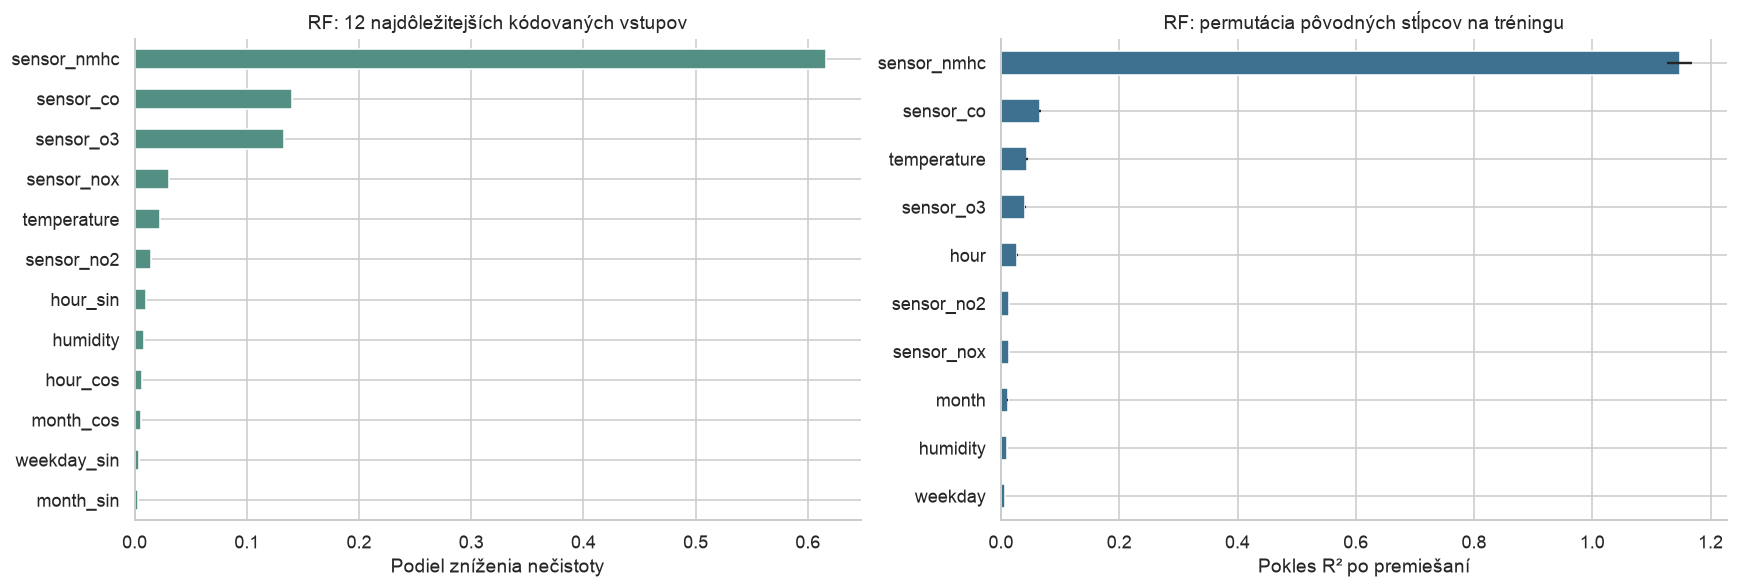

,Dôležitosť
sensor_nmhc,0.6162
sensor_co,0.1398
sensor_o3,0.1334
sensor_nox,0.0302
temperature,0.0223
sensor_no2,0.0148
hour_sin,0.0101
humidity,0.0087
hour_cos,0.0065
month_cos,0.0055


Najvyššiu uzlovú dôležitosť má **sensor_nmhc** (0.616); pri permutácii vedie **sensor_nmhc** s poklesom tréningového R² 1.148. Poradie nemusí byť totožné: jeden graf meria využívanie pri delení stromov, druhý citlivosť predikcií na porušenie daného vstupu. Korelovaný senzor môže časť informácie nahradiť.

In [14]:
rf_importance = pd.Series(rf_model.feature_importances_,index=feature_names).sort_values(ascending=False)
with threadpool_limits(limits=1):
    perm = permutation_importance(trained_models["RandomForest"],X_train,y_train,
                                 scoring="r2",n_repeats=5,random_state=SEED,n_jobs=1)
perm_table = pd.DataFrame({"Priemer":perm.importances_mean,"SD":perm.importances_std},index=X_train.columns).sort_values("Priemer",ascending=False)
fig,axes=plt.subplots(1,2,figsize=(15,5),constrained_layout=True)
rf_importance.head(12).sort_values().plot.barh(ax=axes[0],color="#538f83")
axes[0].set(title="RF: 12 najdôležitejších kódovaných vstupov",xlabel="Podiel zníženia nečistoty")
perm_table.head(10).sort_values("Priemer").plot.barh(y="Priemer",xerr="SD",ax=axes[1],legend=False,color="#3e718f")
axes[1].set(title="RF: permutácia pôvodných stĺpcov na tréningu",xlabel="Pokles R² po premiešaní")
plt.show()
display(rf_importance.rename("Dôležitosť").to_frame().round(4))
display(Markdown(
    f"Najvyššiu uzlovú dôležitosť má **{rf_importance.index[0]}** "
    f"({rf_importance.iloc[0]:.3f}); pri permutácii vedie **{perm_table.index[0]}** "
    f"s poklesom tréningového R² {perm_table.iloc[0]['Priemer']:.3f}. "
    "Poradie nemusí byť totožné: jeden graf meria využívanie pri delení stromov, druhý citlivosť "
    "predikcií na porušenie daného vstupu. Korelovaný senzor môže časť informácie nahradiť."
))

### Rozobratie skutočného stromu a čítanie výsledkov

Z interných váh a nečistôt vypočítam príspevok každého vnútorného uzla. Zobrazím desať najväčších príspevkov prvého stromu a overím, že priemer rekonštruovaných dôležitostí všetkých stromov zodpovedá scikit-learn. `Váha uzla` zahŕňa opakované výskyty z bootstrapu; nemusí byť totožná s počtom unikátnych meraní `samples` v obrázku stromu.

In [15]:
def reconstruct_tree_importance(estimator, names):
    tree = estimator.tree_
    rows = []
    total_by_feature = np.zeros(len(names))
    root_weight = tree.weighted_n_node_samples[0]
    for node in range(tree.node_count):
        left, right = tree.children_left[node], tree.children_right[node]
        if left < 0:
            continue
        weight = tree.weighted_n_node_samples[node]
        local_gain = (tree.impurity[node]
                      - tree.weighted_n_node_samples[left] / weight * tree.impurity[left]
                      - tree.weighted_n_node_samples[right] / weight * tree.impurity[right])
        weighted_gain = weight / root_weight * local_gain
        feature = tree.feature[node]
        total_by_feature[feature] += weighted_gain
        rows.append({"Uzol": node, "Príznak": names[feature],
                     "Váha uzla": weight, "I(uzol)": tree.impurity[node],
                     "I(ľavý)": tree.impurity[left], "I(pravý)": tree.impurity[right],
                     "Váha ľavého": tree.weighted_n_node_samples[left],
                     "Váha pravého": tree.weighted_n_node_samples[right],
                     "Vážené zlepšenie Δ": weighted_gain})
    if total_by_feature.sum() > 0:
        total_by_feature /= total_by_feature.sum()
    return total_by_feature, pd.DataFrame(rows)

manual_importances = []
for tree_number, estimator in enumerate(rf_model.estimators_):
    values, nodes = reconstruct_tree_importance(estimator, feature_names)
    manual_importances.append(values)
    if tree_number == 0:
        first_tree_nodes = nodes
manual_forest_importance = np.mean(manual_importances, axis=0)
manual_forest_importance /= manual_forest_importance.sum()
mdi_max_error = float(np.max(np.abs(manual_forest_importance-rf_model.feature_importances_)))
assert np.allclose(manual_forest_importance, rf_model.feature_importances_, atol=1e-12)
display(first_tree_nodes.nlargest(10, "Vážené zlepšenie Δ").round(5))

def original_feature(name):
    if name.startswith("season_"):
        return "season"
    if name.endswith("_sin") or name.endswith("_cos"):
        return name.rsplit("_", 1)[0]
    return name

mdi_grouped = rf_importance.groupby([original_feature(name) for name in rf_importance.index]).sum()
importance_comparison = (mdi_grouped.rename("MDI: podiel")
                         .to_frame().join(perm_table.rename(columns={"Priemer":"PI: pokles R²", "SD":"PI: SD"})))
importance_comparison = importance_comparison.sort_values("MDI: podiel", ascending=False)
rf_train_r2 = r2_score(y_train, trained_models["RandomForest"].predict(X_train))
importance_comparison["Priemerné R² po permutácii"] = rf_train_r2-importance_comparison["PI: pokles R²"]
display(importance_comparison.round(5))
importance_comparison.to_csv(RESULTS/"feature_importance_explained.csv")
first_root = first_tree_nodes.loc[first_tree_nodes.Uzol.eq(0)].iloc[0]
top_feature = importance_comparison.index[0]
top_info = importance_comparison.iloc[0]
display(Markdown(
    f"**Skutočný koreň prvého stromu:** delí podľa {first_root['Príznak']}. "
    f"Nečistota rodiča je {first_root['I(uzol)']:.4f}; potomkovia majú nečistoty "
    f"{first_root['I(ľavý)']:.4f} a {first_root['I(pravý)']:.4f}, s bootstrapovými váhami "
    f"{first_root['Váha ľavého']:.0f} a {first_root['Váha pravého']:.0f}. "
    f"Ich odčítaním podľa vzorca získam **Δ = {first_root['Vážené zlepšenie Δ']:.4f}**. "
    f"Maximálna odchýlka ručne rekonštruovanej dôležitosti celého lesa od knižnice je {mdi_max_error:.2e}."
))
display(Markdown(
    f"**{top_feature}** získal MDI **{top_info['MDI: podiel']:.4f}**, teda "
    f"{100*top_info['MDI: podiel']:.2f} % relatívneho kreditu za delenia. "
    f"Tréningové R² lesa pred permutáciou je {rf_train_r2:.4f}; po jeho premiešaní je v priemere "
    f"**{top_info['Priemerné R² po permutácii']:.4f}**. Rozdiel "
    f"**{top_info['PI: pokles R²']:.4f}** je meraný v jednotkách R², nie v percentách. "
    "Ak skóre po premiešaní klesne pod nulu, narušený model je na týchto meraniach horší než "
    "konštantná predikcia ich priemeru. To vysvetľuje aj permutačnú dôležitosť väčšiu než 1. "
    "Výsledok svedčí o závislosti lesa od vstupu; nehovorí, že daný senzor spôsobuje zmenu CO."
))
first_tree_nodes.to_csv(RESULTS/"feature_importance_tree_nodes.csv",index=False)
(RESULTS/"feature_importance_audit.json").write_text(json.dumps({"maximum_manual_error":mdi_max_error,"mdi_sum":float(manual_forest_importance.sum()),"training_r2":float(rf_train_r2)},indent=2))

,Uzol,Príznak,Váha uzla,I(uzol),I(ľavý),I(pravý),Váha ľavého,Váha pravého,Vážené zlepšenie Δ
0,0,sensor_nmhc,5852.0,2.04486,0.47651,1.73576,4009.0,1843.0,1.17177
1800,3600,sensor_co,1843.0,1.73576,0.70509,2.00252,1418.0,425.0,0.23037
1,1,sensor_nmhc,4009.0,0.47651,0.20658,0.28954,2218.0,1791.0,0.15953
1801,3601,sensor_nmhc,1418.0,0.70509,0.36837,0.57537,875.0,543.0,0.06238
2538,5076,sensor_nmhc,425.0,2.00252,0.90456,1.84522,289.0,136.0,0.05788
2,2,sensor_nmhc,2218.0,0.20658,0.09353,0.19755,953.0,1265.0,0.02036
918,1835,sensor_co,1791.0,0.28954,0.21520,0.25814,912.0,879.0,0.01630
2686,5372,sensor_nox,136.0,1.84522,2.45234,1.09215,8.0,128.0,0.01564
2539,5077,sensor_nmhc,289.0,0.90456,0.65246,0.61739,123.0,166.0,0.01344
1802,3602,temperature,875.0,0.36837,0.52258,0.24373,192.0,683.0,0.00949


,MDI: podiel,PI: pokles R²,PI: SD,Priemerné R² po permutácii
sensor_nmhc,0.61618,1.14820,0.02106,-0.15744
sensor_co,0.13985,0.06612,0.00124,0.92463
sensor_o3,0.13340,0.04118,0.00109,0.94958
sensor_nox,0.03025,0.01290,0.00022,0.97785
temperature,0.02226,0.04387,0.00100,0.94688
hour,0.01665,0.02735,0.00073,0.96340
sensor_no2,0.01479,0.01302,0.00017,0.97773
humidity,0.00875,0.00965,0.00011,0.98111
month,0.00845,0.01103,0.00009,0.97973
weekday,0.00620,0.00726,0.00014,0.98349


**Skutočný koreň prvého stromu:** delí podľa sensor_nmhc. Nečistota rodiča je 2.0449; potomkovia majú nečistoty 0.4765 a 1.7358, s bootstrapovými váhami 4009 a 1843. Ich odčítaním podľa vzorca získam **Δ = 1.1718**. Maximálna odchýlka ručne rekonštruovanej dôležitosti celého lesa od knižnice je 1.11e-16.

**sensor_nmhc** získal MDI **0.6162**, teda 61.62 % relatívneho kreditu za delenia. Tréningové R² lesa pred permutáciou je 0.9908; po jeho premiešaní je v priemere **-0.1574**. Rozdiel **1.1482** je meraný v jednotkách R², nie v percentách. Ak skóre po premiešaní klesne pod nulu, narušený model je na týchto meraniach horší než konštantná predikcia ich priemeru. To vysvetľuje aj permutačnú dôležitosť väčšiu než 1. Výsledok svedčí o závislosti lesa od vstupu; nehovorí, že daný senzor spôsobuje zmenu CO.

122

# Redukcia dimenzie a 3D vizualizácia
## Pôvodné tri príznaky oproti trom hlavným komponentom

Vľavo zobrazím `sensor_co`, `sensor_nmhc` a `sensor_nox` **pred normalizáciou**. Vpravo sú prvé tri PCA komponenty zo všetkých 17 kódovaných a štandardizovaných vstupov. PCA učím iba na tréningových inlieroch a CO do jej výpočtu nevstupuje. Farba v oboch grafoch zodpovedá rovnakej koncentrácii CO a používa spoločnú farebnú škálu. Prehľadný graf kreslím na rovnakej podvzorke najviac 2 500 tréningových bodov.

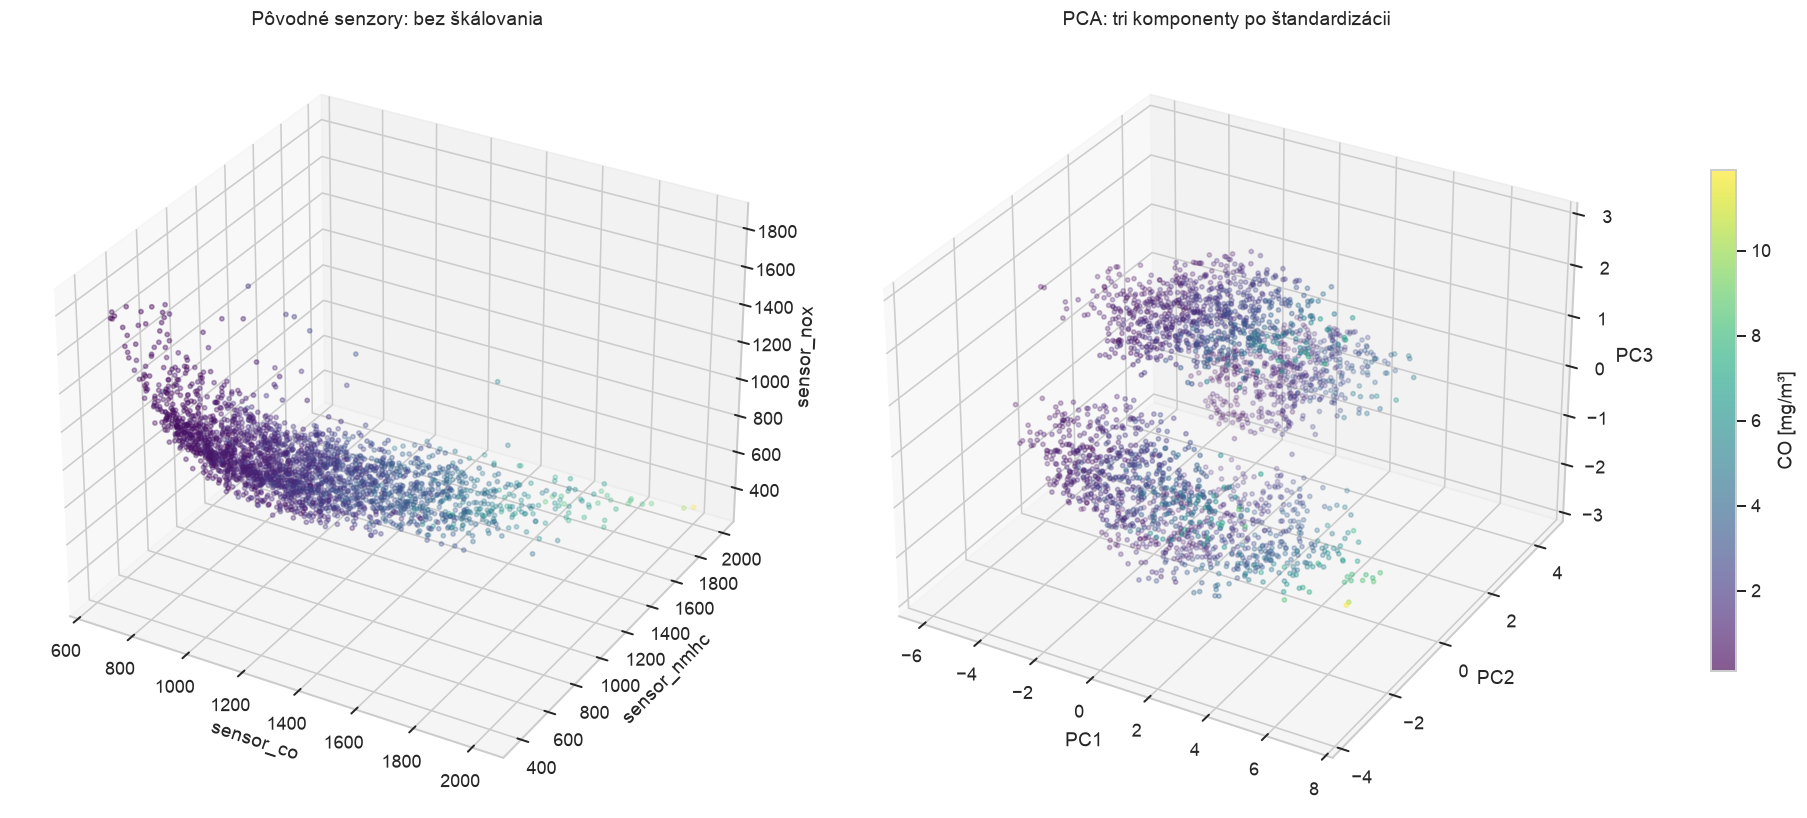

,PC1,PC2,PC3
sensor_nmhc,0.456,0.073,0.034
sensor_co,0.416,0.193,0.133
sensor_o3,0.405,0.214,0.032
sensor_no2,0.401,0.170,0.047
sensor_nox,0.396,0.153,0.031
temperature,0.184,0.455,0.069
hour_sin,0.179,0.044,0.075
weekday_cos,0.137,0.043,0.050


Tri komponenty zachovávajú **60.2% vstupnej variability** (jednotlivo 26.0%, 20.4%, 13.8%). Korelácie PC1, PC2 a PC3 s CO sú 0.848, -0.310, 0.068. V pôvodnom grafe sú vyššie koncentrácie sústredené pri vyšších odozvách sensor_co a sensor_nmhc a pri nižších odozvách sensor_nox; farebný prechod teda odhaľuje súvislosť viacerých senzorov s CO. V PCA sa hlavný farebný gradient orientuje najmä pozdĺž PC1, čo podporuje aj jeho korelácia s CO. Dva výškové pásy v projekcii nie sú dvoma cieľovými triedami: v oboch sa vyskytujú rôzne koncentrácie. PCA mieša senzory aj časové premenné, preto jej osi nemajú priamu fyzikálnu jednotku. Farebný prechod je indíciou súvislosti s CO, nie dôkazom dokonalej predikovateľnosti. PCA maximalizuje variabilitu vstupov, nie vzťah s cieľom. Znamienko komponentu je ľubovoľné a môže sa otočiť bez zmeny jeho významu.

In [16]:
projection_pipeline = Pipeline([
    ("calendar",CalendarEncoder()),("preprocessing",clone(preprocessor)),("scale",StandardScaler())])
Z_train = projection_pipeline.fit_transform(X_train_in)
Z_test = projection_pipeline.transform(X_test)
pca3 = PCA(n_components=3,svd_solver="full").fit(Z_train)
coords3 = pca3.transform(Z_train)
rng = np.random.default_rng(SEED)
show_idx = np.sort(rng.choice(len(Z_train),size=min(2500,len(Z_train)),replace=False))
shown_co = y_train_in.iloc[show_idx].to_numpy()
norm = plt.Normalize(float(y_train_in.min()),float(y_train_in.max()))
fig=plt.figure(figsize=(16,7),constrained_layout=True)
a1=fig.add_subplot(121,projection="3d")
a2=fig.add_subplot(122,projection="3d")
a1.scatter(*X_train_in.iloc[show_idx][["sensor_co","sensor_nmhc","sensor_nox"]].to_numpy().T,
           c=shown_co,cmap="viridis",norm=norm,s=7,alpha=.65)
a1.set(xlabel="sensor_co",ylabel="sensor_nmhc",zlabel="sensor_nox",title="Pôvodné senzory: bez škálovania")
sc=a2.scatter(*coords3[show_idx].T,c=shown_co,cmap="viridis",norm=norm,s=7,alpha=.65)
a2.set(xlabel="PC1",ylabel="PC2",zlabel="PC3",title="PCA: tri komponenty po štandardizácii")
fig.colorbar(sc,ax=[a1,a2],label="CO [mg/m³]",shrink=.65,pad=.06)
plt.show()
loadings = pd.DataFrame(pca3.components_.T,index=encoded_names,columns=["PC1","PC2","PC3"])
display(loadings.abs().sort_values("PC1",ascending=False).head(8).round(3))
pc_co_corr = [np.corrcoef(coords3[:,i],y_train_in)[0,1] for i in range(3)]
display(Markdown(
    f"Tri komponenty zachovávajú **{pca3.explained_variance_ratio_.sum():.1%} vstupnej variability** "
    f"(jednotlivo {', '.join(f'{v:.1%}' for v in pca3.explained_variance_ratio_)}). "
    f"Korelácie PC1, PC2 a PC3 s CO sú {', '.join(f'{v:.3f}' for v in pc_co_corr)}. "
    "V pôvodnom grafe sú vyššie koncentrácie sústredené pri vyšších odozvách sensor_co a sensor_nmhc "
    "a pri nižších odozvách sensor_nox; farebný prechod teda odhaľuje súvislosť viacerých senzorov s CO. "
    "V PCA sa hlavný farebný gradient orientuje najmä pozdĺž PC1, čo podporuje aj jeho korelácia s CO. "
    "Dva výškové pásy v projekcii nie sú dvoma cieľovými triedami: v oboch sa vyskytujú rôzne koncentrácie. "
    "PCA mieša senzory aj časové premenné, "
    "preto jej osi nemajú priamu fyzikálnu jednotku. Farebný prechod je indíciou súvislosti s CO, "
    "nie dôkazom dokonalej predikovateľnosti. PCA maximalizuje variabilitu vstupov, nie vzťah s cieľom. "
    "Znamienko komponentu je ľubovoľné a môže sa otočiť bez zmeny jeho významu."
))

## Čo je rozptyl a koľko ho PCA zachová
### Od pôvodných osí k hlavným komponentom

Rozptyl vyjadruje, ako ďaleko sa hodnoty nachádzajú od svojho priemeru. Pri viacerých vstupoch sledujem súčet ich rozptylov, teda celkovú variabilitu dátového oblaku. Po štandardizácii má každý vstup približne jednotkový rozptyl: senzor s veľkými číslami preto neovládne PCA len kvôli svojej mierke. Korelácie však štandardizácia neodstráni.

PCA vytvára nové osi ako lineárne kombinácie vstupov. PC1 má najväčší možný rozptyl, PC2 je na ňu kolmá a zachytáva najviac zo zostávajúcej variability; ďalšie komponenty pokračujú rovnakým spôsobom. Pri ponechaní všetkých komponentov ide iba o otočenie súradníc, ktoré celkový rozptyl zachová. Strata vzniká až zahodením niektorých smerov. Intuíciu projekcie rozvíja [mlcourse.ai: PCA a zhlukovanie](https://mlcourse.ai/book/topic07/topic7_pca_clustering.html).

### Vysvetlený a kumulatívny rozptyl

Vlastné číslo `λⱼ` kovariančnej matice je rozptyl súradníc v smere komponentu. Jeho pomer k súčtu všetkých vlastných čísel dáva `explained_variance_ratio_`. Kumulatívny súčet určí počet komponentov pre zvolenú hranicu:

```text
Var(x) = ∑ᵢ (xᵢ − x̄)² / (n − 1)
Celkový rozptyl = ∑ⱼ Var(zⱼ) = ∑ⱼ λⱼ
EVRⱼ = λⱼ / ∑ₗ λₗ
C_m = ∑ⱼ₌₁…m EVRⱼ
Stratený podiel rozptylu = 1 − C_m
```

`explained_variance_` obsahuje samotné rozptyly, `explained_variance_ratio_` ich podiely. PCA údaje centruje, ale automaticky neštandardizuje; škálovanie preto predchádza PCA v našej pipeline. Percentá sú podielom variability **17 vstupných stĺpcov po kódovaní a škálovaní**, nie rozptylu CO. [Dokumentácia parametrov a atribútov PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

Ľavý graf nižšie ukazuje, koľko variability nesie každý komponent samostatne. Pravý ukazuje, ako sa podiely sčítavajú. Tri komponenty sú kompromis pre kreslenie v 3D; nemusia zachytiť dostatok informácie na predikciu. Prahy 90 %, 95 % a 99 % naopak nechávajú počet komponentov vyplynúť z dát.

### Rekonštrukcia: čo sa zahodením smerov stratí

Zo zredukovaných súradníc viem dáta premietnuť späť do pôvodného štandardizovaného priestoru. Chýbajúce smery tým neobnovím: body sa rekonštruujú v ponechanej podrovine. Pri ortogonálnej PCA bez whitening na tréningových dátach platí:

```text
TSS = ∑ᵢ ‖zᵢ − z̄‖²
SSE_rekonštrukcie = ∑ᵢ ‖zᵢ − ẑᵢ‖²
SSE_rekonštrukcie / TSS = 1 − C_m
```

Túto rovnosť overím numericky. Rekonštrukčná RMSE má jednotku štandardizovaných vstupov; nie je to regresná RMSE v mg/m³. Nízka strata vstupnej variability nezaručuje malú chybu CO: aj málo variabilný smer môže niesť informáciu dôležitú pre cieľ.

,Komponent,Rozptyl λ,Podiel [%],Kumulatívne [%]
0,1,4.42182,26.00624,26.00624
1,2,3.47253,20.42318,46.42942
2,3,2.34488,13.79107,60.22049
3,4,1.47780,8.69143,68.91192
4,5,1.21682,7.15655,76.06846
5,6,1.02057,6.00231,82.07078
6,7,1.00572,5.91497,87.98575
7,8,0.88004,5.17584,93.16159
8,9,0.36569,2.15075,95.31234
9,10,0.27791,1.63446,96.94680


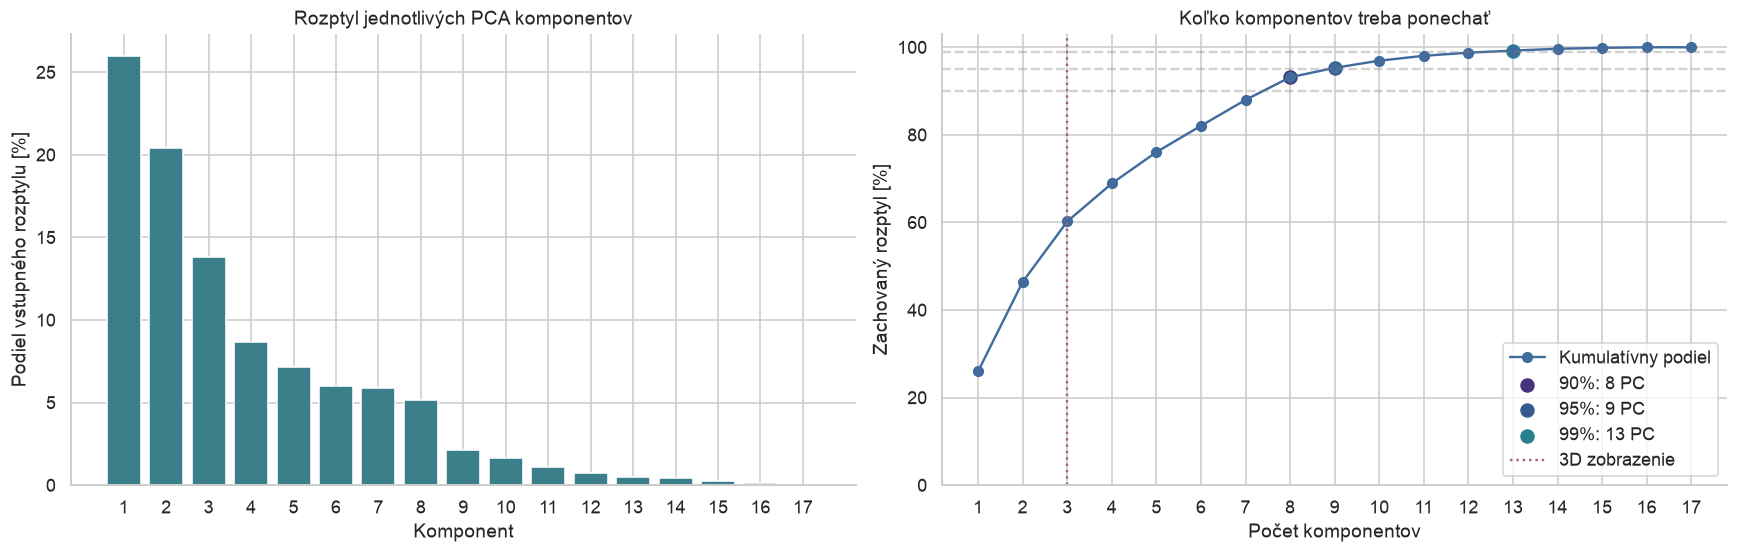

,Počet PC,Zachované [%],Stratené [%],SSE rekonštrukcie / TSS,Rekonštrukčná RMSE (z)
Voľba,,,,,
3D vizualizácia,3,60.22049,39.77951,0.39780,0.63071
Prah 90%,8,93.16159,6.83841,0.06838,0.26150
Prah 95%,9,95.31234,4.68766,0.04688,0.21651
Prah 99%,13,99.24939,0.75061,0.00751,0.08664


**3D vizualizácia:** 3 komponentov ponechá **60.22 %** a zahodí **39.78 %** vstupnej variability. Rekonštrukčná RMSE je 0.6307 v z jednotkách. Pri pohľade na 3D zhluky teda ostáva významná časť ich geometrie mimo zobrazenia.

**Prah 90%:** 8 komponentov ponechá **93.16 %** a zahodí **6.84 %** vstupnej variability. Rekonštrukčná RMSE je 0.2615 v z jednotkách. Percento je skutočne dosiahnutý podiel: pre diskrétny počet komponentov môže presiahnuť zadaný prah.

**Prah 95%:** 9 komponentov ponechá **95.31 %** a zahodí **4.69 %** vstupnej variability. Rekonštrukčná RMSE je 0.2165 v z jednotkách. Percento je skutočne dosiahnutý podiel: pre diskrétny počet komponentov môže presiahnuť zadaný prah.

**Prah 99%:** 13 komponentov ponechá **99.25 %** a zahodí **0.75 %** vstupnej variability. Rekonštrukčná RMSE je 0.0866 v z jednotkách. Percento je skutočne dosiahnutý podiel: pre diskrétny počet komponentov môže presiahnuť zadaný prah.

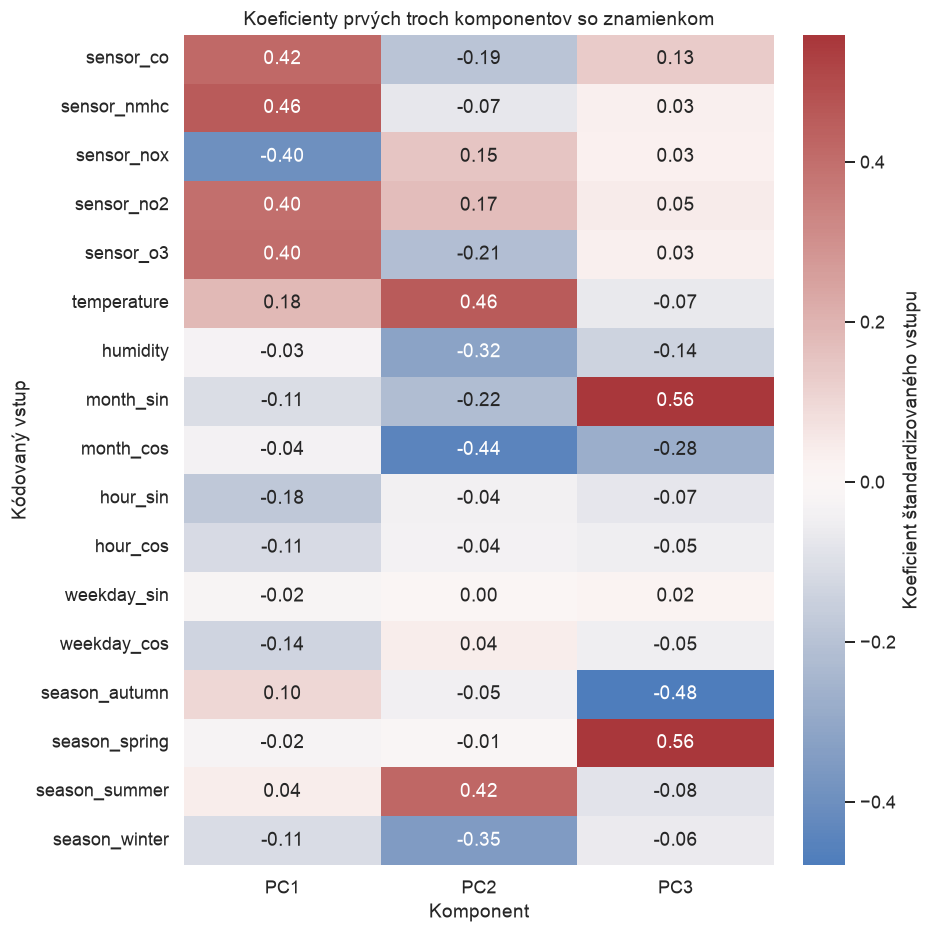

**Čítanie koeficientov:** červené a modré bunky ukazujú opačné znamienka príspevkov do komponentu. Napríklad rovnaké znamienko viacerých senzorov zachytáva ich spoločný pohyb; opačné znamienko iného senzora kontrast medzi nimi. Väčšia absolútna hodnota znamená väčší koeficient pri rovnako škálovaných vstupoch. Ide o definíciu osi, nie o feature importance pre predikciu CO. Znamienko celého stĺpca možno otočiť bez zmeny zachovaného rozptylu. Posledný komponent má rozptyl 2.81e-31; one-hot sezóny sú lineárne závislé (ich súčet je 1), takže počet stĺpcov nie je totožný s počtom nezávislých smerov variability.

In [7]:
pca_full = PCA(svd_solver="full").fit(Z_train)
full_scores = pca_full.transform(Z_train)
pca_evr = pca_full.explained_variance_ratio_
pca_cumulative = np.cumsum(pca_evr)
components_axis = np.arange(1, len(pca_evr)+1)
pca_spectrum = pd.DataFrame({"Komponent":components_axis,
    "Rozptyl λ":pca_full.explained_variance_,
    "Podiel [%]":100*pca_evr,"Kumulatívne [%]":100*pca_cumulative})
display(pca_spectrum.round(5))
pca_threshold_counts = {threshold:int(np.searchsorted(pca_cumulative,threshold,side="right")+1)
                        for threshold in [.90,.95,.99]}
fig,axes=plt.subplots(1,2,figsize=(15,4.7),constrained_layout=True)
axes[0].bar(components_axis,100*pca_evr,color="#3b7f8a")
axes[0].set(title="Rozptyl jednotlivých PCA komponentov",xlabel="Komponent",ylabel="Podiel vstupného rozptylu [%]",xticks=components_axis)
axes[1].plot(components_axis,100*pca_cumulative,marker="o",color="#416b9d",label="Kumulatívny podiel")
for threshold,count in pca_threshold_counts.items():
    axes[1].axhline(100*threshold,color="gray",alpha=.35,linestyle="--")
    axes[1].scatter([count],[100*pca_cumulative[count-1]],s=65,label=f"{threshold:.0%}: {count} PC")
axes[1].axvline(3,color="#a36271",linestyle=":",label="3D zobrazenie")
axes[1].set(title="Koľko komponentov treba ponechať",xlabel="Počet komponentov",ylabel="Zachovaný rozptyl [%]",xticks=components_axis,ylim=(0,103))
axes[1].legend(loc="lower right")
plt.show()

pca_total_ss=float(np.square(Z_train-Z_train.mean(axis=0)).sum())
variance_rows=[]
for label,count in [("3D vizualizácia",3),*[(f"Prah {t:.0%}",m) for t,m in pca_threshold_counts.items()]]:
    restored=full_scores[:,:count]@pca_full.components_[:count]+pca_full.mean_
    reconstruction_ss=float(np.square(Z_train-restored).sum())
    retained=float(pca_cumulative[count-1])
    assert np.isclose(reconstruction_ss/pca_total_ss,1-retained,atol=1e-12)
    variance_rows.append({"Voľba":label,"Počet PC":count,"Zachované [%]":100*retained,
                         "Stratené [%]":100*(1-retained),
                         "SSE rekonštrukcie / TSS":reconstruction_ss/pca_total_ss,
                         "Rekonštrukčná RMSE (z)":float(np.sqrt(np.mean(np.square(Z_train-restored))))})
pca_variance_budget=pd.DataFrame(variance_rows).set_index("Voľba")
display(pca_variance_budget.round(5))
pca_spectrum.to_csv(RESULTS/"pca_spectrum.csv",index=False)
pca_variance_budget.to_csv(RESULTS/"pca_variance_budget.csv")
assert np.isclose(pca_full.explained_variance_.sum(),Z_train.var(axis=0,ddof=1).sum())
for name,row in pca_variance_budget.iterrows():
    display(Markdown(
        f"**{name}:** {int(row['Počet PC'])} komponentov ponechá **{row['Zachované [%]']:.2f} %** "
        f"a zahodí **{row['Stratené [%]']:.2f} %** vstupnej variability. "
        f"Rekonštrukčná RMSE je {row['Rekonštrukčná RMSE (z)']:.4f} v z jednotkách. "
        + ("Pri pohľade na 3D zhluky teda ostáva významná časť ich geometrie mimo zobrazenia." if name=="3D vizualizácia" else
           "Percento je skutočne dosiahnutý podiel: pre diskrétny počet komponentov môže presiahnuť zadaný prah.")
    ))

fig,ax=plt.subplots(figsize=(8,8),constrained_layout=True)
sns.heatmap(loadings,cmap="vlag",center=0,annot=True,fmt=".2f",ax=ax,cbar_kws={"label":"Koeficient štandardizovaného vstupu"})
ax.set(title="Koeficienty prvých troch komponentov so znamienkom",xlabel="Komponent",ylabel="Kódovaný vstup")
plt.show()
display(Markdown(
    "**Čítanie koeficientov:** červené a modré bunky ukazujú opačné znamienka príspevkov do komponentu. "
    "Napríklad rovnaké znamienko viacerých senzorov zachytáva ich spoločný pohyb; opačné znamienko "
    "iného senzora kontrast medzi nimi. Väčšia absolútna hodnota znamená väčší koeficient "
    "pri rovnako škálovaných vstupoch. Ide o definíciu osi, nie o feature importance pre predikciu CO. "
    "Znamienko celého stĺpca možno otočiť bez zmeny zachovaného rozptylu. "
    f"Posledný komponent má rozptyl {pca_full.explained_variance_[-1]:.2e}; "
    "one-hot sezóny sú lineárne závislé (ich súčet je 1), takže počet stĺpcov nie je totožný "
    "s počtom nezávislých smerov variability."
))

# Výber podmnožiny príznakov
## Tri stratégie pre rovnaký najlepší model

Použijem typ modelu a hyperparametre vybrané v prvej časti podľa CV. Každú stratégiu výberu opäť vyhodnotím vo vnútornej CV a natrénujem na celom tréningu. Pôvodný model nemením. Počet príznakov pri korelácii a dôležitosti volím cez CV, pri PCA zadávam **podiel vysvetlenej variability**, nie pevne tri komponenty.

### Korelačná matica

Zostavím korelácie kódovaných vstupov s CO na danom tréningu. Vstupy zoradím podľa absolútnej korelácie s cieľom a postupne vynechám tie, ktoré majú s už vybraným vstupom absolútnu koreláciu aspoň 0,95. Tak súčasne uprednostním vzťah s cieľom a obmedzím redundanciu. Vyberám najviac 4 alebo 8 príznakov.

### Dôležitosť z ensemble

Pomocný Random Forest sa učí iba v aktuálnom tréningovom folde. Podľa jeho dôležitostí vyberiem 4 alebo 8 vstupov. Ani globálne poradie z predchádzajúceho grafu nesmie preniknúť do validačného foldu.

### PCA podľa variability

Prehľadám hodnoty 0,90, 0,95 a 0,99. PCA učím až po štandardizácii. Zachovanie 95 % variability neznamená zachovanie 95 % informácie o CO; relevantný signál môže byť aj v málo variabilnom smere.

In [18]:
class CorrelationSelector(TransformerMixin,BaseEstimator):
    def __init__(self,k=8,max_correlation=.95):
        self.k=k
        self.max_correlation=max_correlation
    def fit(self,X,y):
        values=np.asarray(X,dtype=float)
        self.n_features_in_=values.shape[1]
        matrix=pd.DataFrame(values).assign(target=np.asarray(y)).corr().fillna(0)
        relevance=matrix.target.drop("target").abs().to_numpy()
        chosen=[]
        for i in np.argsort(-relevance,kind="stable"):
            if all(abs(matrix.iloc[i,j])<self.max_correlation for j in chosen):
                chosen.append(int(i))
            if len(chosen)>=self.k:break
        self.indices_=np.array(chosen,dtype=int)
        return self
    def transform(self,X):return np.asarray(X)[:,self.indices_]

class ForestSelector(TransformerMixin,BaseEstimator):
    def __init__(self,k=8,random_state=SEED):
        self.k=k
        self.random_state=random_state
    def fit(self,X,y):
        self.n_features_in_=np.asarray(X).shape[1]
        self.forest_=RandomForestRegressor(n_estimators=120,max_features=.8,n_jobs=1,random_state=self.random_state)
        self.forest_.fit(X,y)
        self.indices_=np.argsort(-self.forest_.feature_importances_,kind="stable")[:self.k]
        return self
    def transform(self,X):return np.asarray(X)[:,self.indices_]

selection_configs={
    "Korelácia":(CorrelationSelector(),{"estimator__selection__k":[4,8]}),
    "RF dôležitosť":(ForestSelector(),{"estimator__selection__k":[4,8]}),
    "PCA variancia":(PCA(svd_solver="full"),{"estimator__selection__n_components":[.90,.95,.99]})}
reduced_models={"Všetky príznaky":best_model}
selection_rows=[{"Stratégia":"Všetky príznaky","Počet vstupov":len(encoded_names),
                 "CV MSE":float(cv_results.loc[BEST_NAME,"CV MSE"]),
                 **{"Test "+k:v for k,v in regression_metrics(y_test,best_model.predict(X_test)).items()}}]
selection_details={}
for name,(selector,grid) in selection_configs.items():
    search=GridSearchCV(make_pipeline(best_base_estimator,selector),grid,
                        scoring=SCORING,refit="mse",cv=cv,n_jobs=N_JOBS,return_train_score=True,error_score="raise")
    with parallel_backend("threading"),threadpool_limits(limits=1):search.fit(X_train,y_train)
    model=search.best_estimator_
    reduced_models[name]=model
    fitted_selector=model.estimator_.named_steps["selection"]
    count=fitted_selector.n_components_ if isinstance(fitted_selector,PCA) else len(fitted_selector.indices_)
    if isinstance(fitted_selector,PCA):
        selected_info=f"Variancia {search.best_params_['estimator__selection__n_components']}; skutočne zachované {fitted_selector.explained_variance_ratio_.sum():.4f}"
    else:
        selected_info=", ".join(encoded_names[fitted_selector.indices_])
    selection_details[name]=selected_info
    print(name,"|",search.best_params_,"|",selected_info)
    row={"Stratégia":name,"Počet vstupov":int(count),"CV MSE":-search.best_score_}
    for label,X,y in [("Train",X_train,y_train),("Test",X_test,y_test)]:
        row.update({label+" "+k:v for k,v in regression_metrics(y,model.predict(X)).items()})
    selection_rows.append(row)
# Doplním tréningové metriky referenčného modelu.
selection_rows[0].update({"Train "+k:v for k,v in regression_metrics(y_train,best_model.predict(X_train)).items()})
selection_results=pd.DataFrame(selection_rows).set_index("Stratégia")
display(selection_results.round(4))
selection_results.to_csv(RESULTS/"feature_selection_metrics.csv")
for name,row in selection_results.iterrows():
    delta=row["Test RMSE"]-selection_results.loc["Všetky príznaky","Test RMSE"]
    display(Markdown(
        f"**{name}:** {int(row['Počet vstupov'])} vstupov, testovacie R² **{row['Test R²']:.4f}**, "
        f"RMSE **{row['Test RMSE']:.4f} mg/m³**; rozdiel RMSE oproti plnému modelu {delta:+.4f} mg/m³. "
        + ("Na tomto teste zmenšenie chybu znížilo." if delta<0 else "Zmenšenie tu neprinieslo nižšiu chybu; úspora rozmerov môže stáť predikčnú informáciu." if delta>0 else "Toto je referencia pre ostatné stratégie.")
    ))

Korelácia | {'estimator__selection__k': 8} | sensor_nmhc, sensor_co, sensor_o3, sensor_nox, sensor_no2, hour_sin, weekday_cos, month_cos


RF dôležitosť | {'estimator__selection__k': 8} | sensor_nmhc, sensor_co, sensor_o3, temperature, sensor_nox, sensor_no2, hour_sin, humidity


PCA variancia | {'estimator__selection__n_components': 0.99} | Variancia 0.99; skutočne zachované 0.9925


,Počet vstupov,CV MSE,Test MSE,Test RMSE,Test MAE,Test R²,Train MSE,Train RMSE,Train MAE,Train R²
Stratégia,,,,,,,,,,
Všetky príznaky,17,0.1046,0.0947,0.3077,0.1994,0.9543,0.0350,0.1870,0.1199,0.9830
Korelácia,8,0.1533,0.1557,0.3946,0.2478,0.9248,0.1032,0.3212,0.1928,0.9499
RF dôležitosť,8,0.1506,0.1421,0.3770,0.2324,0.9314,0.1018,0.3191,0.1889,0.9506
PCA variancia,13,0.1121,0.1082,0.3289,0.2093,0.9478,0.0470,0.2168,0.1342,0.9772


**Všetky príznaky:** 17 vstupov, testovacie R² **0.9543**, RMSE **0.3077 mg/m³**; rozdiel RMSE oproti plnému modelu +0.0000 mg/m³. Toto je referencia pre ostatné stratégie.

**Korelácia:** 8 vstupov, testovacie R² **0.9248**, RMSE **0.3946 mg/m³**; rozdiel RMSE oproti plnému modelu +0.0869 mg/m³. Zmenšenie tu neprinieslo nižšiu chybu; úspora rozmerov môže stáť predikčnú informáciu.

**RF dôležitosť:** 8 vstupov, testovacie R² **0.9314**, RMSE **0.3770 mg/m³**; rozdiel RMSE oproti plnému modelu +0.0693 mg/m³. Zmenšenie tu neprinieslo nižšiu chybu; úspora rozmerov môže stáť predikčnú informáciu.

**PCA variancia:** 13 vstupov, testovacie R² **0.9478**, RMSE **0.3289 mg/m³**; rozdiel RMSE oproti plnému modelu +0.0213 mg/m³. Zmenšenie tu neprinieslo nižšiu chybu; úspora rozmerov môže stáť predikčnú informáciu.

### Prepojenie zachovaného rozptylu s regresnými výsledkami

Pri výbere podľa korelácie alebo RF dôležitosti ponechávam pôvodné kódované osi. Tieto metódy nemajú predpísanú záruku zachovania určitého podielu celkovej variability; sledujú súvislosť s cieľom alebo využívanie vstupov modelom. PCA namiesto toho vytvára nové osi a má explicitný limit straty rozptylu.

V tomto experimente PCA s hranicou 99 % ponechalo 13 komponentov a skutočne zachovalo približne 99,25 % vstupnej variability. Aj tak testovacia RMSE SVR vzrástla približne z 0,3077 na 0,3289 mg/m³. Strata len 0,75 % vstupného rozptylu teda **neznamená** rovnakú relatívnu zmenu regresnej chyby. PCA nepozná CO a nemôže zaručiť, že zahodí iba nepotrebnú informáciu. Naproti tomu tri komponenty pre obrázok zachovávajú len približne 60,2 %, preto ich nepovažujem za rovnocennú náhradu zvolenej 13D regresnej reprezentácie.

## Reziduály po redukcii

Rovnaké testovacie riadky a spoločné osi umožňujú porovnať, či redukcia zväčšuje rozptyl alebo podhodnotenie pri vysokom CO. Korelačný výber zachytáva lineárny vzťah s cieľom, ensemble aj nelinearity, PCA predovšetkým veľké smery variability. Preto ich poradie podľa zachovanej variability nemusí súhlasiť s poradím predikčnej chyby.

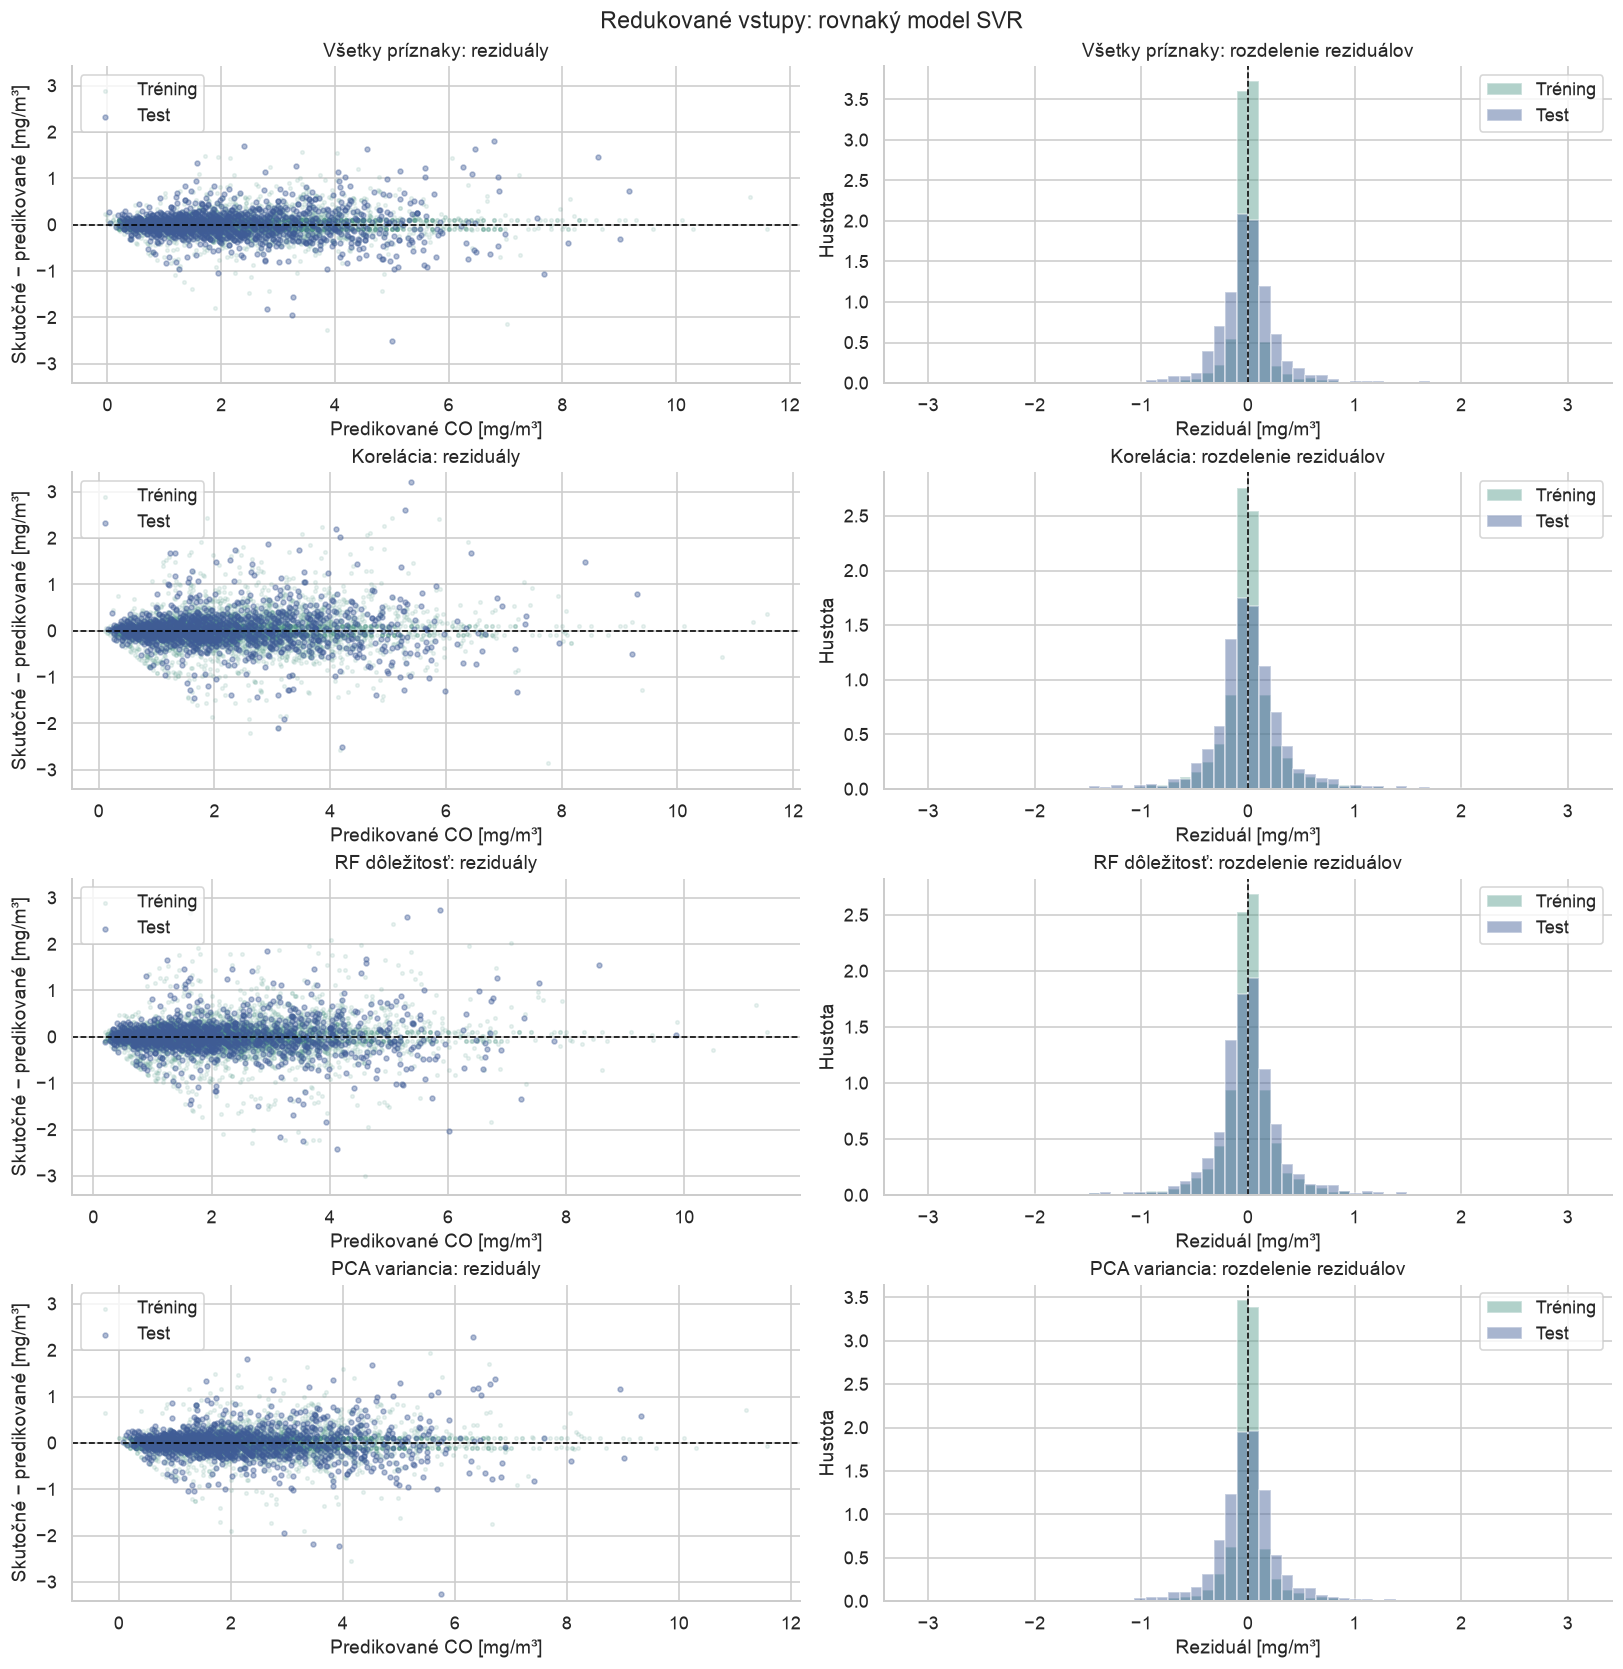

,Priemer reziduála,Medián reziduála,95. percentil |e|,Korelácia |e| a predikcie
Model,,,,
Všetky príznaky,0.0019,-0.0040,0.6502,0.4270
Korelácia,0.0149,-0.0027,0.7978,0.3659
RF dôležitosť,0.0030,-0.0006,0.7707,0.3580
PCA variancia,0.0001,-0.0023,0.6800,0.3972


**Všetky príznaky:** priemerný testovací reziduál 0.0019 mg/m³ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.650 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.427; chyby majú tendenciu rásť s predikovanou koncentráciou.

**Korelácia:** priemerný testovací reziduál 0.0149 mg/m³ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.798 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.366; chyby majú tendenciu rásť s predikovanou koncentráciou.

**RF dôležitosť:** priemerný testovací reziduál 0.0030 mg/m³ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.771 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.358; chyby majú tendenciu rásť s predikovanou koncentráciou.

**PCA variancia:** priemerný testovací reziduál 0.0001 mg/m³ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.680 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.397; chyby majú tendenciu rásť s predikovanou koncentráciou.

In [19]:
selection_residuals=plot_residuals(reduced_models,f"Redukované vstupy: rovnaký model {BEST_NAME}")

# Zhlukovanie a lokálne regresné modely
## K-means bez výstupnej premennej
### Výber počtu zhlukov a zobrazenie

K-means naučím na **všetkých 17 štandardizovaných vstupoch**, bez CO a iba z tréningových inlierov. Porovnám 3, 4 a 5 zhlukov pomocou silhouette skóre na rovnakej tréningovej podvzorke. Vyberiem najvyššie skóre, nie najlepšiu regresiu na teste. Každý bod na 3D grafe má farbu zhluku; osi sú iba tri PCA súradnice, takže zhlukovanie využíva viac príznakov než vizualizácia. Prekryv v projekcii nemusí znamenať prekryv v plnom priestore.

### Čo pri zhlukovaní znamená rozptyl

PCA vyberá smery zachovávajúce čo najviac vstupnej variability. K-means má inú úlohu: prideľuje body k centroidom tak, aby boli **vnútri skupiny čo najbližšie**. Strieda priradenie bodov k najbližšiemu centroidu a presun centroidu na priemer priradených bodov. Používam 20 inicializácií, pretože výsledok môže závisieť od počiatočných centroidov. [Intuícia zhlukovania v mlcourse.ai](https://mlcourse.ai/book/topic07/topic7_pca_clustering.html), [kritérium inertia v scikit-learn](https://scikit-learn.org/stable/modules/clustering.html#k-means).

Samotným pridelením štítka zhluku sa žiadny vstup ani jeho rozptyl nestráca: lokálne regresné modely stále dostanú všetky vstupy. **Až keby som každý bod nahradil centroidom**, zmizla by jeho odchýlka od priemeru skupiny. Túto hypotetickú stratu kvantifikujem rozkladom súčtu štvorcov vzdialeností:

```text
TSS = ∑ᵢ ‖zᵢ − z̄‖²                         celkový rozptyl dátového oblaku
WSS = ∑ₖ ∑ᵢ∈Cₖ ‖zᵢ − μₖ‖²                  rozptyl vnútri zhlukov
BSS = ∑ₖ nₖ ‖μₖ − z̄‖²                      rozptyl medzi centroidmi
TSS = WSS + BSS
Podiel rozlíšený centroidmi = BSS / TSS
Podiel stratený nahradením bodov centroidmi = WSS / TSS
```

`μₖ` je priemer bodov skupiny a `nₖ` ich počet. TSS, WSS a BSS sú súčty štvorcov; po vydelení spoločným `n − 1` ide o zodpovedajúce príspevky k celkovému súčtu výberových rozptylov. Ich pomery sa nemenia. Tieto percentá opisujú **geometriu vstupov**, nie rozptyl či regresné R² koncentrácie CO.

K-means minimalizuje WSS, v knižnici označené `inertia_` pre naučené centroidy. Pre presný rozklad nižšie použijem empirické priemery konečných skupín: kvôli tolerancii zastavenia môžu mať voči uloženým centroidom malý rozdiel. Väčší počet skupín môže znižovať WSS aj bez praktického prínosu; samotný vysoký BSS/TSS preto nie je dôvodom vybrať viac zhlukov. Počet skupín naďalej volím podľa vopred určeného silhouette skóre.

### Koľko rozptylu zhlukov naozaj vidíme v 3D

Zhluky vznikajú v 17D priestore, ale graf ukazuje tri **globálne** PCA komponenty. Vypočítam zvlášť, aký podiel variability medzi centroidmi a vnútri skupín zostal v tejto projekcii. Tiež uvediem zachovaný vnútorný rozptyl každej skupiny; rovnaká 3D projekcia nemusí zachovať rovnaké percento pre všetky zhluky. PCA tu znova netrénujem po jednotlivých skupinách, preto ich súradnice zostávajú porovnateľné. Oddelenie alebo prekryv na obrázku je preto potrebné čítať spolu s týmito číslami.


,Silhouette,Inertia
k,,
3,0.1870,69255.8934
4,0.2520,59772.9587
5,0.2333,53217.3583


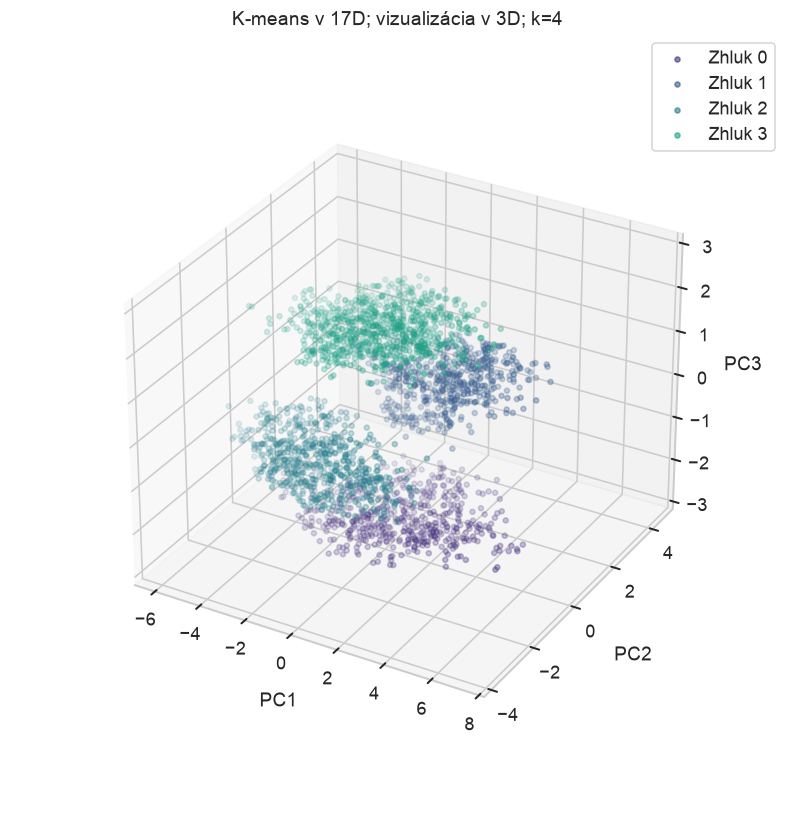

,sensor_co,sensor_nmhc,sensor_nox,sensor_no2,sensor_o3,temperature,humidity
Zhluk,,,,,,,
0,1109.5,998.5,726.0,1481.5,1101.5,19.6,57.3
1,1012.0,912.0,822.0,1632.0,858.0,27.3,37.9
2,1069.0,866.0,763.0,1122.0,1032.0,8.6,55.8
3,1126.0,917.0,842.0,1455.0,984.5,16.1,47.8


Vybral som **4 zhluky** so silhouette **0.252**. Hodnota blízko nule by znamenala slabé oddelenie, blízko jednej kompaktné oddelené skupiny. Profily ukazujú mediány pôvodných senzorov a počasia; čísla zhlukov sú ľubovoľné označenia, nie triedy zdravotnej bezpečnosti a ani intervaly CO. Cieľ sa pri ich vytváraní nepoužil.

In [20]:
cluster_candidates={}
cluster_rows=[]
for k in [3,4,5]:
    with threadpool_limits(limits=1):
        km=KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(Z_train)
        sil=silhouette_score(Z_train,km.labels_,sample_size=min(2000,len(Z_train)),random_state=SEED)
    cluster_candidates[k]=km
    cluster_rows.append({"k":k,"Silhouette":sil,"Inertia":km.inertia_})
cluster_quality=pd.DataFrame(cluster_rows).set_index("k")
K=int(cluster_quality.Silhouette.idxmax())
kmeans=cluster_candidates[K]
train_cluster=kmeans.predict(projection_pipeline.transform(X_train))
test_cluster=kmeans.predict(Z_test)
display(cluster_quality.round(4))
fig=plt.figure(figsize=(10,7),constrained_layout=True)
ax=fig.add_subplot(111,projection="3d")
for group in range(K):
    mask=kmeans.labels_[show_idx]==group
    xyz=coords3[show_idx][mask]
    ax.scatter(*xyz.T,s=10,alpha=.6,label=f"Zhluk {group}")
ax.set(xlabel="PC1",ylabel="PC2",zlabel="PC3",title=f"K-means v {Z_train.shape[1]}D; vizualizácia v 3D; k={K}")
ax.set_box_aspect((1, 1, .8), zoom=.82)
ax.set_xlabel("PC1", labelpad=12)
ax.set_ylabel("PC2", labelpad=16)
ax.set_zlabel("PC3", labelpad=10)
ax.legend()
plt.show()
profiles=X_train_in[CONTINUOUS].assign(Zhluk=kmeans.labels_).groupby("Zhluk").median()
display(profiles.round(2))
display(Markdown(
    f"Vybral som **{K} zhluky** so silhouette **{cluster_quality.loc[K,'Silhouette']:.3f}**. "
    "Hodnota blízko nule by znamenala slabé oddelenie, blízko jednej kompaktné oddelené skupiny. "
    "Profily ukazujú mediány pôvodných senzorov a počasia; čísla zhlukov sú ľubovoľné označenia, "
    "nie triedy zdravotnej bezpečnosti a ani intervaly CO. Cieľ sa pri ich vytváraní nepoužil."
))

,TSS,WSS,BSS,Inertia modelu,BSS/TSS [%],WSS/TSS [%],Silhouette
k,,,,,,,
3,99484.0,69255.84416,30228.15584,69255.89344,30.38494,69.61506,0.18696
4,99484.0,59772.95867,39711.04133,59772.95867,39.91701,60.08299,0.25197
5,99484.0,53217.28622,46266.71378,53217.35831,46.50669,53.49331,0.23333


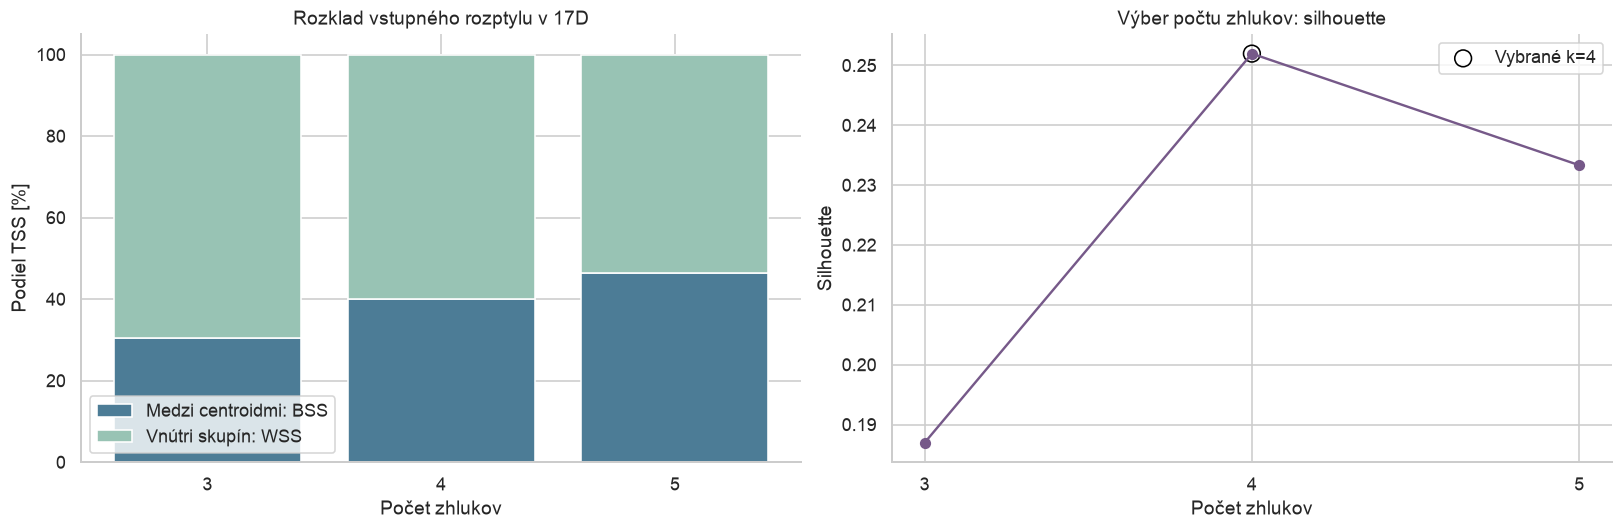

,Zachované v 3D [%]
Veličina,
Celkový rozptyl,60.2205
Rozptyl vnútri zhlukov,47.7296
Rozptyl medzi centroidmi,79.0218


,n,Rozptyl v 17D,Rozptyl v 3D,Zachovaný vnútorný rozptyl [%],Stratený vnútorný rozptyl [%]
Zhluk,,,,,
0,1292,11.5041,6.2947,54.7173,45.2827
1,1297,8.2554,3.2711,39.6243,60.3757
2,1389,10.2220,4.8409,47.3576,52.6424
3,1874,10.6962,5.0423,47.1413,52.8587


**Pri k=4** rozdiely polôh centroidov opisujú **39.92 %** celkového vstupného rozptylu; **60.08 %** zostáva vnútri skupín. Ak by sme merania nahradili iba centroidmi, práve vnútornú časť by sme stratili. V tomto notebooku ich centroidmi nenahrádzam, preto zhlukovanie samotné nespôsobilo takúto stratu. Rozdiel inertia zo zastaveného modelu a WSS podľa presných priemerov skupín je 0.000000; tak odlišujem toleranciu algoritmu od matematickej identity TSS = WSS + BSS.

**Globálna projekcia do 3D** ukazuje 60.22 % celkového rozptylu, ale osobitne **79.02 %** rozptylu medzi centroidmi a **47.73 %** rozptylu vnútri zhlukov. Graf tak nemusí rovnakou mierou zobraziť oddelenie skupín aj ich vnútornú šírku. K-means však rozhodoval podľa vzdialeností v plnom 17D priestore.

**Zhluk 0** (1292 tréningových inlierov): tri globálne komponenty zachovajú **54.72 %** jeho vnútorného rozptylu a nezobrazia 45.28 %. Ide o rozptyl štandardizovaných vstupov v tejto skupine, nie o rozptyl cieľového CO.

**Zhluk 1** (1297 tréningových inlierov): tri globálne komponenty zachovajú **39.62 %** jeho vnútorného rozptylu a nezobrazia 60.38 %. Ide o rozptyl štandardizovaných vstupov v tejto skupine, nie o rozptyl cieľového CO.

**Zhluk 2** (1389 tréningových inlierov): tri globálne komponenty zachovajú **47.36 %** jeho vnútorného rozptylu a nezobrazia 52.64 %. Ide o rozptyl štandardizovaných vstupov v tejto skupine, nie o rozptyl cieľového CO.

**Zhluk 3** (1874 tréningových inlierov): tri globálne komponenty zachovajú **47.14 %** jeho vnútorného rozptylu a nezobrazia 52.86 %. Ide o rozptyl štandardizovaných vstupov v tejto skupine, nie o rozptyl cieľového CO.

**Dôsledok pre obrázok:** medzi centroidmi leží v plnom priestore 39.92 % celkového rozptylu, ale v zobrazenej 3D projekcii je to **52.38 %**. Projekcia v tomto experimente zachovala väčšiu časť medziskupinových rozdielov než vnútornej šírky skupín. Zhluky preto môžu na obrázku pôsobiť kompaktnejšie a výraznejšie oddelené, než naznačuje geometria všetkých 17 vstupov. Silhouette je vypočítané v 17D a pomáha túto optickú interpretáciu korigovať. Vyššie BSS/TSS navyše nezaručuje nižšiu chybu CO: päť zhlukov vysvetlí viac vstupnej variability ako štyri, ale má tu nižšie silhouette. Preto automaticky nemením počet skupín ani regresný model.

In [9]:
def scatter_decomposition(values, labels):
    values=np.asarray(values,dtype=float)
    center=values.mean(axis=0)
    total=float(np.square(values-center).sum())
    within,between=0.,0.
    group_rows=[]
    for group in np.unique(labels):
        members=values[labels==group]
        centroid=members.mean(axis=0)
        group_ss=float(np.square(members-centroid).sum())
        within+=group_ss
        between+=len(members)*float(np.square(centroid-center).sum())
        group_rows.append({"Zhluk":int(group),"n":len(members),"Vnútorný SS":group_ss,
                           "Súčet vnútorných rozptylov":group_ss/(len(members)-1)})
    assert np.isclose(total,within+between,rtol=1e-12,atol=1e-8)
    return {"TSS":total,"WSS":within,"BSS":between},pd.DataFrame(group_rows).set_index("Zhluk")

cluster_variance_rows=[]
for count,candidate in cluster_candidates.items():
    split,_=scatter_decomposition(Z_train,candidate.labels_)
    cluster_variance_rows.append({"k":count,**split,
        "Inertia modelu":float(candidate.inertia_),
        "BSS/TSS [%]":100*split["BSS"]/split["TSS"],
        "WSS/TSS [%]":100*split["WSS"]/split["TSS"],
        "Silhouette":float(cluster_quality.loc[count,"Silhouette"])})
cluster_variance=pd.DataFrame(cluster_variance_rows).set_index("k")
display(cluster_variance.round(5))
fig,axes=plt.subplots(1,2,figsize=(14,4.5),constrained_layout=True)
positions=np.arange(len(cluster_variance))
axes[0].bar(positions,cluster_variance["BSS/TSS [%]"],label="Medzi centroidmi: BSS",color="#4c7c96")
axes[0].bar(positions,cluster_variance["WSS/TSS [%]"],bottom=cluster_variance["BSS/TSS [%]"],
            label="Vnútri skupín: WSS",color="#98c3b4")
axes[0].set(title="Rozklad vstupného rozptylu v 17D",ylabel="Podiel TSS [%]",xlabel="Počet zhlukov",xticks=positions,xticklabels=cluster_variance.index,ylim=(0,105))
axes[0].legend(loc="lower left")
axes[1].plot(cluster_variance.index,cluster_variance.Silhouette,marker="o",color="#765989")
axes[1].scatter([K],[cluster_variance.loc[K,"Silhouette"]],s=110,facecolors="none",edgecolors="black",label=f"Vybrané k={K}")
axes[1].set(title="Výber počtu zhlukov: silhouette",xlabel="Počet zhlukov",ylabel="Silhouette",xticks=cluster_variance.index)
axes[1].legend()
plt.show()

scatter17,groups17=scatter_decomposition(Z_train,kmeans.labels_)
scatter3,groups3=scatter_decomposition(coords3,kmeans.labels_)
cluster_projection=groups17[["n","Súčet vnútorných rozptylov"]].rename(columns={"Súčet vnútorných rozptylov":"Rozptyl v 17D"})
cluster_projection["Rozptyl v 3D"]=groups3["Súčet vnútorných rozptylov"]
cluster_projection["Zachovaný vnútorný rozptyl [%]"]=100*groups3["Vnútorný SS"]/groups17["Vnútorný SS"]
cluster_projection["Stratený vnútorný rozptyl [%]"]=100-cluster_projection["Zachovaný vnútorný rozptyl [%]"]
projection_budget=pd.DataFrame({
    "Veličina":["Celkový rozptyl", "Rozptyl vnútri zhlukov", "Rozptyl medzi centroidmi"],
    "Zachované v 3D [%]":[100*scatter3[key]/scatter17[key] for key in ["TSS","WSS","BSS"]],
}).set_index("Veličina")
display(projection_budget.round(4))
display(cluster_projection.round(4))
assert np.isclose(scatter3["TSS"]/scatter17["TSS"],pca3.explained_variance_ratio_.sum())
assert cluster_projection["Zachovaný vnútorný rozptyl [%]"].between(0,100+1e-8).all()
cluster_variance.to_csv(RESULTS/"cluster_variance_decomposition.csv")
cluster_projection.to_csv(RESULTS/"cluster_projection_variance.csv")
projection_budget.to_csv(RESULTS/"cluster_projection_budget.csv")
selected_scatter=cluster_variance.loc[K]
centroid_gap=selected_scatter["Inertia modelu"]-selected_scatter["WSS"]
display(Markdown(
    f"**Pri k={K}** rozdiely polôh centroidov opisujú **{selected_scatter['BSS/TSS [%]']:.2f} %** "
    f"celkového vstupného rozptylu; **{selected_scatter['WSS/TSS [%]']:.2f} %** zostáva vnútri skupín. "
    "Ak by sme merania nahradili iba centroidmi, práve vnútornú časť by sme stratili. "
    "V tomto notebooku ich centroidmi nenahrádzam, preto zhlukovanie samotné nespôsobilo takúto stratu. "
    f"Rozdiel inertia zo zastaveného modelu a WSS podľa presných priemerov skupín je {centroid_gap:.6f}; "
    "tak odlišujem toleranciu algoritmu od matematickej identity TSS = WSS + BSS."
))
display(Markdown(
    f"**Globálna projekcia do 3D** ukazuje {projection_budget.loc['Celkový rozptyl','Zachované v 3D [%]']:.2f} % "
    f"celkového rozptylu, ale osobitne **{projection_budget.loc['Rozptyl medzi centroidmi','Zachované v 3D [%]']:.2f} %** "
    f"rozptylu medzi centroidmi a **{projection_budget.loc['Rozptyl vnútri zhlukov','Zachované v 3D [%]']:.2f} %** "
    "rozptylu vnútri zhlukov. Graf tak nemusí rovnakou mierou zobraziť oddelenie skupín aj ich vnútornú šírku. "
    "K-means však rozhodoval podľa vzdialeností v plnom 17D priestore."
))
for group,row in cluster_projection.iterrows():
    display(Markdown(
        f"**Zhluk {group}** ({int(row['n'])} tréningových inlierov): tri globálne komponenty zachovajú "
        f"**{row['Zachovaný vnútorný rozptyl [%]']:.2f} %** jeho vnútorného rozptylu a nezobrazia "
        f"{row['Stratený vnútorný rozptyl [%]']:.2f} %. "
        "Ide o rozptyl štandardizovaných vstupov v tejto skupine, nie o rozptyl cieľového CO."
    ))
relative_between_17=scatter17["BSS"]/scatter17["TSS"]
relative_between_3=scatter3["BSS"]/scatter3["TSS"]
display(Markdown(
    f"**Dôsledok pre obrázok:** medzi centroidmi leží v plnom priestore {100*relative_between_17:.2f} % "
    f"celkového rozptylu, ale v zobrazenej 3D projekcii je to **{100*relative_between_3:.2f} %**. "
    "Projekcia v tomto experimente zachovala väčšiu časť medziskupinových rozdielov než vnútornej šírky skupín. "
    "Zhluky preto môžu na obrázku pôsobiť kompaktnejšie a výraznejšie oddelené, než naznačuje geometria "
    "všetkých 17 vstupov. Silhouette je vypočítané v 17D a pomáha túto optickú interpretáciu korigovať. "
    "Vyššie BSS/TSS navyše nezaručuje nižšiu chybu CO: päť zhlukov vysvetlí viac vstupnej variability "
    "ako štyri, ale má tu nižšie silhouette. Preto automaticky nemením počet skupín ani regresný model."
))


## Rovnaký najlepší model v každom zhluku
### Globálny model oproti lokálnym expertom

Pre každý zhluk natrénujem model **rovnakého typu a s rovnakými hyperparametrami** ako CV víťaz prvej časti. Predspracovanie a pravidlo outlierov sa znovu učia len z tréningových bodov daného zhluku. Testovací bod priradí do zhluku tréningový škálovač a K-means. Potom dostane predikciu príslušného lokálneho modelu. Na porovnanie vypočítam aj chybu pôvodného globálneho modelu na presne tých istých bodoch každého zhluku. R² v podskupine môže klesnúť aj pre menší rozsah CO; rozhodujúce je tiež spoločné MSE všetkých bodov.

,Zhluk,Hodnotenie,n,MSE,RMSE,MAE,R²
0,0,Lokálny tréning,1298,0.0165,0.1284,0.0971,0.9945
1,0,Lokálny test,328,0.1217,0.3488,0.2185,0.9564
2,0,Globálny test,328,0.0973,0.3119,0.2005,0.9652
3,1,Lokálny tréning,1298,0.0119,0.1089,0.0825,0.9889
4,1,Lokálny test,295,0.0518,0.2275,0.1527,0.9570
5,1,Globálny test,295,0.0408,0.2019,0.1405,0.9661
6,2,Lokálny tréning,1401,0.0238,0.1541,0.1087,0.9886
7,2,Lokálny test,364,0.1840,0.4289,0.2911,0.9195
8,2,Globálny test,364,0.1618,0.4022,0.2648,0.9292
9,3,Lokálny tréning,1878,0.0148,0.1216,0.0943,0.9919


,Model,Množina,MSE,RMSE,MAE,R²
0,Globálny,Tréning,0.0350,0.1870,0.1199,0.9830
1,Lokálni experti,Tréning,0.0167,0.1291,0.0957,0.9919
2,Globálny,Test,0.0947,0.3077,0.1994,0.9543
3,Lokálni experti,Test,0.1095,0.3309,0.2141,0.9472


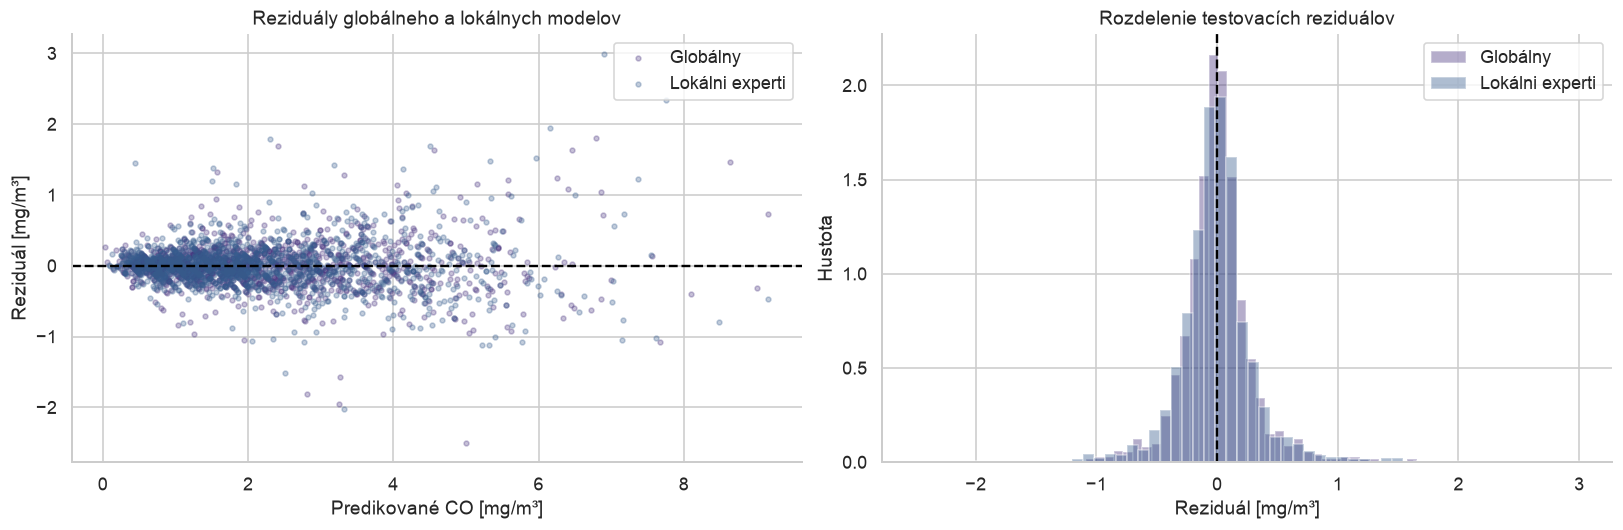

**Zhluk 0:** 328 testovacích meraní, lokálna RMSE 0.3488 oproti globálnej 0.3119 mg/m³. Rozdelenie nepomohlo chybe v tejto skupine.

**Zhluk 1:** 295 testovacích meraní, lokálna RMSE 0.2275 oproti globálnej 0.2019 mg/m³. Rozdelenie nepomohlo chybe v tejto skupine.

**Zhluk 2:** 364 testovacích meraní, lokálna RMSE 0.4289 oproti globálnej 0.4022 mg/m³. Rozdelenie nepomohlo chybe v tejto skupine.

**Zhluk 3:** 482 testovacích meraní, lokálna RMSE 0.2832 oproti globálnej 0.2742 mg/m³. Rozdelenie nepomohlo chybe v tejto skupine.

Všetci lokálni experti spolu dosahujú **R² = 0.9472**, RMSE = **0.3309 mg/m³**, oproti globálnym 0.3077 mg/m³. Zmena RMSE je +0.0232 mg/m³. Spoločné metriky sú počítané zo všetkých spojených predikcií, nie priemerovaním R² zhlukov. Lokálne modely majú menej dát a nevidia susedné režimy; segmentácia preto nemusí pomôcť ani pri viditeľných zhlukoch. Priemerný reziduál lokálnych predikcií je 0.0055 mg/m³.

In [22]:
local_models={}
local_train_prediction=np.empty(len(X_train))
local_test_prediction=np.empty(len(X_test))
cluster_eval=[]
for group in range(K):
    tr=np.flatnonzero(train_cluster==group)
    te=np.flatnonzero(test_cluster==group)
    assert len(tr)>30 and len(te)>1
    local=make_pipeline(best_base_estimator)
    with threadpool_limits(limits=1):local.fit(X_train.iloc[tr],y_train.iloc[tr])
    local_models[group]=local
    local_train_prediction[tr]=local.predict(X_train.iloc[tr])
    local_test_prediction[te]=local.predict(X_test.iloc[te])
    for label,y,p in [
        ("Lokálny tréning",y_train.iloc[tr],local_train_prediction[tr]),
        ("Lokálny test",y_test.iloc[te],local_test_prediction[te]),
        ("Globálny test",y_test.iloc[te],best_model.predict(X_test.iloc[te]))]:
        cluster_eval.append({"Zhluk":group,"Hodnotenie":label,"n":len(y),**regression_metrics(y,p)})
cluster_metrics=pd.DataFrame(cluster_eval)
display(cluster_metrics.round(4))
cluster_aggregate=pd.DataFrame([
    {"Model":"Globálny","Množina":"Tréning",**regression_metrics(y_train,best_model.predict(X_train))},
    {"Model":"Lokálni experti","Množina":"Tréning",**regression_metrics(y_train,local_train_prediction)},
    {"Model":"Globálny","Množina":"Test",**regression_metrics(y_test,best_model.predict(X_test))},
    {"Model":"Lokálni experti","Množina":"Test",**regression_metrics(y_test,local_test_prediction)},
])
display(cluster_aggregate.round(4))
cluster_metrics.to_csv(RESULTS/"cluster_metrics.csv",index=False)
cluster_aggregate.to_csv(RESULTS/"cluster_aggregate.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(14,4.5),constrained_layout=True)
for name,p in [("Globálny",best_test_pred),("Lokálni experti",local_test_prediction)]:
    e=np.asarray(y_test)-p
    axes[0].scatter(p,e,s=9,alpha=.3,label=name)
    axes[1].hist(e,bins=55,density=True,alpha=.4,label=name)
axes[0].axhline(0,color="black",linestyle="--")
axes[1].axvline(0,color="black",linestyle="--")
axes[0].set(title="Reziduály globálneho a lokálnych modelov",xlabel="Predikované CO [mg/m³]",ylabel="Reziduál [mg/m³]")
axes[1].set(title="Rozdelenie testovacích reziduálov",xlabel="Reziduál [mg/m³]",ylabel="Hustota")
for ax in axes:ax.legend()
plt.show()
local_m=regression_metrics(y_test,local_test_prediction)
global_m=regression_metrics(y_test,best_test_pred)
for group in range(K):
    group_result=cluster_metrics[(cluster_metrics.Zhluk==group)&cluster_metrics.Hodnotenie.eq("Lokálny test")].iloc[0]
    global_result=cluster_metrics[(cluster_metrics.Zhluk==group)&cluster_metrics.Hodnotenie.eq("Globálny test")].iloc[0]
    display(Markdown(
        f"**Zhluk {group}:** {int(group_result['n'])} testovacích meraní, "
        f"lokálna RMSE {group_result.RMSE:.4f} oproti globálnej {global_result.RMSE:.4f} mg/m³. "
        f"Rozdelenie {'pomohlo' if group_result.RMSE<global_result.RMSE else 'nepomohlo'} chybe v tejto skupine."
    ))
display(Markdown(
    f"Všetci lokálni experti spolu dosahujú **R² = {local_m['R²']:.4f}**, "
    f"RMSE = **{local_m['RMSE']:.4f} mg/m³**, oproti globálnym {global_m['RMSE']:.4f} mg/m³. "
    f"Zmena RMSE je {local_m['RMSE']-global_m['RMSE']:+.4f} mg/m³. "
    "Spoločné metriky sú počítané zo všetkých spojených predikcií, nie priemerovaním R² zhlukov. "
    "Lokálne modely majú menej dát a nevidia susedné režimy; segmentácia preto nemusí pomôcť ani pri viditeľných zhlukoch. "
    f"Priemerný reziduál lokálnych predikcií je {(np.asarray(y_test)-local_test_prediction).mean():.4f} mg/m³."
))

# Neurónová sieť pre regresiu
## Architektúra a vyhľadávanie
### Výstup, aktivácie a optimalizácia

Sieť má jeden **lineárny výstup koncentrácie**, bez sigmoidy a bez tried. Minimalizuje MSE v pôvodných jednotkách CO pomocou AdamW. ReLU vracia `max(0, x)`, Tanh hodnoty medzi −1 a 1 a GELU hladko váži vstup podľa normálneho rozdelenia. Zápornú predikciu po tréningu neorezávam, aby sa metrika nemenila dodatočným pravidlom.

`GridSearchCV` porovná štyri architektúry **64 → 32**, **256 → 128**, **1028 → 256 → 128** a **512 → 512 → 256 → 128**, tri aktivácie **ReLU, GELU, Tanh** a learning rate **0,001 / 0,003**. Ide o **24 konfigurácií**; z dôvodu výpočtovej náročnosti neurónová časť používa 2-fold CV a CPU s jedným vláknom. Klasické modely používali 3-fold CV, preto ich CV skóre nie sú úplne rovnocenné. Test je spoločný.

### Early stopping a finálny tréning

Každý `fit` oddelí 15 % svojich tréningových dát len na určenie počtu epoch. Vlastný vnútorný škálovač sa učí iba zo zvyšných 85 %. Po najviac 100 epochách, alebo po 10 epochách bez zlepšenia aspoň 0,0001, sa vyberie epocha najnižšej validačnej MSE. Potom vytvorím novú sieť s rovnakým seedom a trénujem ju na **všetkých dátach daného fitu** presne tento počet epoch. Tým sa early-stopping podmnožina vracia do finálneho učenia. Žiadna časť vonkajšieho testu sa na to nepoužíva.

Vo výstupe zobrazím **iba víťaznú konfiguráciu neurónovej siete**, jej krivky, metriky a reziduály; jednotlivé experimenty zostanú dostupné v objekte `nn_search.cv_results_` a v CSV. Krivky patria fáze určovania počtu epoch, finálne metriky následnému tréningu na celom tréningu.

In [23]:
class TorchRegressor(RegressorMixin,BaseEstimator):
    def __init__(self,hidden=(64,32),activation="relu",lr=.001,batch_size=256,
                 max_epochs=100,patience=10,min_delta=1e-4,weight_decay=1e-4,random_state=SEED):
        self.hidden=hidden
        self.activation=activation
        self.lr=lr
        self.batch_size=batch_size
        self.max_epochs=max_epochs
        self.patience=patience
        self.min_delta=min_delta
        self.weight_decay=weight_decay
        self.random_state=random_state

    def _network(self,inputs):
        activations={"relu":nn.ReLU,"gelu":nn.GELU,"tanh":nn.Tanh}
        layers=[]
        previous=inputs
        for width in self.hidden:
            layers.extend([nn.Linear(previous,width),activations[self.activation]()])
            previous=width
        layers.append(nn.Linear(previous,1))
        return nn.Sequential(*layers)

    def _fresh(self,inputs):
        torch.manual_seed(self.random_state)
        model=self._network(inputs)
        optimizer=torch.optim.AdamW(model.parameters(),lr=self.lr,weight_decay=self.weight_decay)
        return model,optimizer

    def _epoch(self,model,optimizer,x,y,generator):
        model.train()
        order=torch.randperm(len(x),generator=generator)
        for ids in order.split(self.batch_size):
            optimizer.zero_grad(set_to_none=True)
            loss=nn.functional.mse_loss(model(x[ids]).squeeze(1),y[ids])
            if not torch.isfinite(loss):raise RuntimeError("Neplatná strata neurónovej siete")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),10.)
            optimizer.step()

    def fit(self,X,y):
        values=np.asarray(X,dtype=np.float32)
        labels=np.asarray(y,dtype=np.float32).reshape(-1)
        self.n_features_in_=values.shape[1]
        fit_ids,stop_ids=train_test_split(np.arange(len(values)),test_size=.15,random_state=self.random_state)
        stop_scaler=StandardScaler().fit(values[fit_ids])
        fit_x=torch.tensor(stop_scaler.transform(values[fit_ids]),dtype=torch.float32)
        fit_y=torch.tensor(labels[fit_ids])
        stop_x=torch.tensor(stop_scaler.transform(values[stop_ids]),dtype=torch.float32)
        stop_y=torch.tensor(labels[stop_ids])
        model,optimizer=self._fresh(values.shape[1])
        generator=torch.Generator().manual_seed(self.random_state)
        best_loss,reference=float("inf"),float("inf")
        wait=0
        history=[]
        for epoch in range(1,self.max_epochs+1):
            self._epoch(model,optimizer,fit_x,fit_y,generator)
            model.eval()
            with torch.no_grad():
                train_loss=nn.functional.mse_loss(model(fit_x).squeeze(1),fit_y).item()
                stop_loss=nn.functional.mse_loss(model(stop_x).squeeze(1),stop_y).item()
            history.append({"Epocha":epoch,"Tréning MSE":train_loss,"Validácia MSE":stop_loss})
            if stop_loss<best_loss:
                best_loss=stop_loss
                self.selected_epoch_=epoch
            if stop_loss<reference-self.min_delta:
                reference=stop_loss
                wait=0
            else:wait+=1
            if wait>=self.patience:break
        self.history_=pd.DataFrame(history)
        self.scaler_=StandardScaler().fit(values)
        full_x=torch.tensor(self.scaler_.transform(values),dtype=torch.float32)
        full_y=torch.tensor(labels)
        self.model_,optimizer=self._fresh(values.shape[1])
        generator=torch.Generator().manual_seed(self.random_state)
        for _ in range(self.selected_epoch_):
            self._epoch(self.model_,optimizer,full_x,full_y,generator)
        self.model_.eval()
        return self

    def predict(self,X):
        self.model_.eval()
        x=torch.tensor(self.scaler_.transform(np.asarray(X,dtype=np.float32)),dtype=torch.float32)
        with torch.no_grad():return self.model_(x).squeeze(1).numpy()

nn_grid={
    "estimator__model__hidden":[(64,32),(256,128),(1028,256,128),(512,512,256,128)],
    "estimator__model__activation":["relu","gelu","tanh"],
    "estimator__model__lr":[.001,.003],
}
nn_cv=KFold(n_splits=2,shuffle=True,random_state=SEED)
nn_search=GridSearchCV(make_pipeline(TorchRegressor()),nn_grid,
    scoring=SCORING,refit="mse",cv=nn_cv,n_jobs=1,return_train_score=True,error_score="raise",verbose=0)
nn_started=time.perf_counter()
print(f"Spúšťam neurónovú mriežku: {len(ParameterGrid(nn_grid))} konfigurácií, 48 CV tréningov a finálny refit.",flush=True)
with threadpool_limits(limits=1):nn_search.fit(X_train,y_train)
nn_seconds=time.perf_counter()-nn_started
nn_best=nn_search.best_estimator_
nn_model=nn_best.estimator_.named_steps["model"]
nn_parameters={key.replace("estimator__model__",""):value for key,value in nn_search.best_params_.items()}
print("Najlepšia konfigurácia:",nn_parameters)
print("Pevné nastavenia:",{"optimizer":"AdamW","batch_size":nn_model.batch_size,"max_epochs":nn_model.max_epochs,
                           "patience":nn_model.patience,"weight_decay":nn_model.weight_decay,"seed":SEED})
print("Vybraná epocha:",nn_model.selected_epoch_,"| Počet parametrov:",sum(p.numel() for p in nn_model.model_.parameters()))
print("Čas mriežky [s]:",round(nn_seconds,1))
nn_metrics=pd.DataFrame(evaluate_model("Neurónová sieť",nn_best)).set_index("Množina")
display(nn_metrics.drop(columns="Model").round(4))
pd.DataFrame(nn_search.cv_results_).to_csv(RESULTS/"grid_neural_network.csv",index=False)
nn_metrics.to_csv(RESULTS/"neural_network_metrics.csv")
display(Markdown(
    f"Víťazná sieť má skryté vrstvy **{' → '.join(map(str,nn_parameters['hidden']))}**, "
    f"aktiváciu **{nn_parameters['activation'].upper()}** a learning rate **{nn_parameters['lr']}**. "
    f"CV RMSE je **{np.sqrt(-nn_search.best_score_):.4f} mg/m³**, "
    f"finálne testovacie R² **{nn_metrics.loc['Test','R²']:.4f}** a RMSE **{nn_metrics.loc['Test','RMSE']:.4f} mg/m³**. "
    f"Tréningové R² je {nn_metrics.loc['Tréning','R²']:.4f}. "
    "Výsledok vychádza z CV výberu, nie z výberu najlepšej siete podľa testu. "
    "Väčšia architektúra automaticky neznamená lepšiu generalizáciu, najmä na niekoľkých tisícoch meraní."
))

Spúšťam neurónovú mriežku: 24 konfigurácií, 48 CV tréningov a finálny refit.


Najlepšia konfigurácia: {'activation': 'relu', 'hidden': (1028, 256, 128), 'lr': 0.001}
Pevné nastavenia: {'optimizer': 'AdamW', 'batch_size': 256, 'max_epochs': 100, 'patience': 10, 'weight_decay': 0.0001, 'seed': 2026}
Vybraná epocha: 92 | Počet parametrov: 314953
Čas mriežky [s]: 90.8


,MSE,RMSE,MAE,R²
Množina,,,,
Tréning,0.0284,0.1684,0.1248,0.9862
Test,0.0944,0.3072,0.2113,0.9544


Víťazná sieť má skryté vrstvy **1028 → 256 → 128**, aktiváciu **RELU** a learning rate **0.001**. CV RMSE je **0.3430 mg/m³**, finálne testovacie R² **0.9544** a RMSE **0.3072 mg/m³**. Tréningové R² je 0.9862. Výsledok vychádza z CV výberu, nie z výberu najlepšej siete podľa testu. Väčšia architektúra automaticky neznamená lepšiu generalizáciu, najmä na niekoľkých tisícoch meraní.

## Diagnostika najlepšej siete
### Učenie, reziduály a porovnanie s klasickými modelmi

Krivky MSE a RMSE zobrazujú tú istú chybu v rôznych mierkach. Prerušovaná čiara označuje zvolený počet epoch. Rast validačnej chyby pri pokračujúcom poklese tréningovej je signál preučenia. Reziduály finálneho refitu následne porovnám s rovnakou definíciou ako pri ostatných regresoroch.

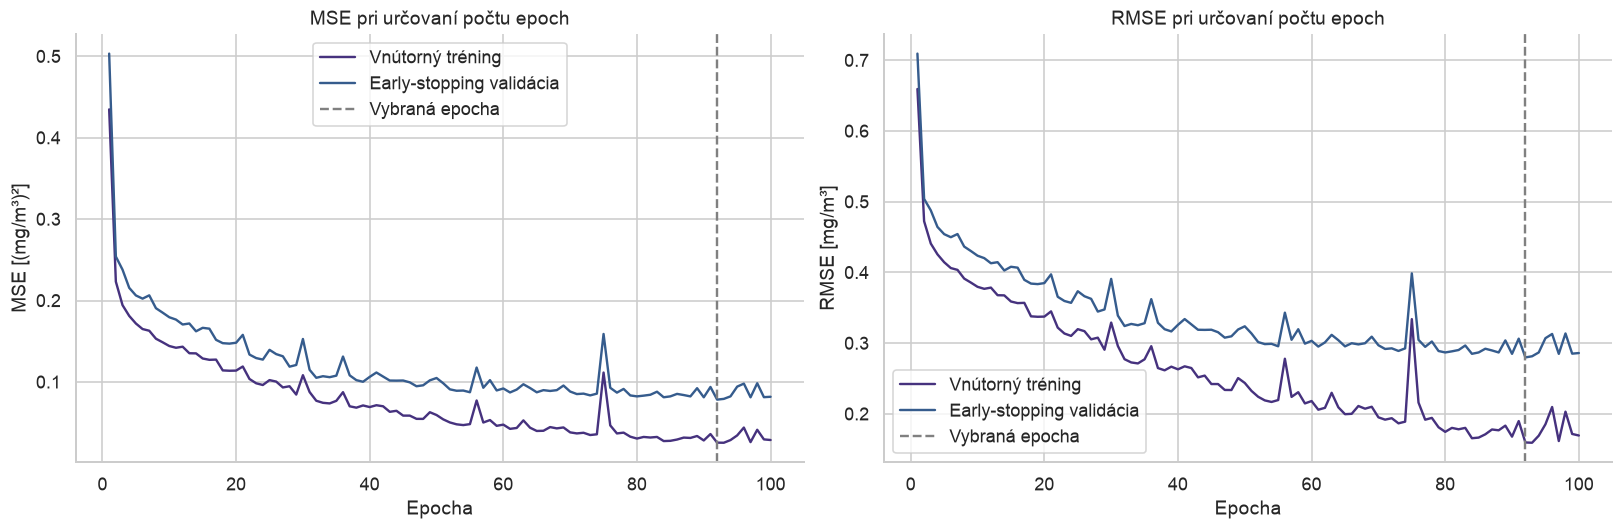

Early stopping vybral **92. epochu** z 100 vykonaných. V nej bola vnútorná tréningová MSE 0.0255 a validačná MSE 0.0783. Finálna sieť sa potom učila od začiatku na všetkých tréningových inlieroch; jej testovacie metriky preto nemusia zodpovedať minimu tejto vnútornej krivky.

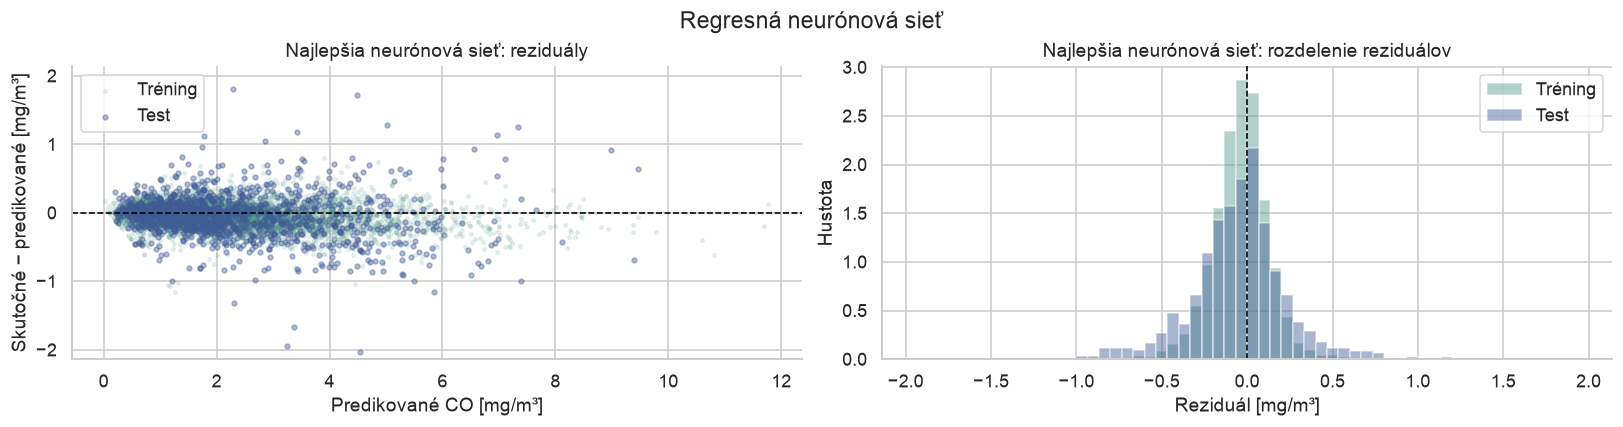

,Priemer reziduála,Medián reziduála,95. percentil |e|,Korelácia |e| a predikcie
Model,,,,
Najlepšia neurónová sieť,-0.0473,-0.0311,0.6438,0.4249


**Najlepšia neurónová sieť:** priemerný testovací reziduál -0.0473 mg/m³ znamená nadhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.644 mg/m³**. Korelácia veľkosti chyby s predikciou je 0.425; chyby majú tendenciu rásť s predikovanou koncentráciou.

Lineárny výstup vytvoril **0 záporných testovacích predikcií**. CO je fyzikálne nezáporné; záporné odhady by boli obmedzením nekontrolovaného regresného výstupu. Dodatočne ich neorezávam ani podľa nich nemením architektúru.

In [24]:
history=nn_model.history_
fig,axes=plt.subplots(1,2,figsize=(14,4.5),constrained_layout=True)
for column,label in [("Tréning MSE","Vnútorný tréning"),("Validácia MSE","Early-stopping validácia")]:
    axes[0].plot(history.Epocha,history[column],label=label)
    axes[1].plot(history.Epocha,np.sqrt(history[column]),label=label)
for ax in axes:
    ax.axvline(nn_model.selected_epoch_,color="gray",linestyle="--",label="Vybraná epocha")
    ax.set_xlabel("Epocha")
    ax.legend()
axes[0].set(title="MSE pri určovaní počtu epoch",ylabel="MSE [(mg/m³)²]")
axes[1].set(title="RMSE pri určovaní počtu epoch",ylabel="RMSE [mg/m³]")
plt.show()
selected_history=history.loc[history.Epocha.eq(nn_model.selected_epoch_)].iloc[0]
display(Markdown(
    f"Early stopping vybral **{nn_model.selected_epoch_}. epochu** z {len(history)} vykonaných. "
    f"V nej bola vnútorná tréningová MSE {selected_history['Tréning MSE']:.4f} "
    f"a validačná MSE {selected_history['Validácia MSE']:.4f}. "
    "Finálna sieť sa potom učila od začiatku na všetkých tréningových inlieroch; "
    "jej testovacie metriky preto nemusia zodpovedať minimu tejto vnútornej krivky."
))
nn_residuals=plot_residuals({"Najlepšia neurónová sieť":nn_best},"Regresná neurónová sieť")
negative_predictions=int((nn_best.predict(X_test)<0).sum())
display(Markdown(
    f"Lineárny výstup vytvoril **{negative_predictions} záporných testovacích predikcií**. "
    "CO je fyzikálne nezáporné; záporné odhady by boli obmedzením nekontrolovaného regresného výstupu. "
    "Dodatočne ich neorezávam ani podľa nich nemením architektúru."
))

# Celkové zhodnotenie
## Výsledky a hranice interpretácie

Nasledujúca tabuľka porovnáva vopred zvolené klasické modely a jedinú CV víťaznú neurónovú sieť na spoločnom teste. Závery o zhlukovaní a redukcii vychádzajú zo samostatných porovnaní vyššie. Výsledok je odhad chyby na tomto rozdelení, nie záruka rovnakého výkonu na inom senzore, lokalite či budúcom období.

In [25]:
final_test=pd.concat([test_metrics[["MSE","RMSE","MAE","R²"]],
                      nn_metrics.loc[["Test"],["MSE","RMSE","MAE","R²"]].rename(index={"Test":"Neurónová sieť"})])
display(final_test.sort_values("MSE").round(4))
final_test.to_csv(RESULTS/"final_test_comparison.csv")
best_reduced=selection_results["Test MSE"].idxmin()
comparison_word="nižšiu" if nn_metrics.loc["Test","RMSE"]<test_metrics.loc[BEST_NAME,"RMSE"] else "vyššiu"
display(Markdown(
    f"**Hlavný model vybraný podľa CV je {BEST_NAME}**, s testovacím R² "
    f"**{test_metrics.loc[BEST_NAME,'R²']:.4f}** a RMSE **{test_metrics.loc[BEST_NAME,'RMSE']:.4f} mg/m³**. "
    f"Najlepšia neurónová sieť má {comparison_word} RMSE ({nn_metrics.loc['Test','RMSE']:.4f} mg/m³). "
    f"Z porovnania redukcií má opisne najnižšiu testovaciu MSE stratégia **{best_reduced}**; "
    "nie je to ďalšie ladenie hlavného modelu. "
    f"Lokálni experti zmenili RMSE oproti globálnemu modelu o {local_m['RMSE']-global_m['RMSE']:+.4f} mg/m³.\n\n"
    "**Čo výsledky znamenajú:** senzory obsahujú silnú informáciu o CO, ale vysoké koncentrácie "
    "a odľahlé merania ostávajú náročnejšie. Hodnotenie zachováva všetky platné testovacie extrémy. "
    "Čistenie odstránilo neúplné merania, a tým mohlo zmeniť zastúpenie prevádzkových podmienok. "
    "Náhodná CV mieša susedné hodiny; pred nasadením na budúce obdobie by bolo potrebné "
    "chronologické delenie s časovou medzerou a samostatné overenie driftu senzorov. "
    "Rozdiely malých hodnôt RMSE bez opakovaných časových experimentov nemožno považovať za stabilné poradie."
))

,MSE,RMSE,MAE,R²
Neurónová sieť,0.0944,0.3072,0.2113,0.9544
SVR,0.0947,0.3077,0.1994,0.9543
XGBoost,0.1204,0.3470,0.2241,0.9419
HistGradientBoosting,0.1210,0.3478,0.2283,0.9416
ExtraTrees,0.1216,0.3486,0.2221,0.9413
RandomForest,0.1402,0.3744,0.2354,0.9323
DecisionTree,0.2007,0.4480,0.3004,0.9031
Baseline,2.0731,1.4398,1.1093,-0.0007


**Hlavný model vybraný podľa CV je SVR**, s testovacím R² **0.9543** a RMSE **0.3077 mg/m³**. Najlepšia neurónová sieť má nižšiu RMSE (0.3072 mg/m³). Z porovnania redukcií má opisne najnižšiu testovaciu MSE stratégia **Všetky príznaky**; nie je to ďalšie ladenie hlavného modelu. Lokálni experti zmenili RMSE oproti globálnemu modelu o +0.0232 mg/m³.

**Čo výsledky znamenajú:** senzory obsahujú silnú informáciu o CO, ale vysoké koncentrácie a odľahlé merania ostávajú náročnejšie. Hodnotenie zachováva všetky platné testovacie extrémy. Čistenie odstránilo neúplné merania, a tým mohlo zmeniť zastúpenie prevádzkových podmienok. Náhodná CV mieša susedné hodiny; pred nasadením na budúce obdobie by bolo potrebné chronologické delenie s časovou medzerou a samostatné overenie driftu senzorov. Rozdiely malých hodnôt RMSE bez opakovaných časových experimentov nemožno považovať za stabilné poradie.

## Kontrola požiadaviek zadania

Kontrola nižšie overí pozitívne testovacie R² všetkých šiestich ladených klasických modelov a dosiahnutie aspoň 0,7 pri CV víťazovi. Ďalej kontroluje, že cieľ nebol vstupom modelov, redukcia má skutočne menej rozmerov, zhluky pokrývajú každý testovací bod a neurónová mriežka skutočne obsahovala všetky požadované architektúry aj aktivácie. Tieto kontroly dopĺňajú, nenahrádzajú interpretáciu grafov.

In [26]:
assert (test_metrics.loc[list(model_configs),"R²"]>0).all()
assert test_metrics.loc[BEST_NAME,"R²"]>=.7
assert TARGET not in X_train.columns
assert len(y_test)==len(local_test_prediction) and np.isfinite(local_test_prediction).all()
assert K>=3 and Z_train.shape[1]>3
assert pca3.n_components_==3
assert (selection_results.drop(index="Všetky príznaky")["Počet vstupov"]<len(encoded_names)).all()
assert isinstance(reduced_models["PCA variancia"].estimator_.named_steps["selection"].n_components,float)
assert (1028,256,128) in nn_grid["estimator__model__hidden"]
assert (512,512,256,128) in nn_grid["estimator__model__hidden"]
assert set(nn_grid["estimator__model__activation"])=={"relu","gelu","tanh"}
assert len(nn_search.cv_results_["params"])==24
assert np.isfinite(nn_best.predict(X_test)).all()
audit={"best_model":BEST_NAME,"best_test_metrics":regression_metrics(y_test,best_test_pred),
       "nn_test_metrics":regression_metrics(y_test,nn_best.predict(X_test)),
       "nn_best_params":nn_parameters,"nn_configurations":24,
       "clusters":K,"rows_raw":len(data),"rows_clean":len(data_clean),
       "train_rows":len(X_train),"test_rows":len(X_test),"training_outliers_removed":preparation_demo.n_removed_,
       "encoded_features":len(encoded_names),"versions":versions,"seed":SEED}
(RESULTS/"audit.json").write_text(json.dumps(audit,ensure_ascii=False,indent=2),encoding="utf-8")
print("Kontroly splnené. Tabuľky, audit a dva obrázky stromov sú v priečinku results/.")

Kontroly splnené. Tabuľky, audit a dva obrázky stromov sú v priečinku results/.


## Zdroje a reprodukcia

- Špecifikácia: lokálny súbor `SUNS_zadanie2_2026.pdf`; dáta: `air_quality.csv` z AIS.
- Štruktúra a štýl experimentov: vlastné riešenie úlohy 01 v `../01/main.ipynb`.
- [scikit-learn: GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) — mriežka parametrov a CV výber.
- [scikit-learn: bežné chyby a únik informácií](https://scikit-learn.org/stable/common_pitfalls.html) — predspracovanie v pipeline a oddelenie testu.
- [XGBoost: Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html) — regresný stromový boosting.
- [PyTorch: neurónové vrstvy](https://docs.pytorch.org/docs/stable/nn.html) — Linear, ReLU, GELU, Tanh a MSELoss.

Pre reprodukciu spusti všetky bunky v poradí v kerneli `ml-course`. Kompletný výpočet vrátane 24 konfigurácií neurónovej siete môže trvať niekoľko minút až desiatky minút podľa CPU. CSV sú pomocné exporty; notebook obsahuje kód aj zobrazené výsledky samostatne.

Podrobnejší výklad dôležitosti príznakov a rozptylu dopĺňajú:

- [mlcourse.ai: Feature importance](https://mlcourse.ai/book/topic05/topic5_part3_feature_importance.html).
- [mlcourse.ai: PCA and clustering](https://mlcourse.ai/book/topic07/topic7_pca_clustering.html).
- [scikit-learn: príklad MDI a permutačnej dôležitosti](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html).
- [scikit-learn: korelované vstupy a permutácia](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html).

Číselné ukážky rozkladu dôležitosti, rekonštrukcie PCA a rozptylu zhlukov sú vypočítané priamo z dát a modelov tohto notebooku.
